# HealthConnect Rwanda — Healthcare Predictive Analytics & Population Health Intelligence
**AnalystLab Africa · Experience Lab · Week 6 · Track 2 — Data Science**

This notebook covers every section of the Data Science brief, in order:
1. Data preparation (loading, cleaning, validation, integration) · 2. Feature engineering ·
3. Exploratory analysis · 4. Statistical analysis · 5. Predictive analytics & forecasting ·
6. Clustering & PCA · 7. Business recommendations.

**Reading guide.** The 27 source datasets are *relationally inconsistent* in several important ways
(documented in section 1.4). Every analysis states which records it uses and how many, and every
interpretation caption is generated from the computed numbers, so conclusions always match the evidence.

In [1]:
import warnings, os, re, json, textwrap, math, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
import seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

DATA, OUT = "data/", "outputs/"
FIGDIR = OUT + "figures/"
os.makedirs(FIGDIR, exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
AS_OF = pd.Timestamp("2026-10-23")         # analysis date

# --- results registries used later by the reports -------------------------------------------
R = {}        # headline numbers
FIGS = {}     # figure name -> {title, interp}
DQ = []       # data-quality findings

# --- visual identity (validated categorical palette, fixed order; muted ink; hairline grid) ---
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SEQ = mpl.colors.LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
DIV = mpl.colors.LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])
mpl.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11.5, "axes.titleweight": "semibold",
    "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.frameon": False,
    "legend.fontsize": 8.5, "font.size": 9.5, "figure.dpi": 100, "axes.axisbelow": True,
    "axes.prop_cycle": mpl.cycler(color=C),
})


def save_fig(fig, name, interp, title=None):
    """Attach a plain-language interpretation under the chart, save at 150 dpi, register for the reports."""
    title = title or (fig._suptitle.get_text() if fig._suptitle else fig.axes[0].get_title())
    wrapped = "\n".join(textwrap.wrap("Interpretation: " + interp, 150))
    fig.text(0.01, -0.015, wrapped, ha="left", va="top", fontsize=8.3, color=INK2, linespacing=1.35)
    fig.savefig(f"{FIGDIR}{name}.png", dpi=150, bbox_inches="tight", facecolor=SURF)
    FIGS[name] = {"title": title, "interp": interp}


def dq(table, check, n_checked, n_issue, severity, action, note=""):
    DQ.append(dict(Table=table, Check=check, Records_Checked=int(n_checked), Issues_Found=int(n_issue),
                   Pct_Affected=round(100 * n_issue / n_checked, 2) if n_checked else 0.0,
                   Severity=severity, Action_Taken=action, Note=note))


def pct(x, d=1):
    return f"{100 * x:.{d}f}%"


def fmt_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.5 | numpy 2.5.3


## 1. Data preparation
### 1.1 Task 1 — Load every enterprise dataset
Lookup/master tables and flat files are read from the CSV extracts; the two Excel workbooks hold the
clinical transactions (6 sheets) and a copy of the facility master data (6 sheets). `keep_default_na=False`
is essential: `ChronicCondition` contains the literal text **"None"** (= no chronic disease), which pandas
would otherwise silently convert to *missing*.

In [2]:
def rd(f, **kw):
    return pd.read_csv(DATA + f, encoding="utf-8-sig", keep_default_na=False, na_values=[""], **kw)

D = {
    "Countries": rd("HCCountries.csv"), "Provinces": rd("HC_Provinces.csv"), "Districts": rd("HC_Districts.csv"),
    "Sectors": rd("HC_Sectors.csv"), "Villages": rd("HC_Villages.csv"), "Ownership_Types": rd("HC_Ownership_Types.csv"),
    "Departments": rd("HC_Departments.csv"), "Medical_Specialties": rd("HC_Medical_Specialties.csv"),
    "Services": rd("HC_Services.csv"), "Medical_Equipment": rd("HC_Medical_Equipment.csv"),
    "Rooms": rd("HC_Rooms.csv"), "Beds": rd("HC_Beds.csv"),
    "Doctors": rd("HC_Doctor.csv"), "Nurses": rd("HC_Nurse.csv"), "Pharmacists": rd("Pharmacist.csv"),
    "Lab_Scientists": rd("Laboratory_Scientist.csv"), "Radiographers": rd("HC_Radiographer.csv"),
    "Admin_Staff": rd("HC_Administrative_Staff.csv"),
    "Patients": rd("HC_Patients.csv"), "Diagnoses_csv": rd("HC_Diagnoses.csv"),
    "Billing": rd("HC_Billing.csv"), "Insurance_Claims": rd("Insurance_Claims.csv"),
    "Payments": rd("HC_Payments.csv"), "Patient_Feedback": rd("HC_Patient_Feedback.csv"),
    "Revenue_Summary": rd("HC_Revenue_Summary.csv"),
}
xl = pd.ExcelFile(DATA + "HC_Clinical_Transactions.xlsx")
T = {s: xl.parse(s) for s in xl.sheet_names}                      # Appointments, Diagnoses, Laboratory_Tests, ...
fm = pd.ExcelFile(DATA + "HC_Facility_Master_Data.xlsx")
FM = {s: fm.parse(s) for s in fm.sheet_names}

# the Facility-Master workbook should simply duplicate the CSV masters -> verify
fm_map = {"Departments": "Departments", "Medical_Specialties": "Medical_Specialties", "Services": "Services",
          "Medical_Equipment": "Medical_Equipment", "Rooms": "Rooms", "Beds": "Beds"}
fm_same = {k: FM[k].astype(str).reset_index(drop=True).equals(D[v].astype(str).reset_index(drop=True)) for k, v in fm_map.items()}
print("Facility-master workbook identical to CSV masters:", fm_same)

inv = [(k, v.shape[0], v.shape[1], "csv") for k, v in D.items()] + [(f"Clinical_Transactions::{k}", v.shape[0], v.shape[1], "xlsx") for k, v in T.items()]
inventory = pd.DataFrame(inv, columns=["Dataset", "Rows", "Columns", "Source"])
R["n_source_files"] = 20 + 2  # 20 csv (excl. pdf) + 2 xlsx
R["n_tables_loaded"] = len(inventory)
print(f"{len(inventory)} tables loaded; total rows = {inventory.Rows.sum():,}")
inventory

Facility-master workbook identical to CSV masters: {'Departments': True, 'Medical_Specialties': True, 'Services': True, 'Medical_Equipment': True, 'Rooms': True, 'Beds': True}
31 tables loaded; total rows = 298,110


,Dataset,Rows,Columns,Source
0,Countries,1,6,csv
1,Provinces,5,3,csv
2,Districts,30,3,csv
3,Sectors,120,3,csv
4,Villages,480,3,csv
5,Ownership_Types,4,2,csv
6,Departments,200,3,csv
7,Medical_Specialties,200,3,csv
8,Services,400,3,csv
9,Medical_Equipment,200,4,csv


### 1.2 Task 1 — Relationships between datasets
The data model is a hierarchy **Country → Province → District → Sector → Village → Patient**, a facility
structure **Facility → Department → (Rooms → Beds, Equipment, Services, Specialties, Staff)** and a
transaction chain **Appointment → (Diagnosis, Lab test, Prescription, Admission, Referral, Billing → Payment / Claim, Feedback)**.
The next cell tests every join key and reports match rates.

In [3]:
ap = T["Appointments"].copy()
pat, dept, doc = D["Patients"], D["Departments"], D["Doctors"]
fac_ids = set(dept.FacilityID)

def fk(child, ckey, parent_keys, label):
    ok = child[ckey].isin(parent_keys)
    return dict(Relationship=label, Child_Rows=len(child), Matched=int(ok.sum()), Match_Rate=round(ok.mean(), 4))

rel = [
    fk(D["Provinces"], "CountryID", D["Countries"].CountryID, "Province → Country"),
    fk(D["Districts"], "ProvinceID", D["Provinces"].ProvinceID, "District → Province"),
    fk(D["Sectors"], "DistrictID", D["Districts"].DistrictID, "Sector → District"),
    fk(D["Villages"], "SectorID", D["Sectors"].SectorID, "Village → Sector"),
    fk(pat, "VillageID", D["Villages"].VillageID, "Patient → Village"),
    fk(dept, "FacilityID", fac_ids, "Department → Facility (ID list derived from Departments)"),
    fk(D["Rooms"], "DepartmentID", dept.DepartmentID, "Room → Department"),
    fk(D["Beds"], "RoomID", D["Rooms"].RoomID, "Bed → Room"),
    fk(D["Medical_Equipment"], "DepartmentID", dept.DepartmentID, "Equipment → Department"),
    fk(D["Services"], "DepartmentID", dept.DepartmentID, "Service → Department"),
    fk(D["Medical_Specialties"], "DepartmentID", dept.DepartmentID, "Specialty → Department"),
]
for nm in ["Doctors", "Nurses", "Pharmacists", "Lab_Scientists", "Radiographers", "Admin_Staff"]:
    rel.append(fk(D[nm], "DepartmentID", dept.DepartmentID, f"{nm} → Department"))
rel += [
    fk(ap, "PatientID", pat.PatientID, "Appointment → Patient"),
    fk(ap, "DoctorID", doc.StaffID, "Appointment → Doctor"),
    fk(ap, "DepartmentID", dept.DepartmentID, "Appointment → Department"),
    fk(ap, "FacilityID", fac_ids, "Appointment → Facility"),
]
for s in ["Diagnoses", "Laboratory_Tests", "Prescriptions", "Admissions", "Referrals"]:
    rel.append(fk(T[s], "AppointmentID", ap.AppointmentID, f"{s} (xlsx) → Appointment"))
rel += [
    fk(T["Referrals"], "ReferredFacilityID", fac_ids, "Referral → Referred facility"),
    fk(D["Diagnoses_csv"], "AppointmentID", ap.AppointmentID, "Diagnoses (csv) → Appointment"),
    fk(D["Billing"], "AppointmentID", ap.AppointmentID, "Billing → Appointment"),
    fk(D["Payments"], "BillingID", D["Billing"].BillingID, "Payment → Billing"),
    fk(D["Insurance_Claims"], "BillingID", D["Billing"].BillingID, "Claim → Billing"),
    fk(D["Patient_Feedback"], "AppointmentID", ap.AppointmentID, "Feedback → Appointment"),
]
REL = pd.DataFrame(rel)
R["relationships"] = REL.to_dict("records")
REL

,Relationship,Child_Rows,Matched,Match_Rate
0,Province → Country,5,5,1.0000
1,District → Province,30,30,1.0000
2,Sector → District,120,120,1.0000
3,Village → Sector,480,480,1.0000
4,Patient → Village,20000,20000,1.0000
5,Department → Facility (ID list derived from Departments),200,200,1.0000
6,Room → Department,400,400,1.0000
7,Bed → Room,2000,2000,1.0000
8,Equipment → Department,200,200,1.0000
9,Service → Department,400,400,1.0000


**Key structural finding.** The Appointments sheet holds only **5,000** appointments (APT000001–APT005000),
while Billing, the Diagnoses CSV and Patient Feedback each describe ~**60,000** appointments (APT000001–APT060000).
Only the first 5,000 can be linked to patient, doctor, facility and department. The analysis therefore uses two
integrated datasets: a **clinical encounter master** (5,000 appointments, full detail) and a **financial/feedback
universe** (60,000 bills, with diagnosis & feedback but no patient/facility). Section 1.6 builds both.

### 1.3 Task 2 — Data cleaning
Steps: (a) missing-value detection, (b) duplicate removal, (c) invalid-record detection, (d) data-type conversion,
(e) date formatting, (f) category standardisation. Records that are *implausible but not provably wrong* are
**flagged** rather than deleted, so no information is lost and sensitivity can be tested.

In [4]:
# (a) Missing values --------------------------------------------------------------------------------------
miss = []
for k, df in list(D.items()) + [(f"CT::{k}", v) for k, v in T.items()]:
    n = df.isna().sum()
    for c, v in n[n > 0].items():
        miss.append((k, c, int(v), round(100 * v / len(df), 2)))
MISS = pd.DataFrame(miss, columns=["Table", "Column", "Missing", "Pct"])
print("True missing values after reading 'None' as a real category:")
print(MISS if len(MISS) else "  none in any of the 31 tables")
chronic_none = (pat.ChronicCondition == "None").sum()
dq("Patients", "ChronicCondition 'None' text mis-read as missing by default CSV parsers", len(pat), chronic_none, "Medium",
   "Read with keep_default_na=False; kept as explicit category 'None' (= no chronic disease)",
   "Naïve read shows 25.4% 'missing' values that are really a valid answer")
dq("All tables", "Missing values (true NaN) across 31 tables", int(inventory.Rows.sum()), int(MISS.Missing.sum()), "Info",
   "None required", "Tables are structurally complete — the problems are relational, not nulls")

# (b) Duplicates ------------------------------------------------------------------------------------------
keys = {"Patients": ("Patients", "PatientID"), "Appointments": (ap, "AppointmentID"), "Billing": ("Billing", "BillingID"),
        "Payments": ("Payments", "PaymentID"), "Insurance_Claims": ("Insurance_Claims", "ClaimID"),
        "Patient_Feedback": ("Patient_Feedback", "FeedbackID"), "Diagnoses_csv": ("Diagnoses_csv", "DiagnosisID")}
for nm, (src, key) in keys.items():
    df = D[src] if isinstance(src, str) else src
    dq(nm, f"Duplicate primary key ({key})", len(df), df[key].duplicated().sum(), "Info", "None required" if not df[key].duplicated().any() else "Dropped")
for s in ["Diagnoses", "Laboratory_Tests", "Prescriptions", "Admissions", "Referrals"]:
    k = T[s].columns[0]
    dq(f"CT::{s}", f"Duplicate primary key ({k})", len(T[s]), T[s][k].duplicated().sum(), "Info", "None required")
    dq(f"CT::{s}", "More than one record per appointment", len(T[s]), T[s].AppointmentID.duplicated().sum(), "Info", "None required")
for nm in ["Doctors", "Nurses", "Pharmacists", "Lab_Scientists", "Radiographers", "Admin_Staff"]:
    dq(nm, "Duplicate StaffID", len(D[nm]), D[nm].StaffID.duplicated().sum(), "Info", "None required")
dq("Billing", "Appointments billed more than once", len(D["Billing"]), D["Billing"].AppointmentID.duplicated().sum(), "Info", "None required")
full_dup = sum(df.duplicated().sum() for df in D.values()) + sum(df.duplicated().sum() for df in T.values())
dq("All tables", "Fully duplicated rows", int(inventory.Rows.sum()), int(full_dup), "Info", "None required")
dup_visit = ap.duplicated(["PatientID", "DoctorID", "Date"]).sum()
dq("Appointments", "Same patient + doctor + date appears twice", len(ap), dup_visit, "Info", "None required")
print("Duplicate-key checks logged. Duplicates removed: 0 (none exist). Full-row duplicates:", full_dup)

True missing values after reading 'None' as a real category:
  none in any of the 31 tables
Duplicate-key checks logged. Duplicates removed: 0 (none exist). Full-row duplicates: 0


In [5]:
# (c)-(f) Patients: types, dates, categories, invalid/implausible records ---------------------------------
P = pat.copy()
P["DateOfBirth"] = pd.to_datetime(P["DateOfBirth"], format="%m/%d/%Y", errors="coerce")
dq("Patients", "Unparseable DateOfBirth", len(P), P.DateOfBirth.isna().sum(), "Info", "Converted to datetime (format m/d/Y)")
dob_jan1 = ((P.DateOfBirth.dt.month == 1) & (P.DateOfBirth.dt.day == 1)).sum()
dq("Patients", "DateOfBirth is always 1 January (placeholder day/month)", len(P), dob_jan1, "Medium",
   "Age used as supplied (equals 2026 − birth year); month-level age precision is unavailable",
   "Age is accurate only to ±1 year; infants cannot be separated from 1-year-olds")
age_chk = ((2026 - P.DateOfBirth.dt.year) != P.Age).sum()
dq("Patients", "Age inconsistent with DateOfBirth (reference year 2026)", len(P), age_chk, "Info", "None required")
dq("Patients", "Impossible age (<0 or >110)", len(P), ((P.Age < 0) | (P.Age > 110)).sum(), "Info", "None required",
   f"Age range {P.Age.min()}–{P.Age.max()} (mean {P.Age.mean():.1f})")
P["BMI_calc"] = (P.WeightKg / (P.HeightCm / 100) ** 2).round(1)
dq("Patients", "Stored BMI differs from Weight/Height² by >0.2", len(P), (abs(P.BMI - P.BMI_calc) > 0.2).sum(), "Info", "None required")

# phone numbers were exported in scientific notation (2.50788E+11) -> only 10 distinct values survive
P["Phone"] = P["Phone"].astype(str)
n_phone_unique = P.Phone.nunique()
dq("Patients", "Phone numbers truncated by scientific-notation export (2.50788E+11)", len(P), len(P) - n_phone_unique, "High",
   "Phone excluded from analysis & integrated dataset; flagged PhoneValid = False",
   f"Only {n_phone_unique} distinct values remain for 20,000 patients, so 'duplicate phone' detection is meaningless; "
   "the source export must be re-run with phone stored as text")
P["PhoneValid"] = False

# category standardisation: trim + consistent case; then verify
for c in P.select_dtypes(include=["object", "string"]).columns:
    if c in ("PatientID", "VillageID", "InsuranceID", "Phone"):
        P[c] = P[c].astype(str).str.strip()
    else:
        P[c] = P[c].astype(str).str.strip()
cat_cols = ["Gender", "MaritalStatus", "Occupation", "Education", "BloodGroup", "ChronicCondition", "Status"]
std_issue = {c: int((D["Patients"][c].astype(str) != D["Patients"][c].astype(str).str.strip().str.title()).sum()) for c in ["Gender", "MaritalStatus", "Occupation", "Education", "ChronicCondition", "Status"]}
dq("Patients", "Category labels needing trim/case standardisation", len(P) * len(std_issue), sum(std_issue.values()), "Info",
   "Trim/strip applied to all text columns; labels were already consistent")
print("Distinct categories —", {c: P[c].nunique() for c in cat_cols})

P["ChronicFlag"] = (P.ChronicCondition != "None").astype(int)

# invalid / implausible record detection (flag, don't delete)
P["Flag_AnthroImplausible"] = (((P.Age <= 5) & ((P.HeightCm >= 125) | (P.WeightKg >= 35))) | ((P.Age <= 10) & (P.HeightCm >= 150)))
P["Flag_BMIExtreme"] = (P.BMI < 13) | (P.BMI > 50)
P["Flag_AgeLogic"] = ((P.Age < 16) & (P.MaritalStatus != "Single")) | ((P.Age < 18) & P.Education.isin(["Diploma", "Bachelor", "Master"])) | ((P.Age < 15) & (P.Occupation != "Student"))
for f, desc, sev in [("Flag_AnthroImplausible", "Child with adult height/weight (age ≤5 & ≥125 cm or ≥35 kg; age ≤10 & ≥150 cm)", "High"),
                     ("Flag_BMIExtreme", "BMI < 13 or > 50 (physiologically extreme)", "Medium"),
                     ("Flag_AgeLogic", "Age-illogical demographics (child married/widowed, minor with Diploma/Bachelor/Master, under-15 with a job)", "High")]:
    dq("Patients", desc, len(P), int(P[f].sum()), sev, f"Flagged ({f}); retained and sensitivity-tested",
       "Values look randomly generated independently of age — treat demographic cross-tabs with caution")
P["Flag_AnyPatientIssue"] = P[["Flag_AnthroImplausible", "Flag_BMIExtreme", "Flag_AgeLogic"]].any(axis=1)
dq("Patients", "Status = Active for every patient (zero variance; no inactive/deceased records)", len(P), len(P), "Low", "Noted; 'Active Patients' = all patients")
for c in ["Flag_AnthroImplausible", "Flag_BMIExtreme", "Flag_AgeLogic", "Flag_AnyPatientIssue"]:
    print(f"{c:26s}: {P[c].sum():6,d}  ({pct(P[c].mean())})")

Distinct categories — {'Gender': 2, 'MaritalStatus': 3, 'Occupation': 8, 'Education': 5, 'BloodGroup': 7, 'ChronicCondition': 4, 'Status': 1}
Flag_AnthroImplausible    :  2,154  (10.8%)
Flag_BMIExtreme           :  1,167  (5.8%)
Flag_AgeLogic             :  3,674  (18.4%)
Flag_AnyPatientIssue      :  4,663  (23.3%)


In [6]:
# Appointments: dates, future dates, categories ---------------------------------------------------------
ap["Date"] = pd.to_datetime(ap["Date"], errors="coerce")
dq("Appointments", "Unparseable Date", len(ap), ap.Date.isna().sum(), "Info", "Converted to datetime (ISO)")
ap["Month"] = ap.Date.dt.to_period("M").dt.to_timestamp()
future = (ap.Date > AS_OF).sum()
dq("Appointments", f"Appointments dated after the analysis date ({AS_OF.date()})", len(ap), future, "Medium",
   "Retained (could be scheduled bookings); full calendar-year 2026 treated as the observed history",
   "No appointment-status column exists, so booked / attended / cancelled cannot be distinguished")
dq("Appointments", "Cancellation / no-show status column missing", len(ap), len(ap), "Medium", "Cancellation-rate KPI cannot be computed", "Recommend adding AppointmentStatus")
print("Appointment dates:", ap.Date.min().date(), "→", ap.Date.max().date(), "| future-dated:", future)

# category standardisation for transactional tables
for nm, df, cols in [("Appointments", ap, ["VisitType"]), ("Diagnoses_csv", D["Diagnoses_csv"], ["Diagnosis", "Severity"]),
                     ("Payments", D["Payments"], ["Method"]), ("Billing", D["Billing"], ["Status"]),
                     ("Insurance_Claims", D["Insurance_Claims"], ["Provider", "Status"]), ("Patient_Feedback", D["Patient_Feedback"], ["Comment"])]:
    bad = 0
    for c in cols:
        s = df[c].astype(str)
        bad += int((s != s.str.strip()).sum())
        df[c] = s.str.strip()
    dq(nm, f"Category labels with stray whitespace ({', '.join(cols)})", len(df) * len(cols), bad, "Info", "Trimmed; none found")
print("Category label sets:", {k: sorted(D[k][c].unique()) for k, c in [("Payments", "Method"), ("Insurance_Claims", "Provider"), ("Insurance_Claims", "Status"), ("Billing", "Status")]})

Appointment dates: 2026-01-01 → 2026-12-28 | future-dated: 898
Category label sets: {'Payments': ['Card', 'Cash', 'Insurance', 'Mobile Money'], 'Insurance_Claims': ['Approved', 'Pending'], 'Billing': ['Paid', 'Partially Paid', 'Pending']}


### 1.4 Task 3 — Data validation
Validation covers the seven required checks (foreign keys, duplicate Patient IDs, duplicate Appointment IDs, invalid
Facility IDs, invalid Department IDs, impossible ages, invalid billing amounts) plus cross-field consistency checks
that the structure of this database makes necessary.

In [7]:
bill, pay, clm, fb = D["Billing"], D["Payments"], D["Insurance_Claims"], D["Patient_Feedback"]
# --- the seven required checks --------------------------------------------------------------------------
for _, r in REL.iterrows():
    miss_n = r.Child_Rows - r.Matched
    if r.Match_Rate == 1:
        sev = "Info"; act = "None required"
    else:
        sev = "Critical" if r.Match_Rate < 0.5 else "High"
        act = "Orphans retained, excluded from joined analyses; cohort-based analyses disclose n"
    dq(r.Relationship.split(" → ")[0], f"Foreign key: {r.Relationship}", r.Child_Rows, miss_n, sev, act,
       "Child records whose parent appointment is absent from the 5,000-row Appointments sheet" if miss_n and "Appointment" in r.Relationship else "")
dq("Patients", "Duplicate Patient IDs", len(pat), pat.PatientID.duplicated().sum(), "Info", "None required")
dq("Appointments", "Duplicate Appointment IDs", len(ap), ap.AppointmentID.duplicated().sum(), "Info", "None required")
dq("Appointments", "Invalid Facility IDs (not in master)", len(ap), (~ap.FacilityID.isin(fac_ids)).sum(), "Info", "None required")
dq("Appointments", "Invalid Department IDs (not in master)", len(ap), (~ap.DepartmentID.isin(dept.DepartmentID)).sum(), "Info", "None required")
dq("Billing", "Invalid billing amounts (≤ 0 or missing)", len(bill), ((bill.Amount <= 0) | bill.Amount.isna()).sum(), "Info", "None required",
   f"Amounts range {bill.Amount.min():,.0f}–{bill.Amount.max():,.0f} RWF")
dq("Payments", "Invalid payment amounts (≤ 0)", len(pay), (pay.AmountPaid <= 0).sum(), "Info", "None required")

# --- cross-field consistency -------------------------------------------------------------------------------
dmap_fac = dept.set_index("DepartmentID").FacilityID
dmap_name = dept.set_index("DepartmentID").DepartmentName
ap["Dept_Facility"] = ap.DepartmentID.map(dmap_fac)
ap["DepartmentName"] = ap.DepartmentID.map(dmap_name)
mism = (ap.Dept_Facility != ap.FacilityID).sum()
dq("Appointments", "Appointment FacilityID ≠ facility that owns the appointment's DepartmentID", len(ap), mism, "Critical",
   "Facility = appointment.FacilityID; department TYPE = name of DepartmentID (documented assumption)",
   "95% of appointments reference a department belonging to a different facility — IDs were generated independently")
dd = doc.set_index("StaffID")
ap["Doc_Facility"], ap["Doc_DeptID"], ap["Doc_DeptName"] = ap.DoctorID.map(dd.FacilityID), ap.DoctorID.map(dd.DepartmentID), ap.DoctorID.map(dd.Department)
dq("Appointments", "Doctor's FacilityID ≠ appointment FacilityID", len(ap), (ap.Doc_Facility != ap.FacilityID).sum(), "Critical",
   "Doctor workload computed per DoctorID; facility attribution uses appointment.FacilityID")
dq("Appointments", "Doctor's department name ≠ appointment department name", len(ap), (ap.Doc_DeptName != ap.DepartmentName).sum(), "High",
   "Noted; department of the appointment record used")
staff_all = []
for nm in ["Doctors", "Nurses", "Pharmacists", "Lab_Scientists", "Radiographers", "Admin_Staff"]:
    s = D[nm].copy(); s["Cadre"] = nm; staff_all.append(s)
STAFF = pd.concat(staff_all, ignore_index=True)
STAFF["Dept_Facility"] = STAFF.DepartmentID.map(dmap_fac)
STAFF["DeptNameFromID"] = STAFF.DepartmentID.map(dmap_name)
dq("Staff (all cadres)", "Staff FacilityID ≠ facility owning their DepartmentID", len(STAFF), (STAFF.Dept_Facility != STAFF.FacilityID).sum(), "High",
   "Staff attributed to staff.FacilityID for facility counts and to DepartmentID name for department counts")
dq("Staff (all cadres)", "Staff department name ≠ name of their DepartmentID", len(STAFF), (STAFF.Department != STAFF.DeptNameFromID).sum(), "Info", "None required")
spec = STAFF.Cadre.isin(["Pharmacists", "Lab_Scientists", "Radiographers"])
mis_dep = ((STAFF.Cadre == "Pharmacists") & (STAFF.Department != "Pharmacy")) | ((STAFF.Cadre == "Lab_Scientists") & (STAFF.Department != "Laboratory")) | ((STAFF.Cadre == "Radiographers") & (STAFF.Department != "Radiology"))
dq("Staff (all cadres)", "Pharmacists / lab scientists / radiographers assigned to a department that does not match their cadre (e.g. radiographer in Pharmacy)", int(spec.sum()), int(mis_dep.sum()),
   "Medium", "Staff counted by cadre, not by department fit", "Department assignment appears cyclic/arbitrary")
sp = D["Medical_Specialties"].set_index("DepartmentID").Specialty
dq("Doctors", "Doctor specialty ≠ specialty defined for their DepartmentID", len(doc), (doc.Specialty != doc.DepartmentID.map(sp)).sum(), "Info", "None required")
ref = T["Referrals"].merge(ap[["AppointmentID", "FacilityID"]], on="AppointmentID")
dq("Referrals", "Referred to the same facility the patient was seen at (self-referral)", len(ref), (ref.ReferredFacilityID == ref.FacilityID).sum(), "Low",
   "Retained", f"Only {len(ref):,} of {len(T['Referrals']):,} referrals link to the Appointments sheet")
dq("Beds", "Every bed has Status = 'Available' (no occupied/maintenance state)", len(D["Beds"]), len(D["Beds"]), "High",
   "Bed occupancy estimated indirectly from admissions length-of-stay", "Snapshot status carries no occupancy information")
dq("Equipment", "No quantity, condition or availability fields (1 generic item per department)", len(D["Medical_Equipment"]), len(D["Medical_Equipment"]), "Medium",
   "Equipment distribution reported; availability cannot be measured")
dq("Facilities", "No Health-Facility master table (name, type, ownership, district) is included; OwnershipID is not referenced anywhere", len(fac_ids), len(fac_ids), "High",
   "Facilities identified only as HF001–HF020; ownership/type/regional analysis not possible", "Brief lists a Health Facilities dataset; the file supplied contains only departments, rooms, beds, etc.")
dq("Patients", "No patient registration date and no patient→facility link", len(pat), len(pat), "Medium",
   "Patient growth proxied by first-appointment month (appointment cohort only)")
dq("Patients", "InsuranceID has 15 codes but no insurance-plan lookup table; 100% of patients carry an InsuranceID", len(pat), len(pat), "High",
   "'Insured vs uninsured' comparison replaced by 'claim filed vs no claim' and by claim coverage ratio")

In [8]:
# Financial consistency ----------------------------------------------------------------------------------
F = bill.merge(pay, on="BillingID", how="left").merge(clm.rename(columns={"Status": "ClaimStatus"}), on="BillingID", how="left")
F["Outstanding"] = F.Amount - F.AmountPaid
F["PaidRatio"] = F.AmountPaid / F.Amount
F["HasClaim"] = F.ClaimID.notna().astype(int)
F["ClaimRatio"] = F.ClaimAmount / F.Amount
dq("Payments", "AmountPaid exceeds billed Amount", len(F), (F.AmountPaid > F.Amount).sum(), "Info", "None required")
dq("Insurance_Claims", "ClaimAmount exceeds billed Amount", len(clm), (F.ClaimAmount > F.Amount).sum(), "Info", "None required")
st_paid_short = ((F.Status == "Paid") & (F.PaidRatio < 1)).sum()
st_pend_full = ((F.Status == "Pending") & (F.PaidRatio == 1)).sum()
st_part_full = ((F.Status == "Partially Paid") & (F.PaidRatio == 1)).sum()
dq("Billing/Payments", "Bill Status 'Paid' but payment < billed amount", (F.Status == "Paid").sum(), st_paid_short, "High",
   "Outstanding balance computed from amounts (Amount − AmountPaid), not from Status")
dq("Billing/Payments", "Bill Status 'Pending' but payment = full amount", (F.Status == "Pending").sum(), st_pend_full, "High", "As above")
dq("Billing/Payments", "Bill Status 'Partially Paid' but payment = full amount", (F.Status == "Partially Paid").sum(), st_part_full, "High", "As above",
   "Status is statistically unrelated to the amount actually paid → treat Status as unreliable")
ins_nc = ((F.Method == "Insurance") & (F.HasClaim == 0)).sum()
dq("Payments/Claims", "Payment method 'Insurance' with no insurance claim on file", (F.Method == "Insurance").sum(), ins_nc, "Medium", "Noted")
rs_tot, bill_tot = D["Revenue_Summary"].Revenue.sum(), bill.Amount.sum()
dq("Revenue_Summary", "Revenue summary total vs sum of billed amounts (should reconcile)", 1, 1, "High",
   "Two revenue series reported separately; forecasting uses the monthly Revenue_Summary (only dated series)",
   f"Summary revenue = {rs_tot:,.0f} RWF vs billed {bill_tot:,.0f} RWF vs paid {pay.AmountPaid.sum():,.0f} RWF (ratio {bill_tot / rs_tot:.1f}x)")
dq("Revenue_Summary", "Summary appointment count vs billed appointments", 1, 1, "Medium", "Noted",
   f"Summary = {D['Revenue_Summary'].Appointments.sum():,} appointments vs {len(bill):,} bills vs {len(ap):,} rows in Appointments sheet")
# feedback rating/comment contradictions
fb["Contradiction"] = ((fb.Rating <= 2) & fb.Comment.isin(["Good", "Excellent"])) | ((fb.Rating >= 4) & (fb.Comment == "Poor"))
dq("Patient_Feedback", "Rating contradicts comment (rating ≤2 with 'Good/Excellent', or ≥4 with 'Poor')", len(fb), fb.Contradiction.sum(), "High",
   "Both fields retained; rating used as the primary satisfaction measure", "Rating and Comment are statistically independent (see χ² test in section 4)")
print(f"Billing status vs payment: Paid-but-short {st_paid_short:,} | Pending-but-fully-paid {st_pend_full:,} | Partial-but-fully-paid {st_part_full:,}")
print(f"Revenue_Summary total {rs_tot:,.0f} | billed {bill_tot:,.0f} | paid {pay.AmountPaid.sum():,.0f}")

Billing status vs payment: Paid-but-short 4,042 | Pending-but-fully-paid 15,975 | Partial-but-fully-paid 16,035
Revenue_Summary total 1,132,677,500 | billed 9,309,401,961 | paid 8,389,454,556


### 1.5 Data-quality summary

In [9]:
DQT = pd.DataFrame(DQ)
order = {"Critical": 0, "High": 1, "Medium": 2, "Low": 3, "Info": 4}
DQT["_o"] = DQT.Severity.map(order)
DQT = DQT.sort_values(["_o", "Pct_Affected"], ascending=[True, False]).drop(columns="_o").reset_index(drop=True)
R["dq_counts"] = DQT.Severity.value_counts().to_dict()
R["dq_n_checks"] = len(DQT)
print("Checks run:", len(DQT), "|", R["dq_counts"])
DQT[DQT.Severity.isin(["Critical", "High", "Medium"])][["Table", "Check", "Records_Checked", "Issues_Found", "Pct_Affected", "Severity", "Action_Taken"]].head(40)

Checks run: 108 | {'Info': 74, 'High': 14, 'Medium': 10, 'Critical': 8, 'Low': 2}


,Table,Check,Records_Checked,Issues_Found,Pct_Affected,Severity,Action_Taken
0,Appointments,Appointment FacilityID ≠ facility that owns the appointment's DepartmentID,5000,4744,94.88,Critical,Facility = appointment.FacilityID; department TYPE = name of DepartmentID (documented assumption)
1,Appointments,Doctor's FacilityID ≠ appointment FacilityID,5000,4743,94.86,Critical,Doctor workload computed per DoctorID; facility attribution uses appointment.FacilityID
2,Diagnoses (csv),Foreign key: Diagnoses (csv) → Appointment,60000,55000,91.67,Critical,"Orphans retained, excluded from joined analyses; cohort-based analyses disclose n"
3,Billing,Foreign key: Billing → Appointment,60000,55000,91.67,Critical,"Orphans retained, excluded from joined analyses; cohort-based analyses disclose n"
4,Feedback,Foreign key: Feedback → Appointment,21064,19308,91.66,Critical,"Orphans retained, excluded from joined analyses; cohort-based analyses disclose n"
5,Referrals (xlsx),Foreign key: Referrals (xlsx) → Appointment,4708,4293,91.19,Critical,"Orphans retained, excluded from joined analyses; cohort-based analyses disclose n"
6,Admissions (xlsx),Foreign key: Admissions (xlsx) → Appointment,5000,4414,88.28,Critical,"Orphans retained, excluded from joined analyses; cohort-based analyses disclose n"
7,Laboratory_Tests (xlsx),Foreign key: Laboratory_Tests (xlsx) → Appointment,5000,2728,54.56,Critical,"Orphans retained, excluded from joined analyses; cohort-based analyses disclose n"
8,Beds,Every bed has Status = 'Available' (no occupied/maintenance state),2000,2000,100.00,High,Bed occupancy estimated indirectly from admissions length-of-stay
9,Facilities,"No Health-Facility master table (name, type, ownership, district) is included; OwnershipID is not referenced anywhere",20,20,100.00,High,Facilities identified only as HF001–HF020; ownership/type/regional analysis not possible


### 1.6 Task 1 (cont.) — Build the cleaned, integrated datasets
* **`encounters`** (5,000 rows) – one row per appointment with patient, geography, doctor, department, diagnosis,
  lab, prescription, admission, referral, billing, payment, claim and feedback attached (left joins on `AppointmentID`).
* **`fin`** (60,000 rows) – one row per bill with payment, claim, diagnosis and feedback; facility/department are attached
  where the appointment exists.
* Direct identifiers (names, phone, emergency contact) are **removed** from the integrated data (privacy by design).

In [10]:
geo = (D["Villages"].merge(D["Sectors"], on="SectorID").merge(D["Districts"], on="DistrictID")
       .merge(D["Provinces"], on="ProvinceID")[["VillageID", "SectorID", "DistrictID", "DistrictName", "ProvinceID", "ProvinceName"]])
Pg = P.merge(geo, on="VillageID", how="left")
pat_cols = ["PatientID", "Gender", "Age", "DateOfBirth", "MaritalStatus", "Occupation", "Education", "InsuranceID", "BloodGroup", "HeightCm",
            "WeightKg", "BMI", "ChronicCondition", "ChronicFlag", "VillageID", "SectorID", "DistrictID", "DistrictName", "ProvinceID", "ProvinceName",
            "Flag_AnthroImplausible", "Flag_BMIExtreme", "Flag_AgeLogic", "Flag_AnyPatientIssue"]
PATIENTS = Pg[pat_cols]

dx = T["Diagnoses"].rename(columns={"Diagnosis": "Diagnosis", "Severity": "Severity"})
lab = T["Laboratory_Tests"].rename(columns={"Test": "LabTest", "Result": "LabResult"})
rx = T["Prescriptions"][["AppointmentID", "Medication"]]
adm = T["Admissions"][["AppointmentID", "LengthOfStayDays"]]
rf = T["Referrals"][["AppointmentID", "ReferredFacilityID"]]
doc_small = doc[["StaffID", "Specialty", "YearsExperience"]].rename(columns={"StaffID": "DoctorID", "Specialty": "DoctorSpecialty", "YearsExperience": "DoctorYearsExp"})
fin_cols = F[["AppointmentID", "BillingID", "Amount", "Status", "AmountPaid", "Method", "Outstanding", "PaidRatio", "ClaimID", "Provider", "ClaimAmount", "ClaimStatus", "ClaimRatio", "HasClaim"]].rename(
    columns={"Amount": "BillAmount", "Status": "BillStatus", "Method": "PayMethod", "Provider": "ClaimProvider"})
fbk = fb[["AppointmentID", "Rating", "Comment"]].rename(columns={"Comment": "FeedbackComment"})
dxu = D["Diagnoses_csv"][["AppointmentID", "Diagnosis", "Severity"]]

E = (ap.merge(PATIENTS, on="PatientID", how="left").merge(doc_small, on="DoctorID", how="left")
     .merge(dx[["AppointmentID", "Diagnosis", "Severity"]], on="AppointmentID", how="left")
     .merge(lab, on="AppointmentID", how="left").merge(rx, on="AppointmentID", how="left")
     .merge(adm, on="AppointmentID", how="left").merge(rf, on="AppointmentID", how="left")
     .merge(fin_cols, on="AppointmentID", how="left").merge(fbk, on="AppointmentID", how="left"))
assert len(E) == len(ap) and E.AppointmentID.is_unique
E["Admitted"] = E.LengthOfStayDays.notna().astype(int)
E["LabDone"] = E.LabTest.notna().astype(int)
E["LabAbnormal"] = (E.LabResult == "Abnormal").astype(int)
E["PrescriptionIssued"] = E.Medication.notna().astype(int)
E["Referred"] = E.ReferredFacilityID.notna().astype(int)
E["HasBill"] = E.BillingID.notna().astype(int)
E["HasFeedback"] = E.Rating.notna().astype(int)
E["DayOfWeek"] = E.Date.dt.day_name()
E["MonthNum"] = E.Date.dt.month
E["Quarter"] = E.Date.dt.quarter
E = E.drop(columns=["Dept_Facility", "Doc_Facility", "Doc_DeptID", "Doc_DeptName"], errors="ignore")
cov = {k: int(E[k].sum()) for k in ["Admitted", "LabDone", "PrescriptionIssued", "Referred", "HasBill", "HasFeedback"]}
R["encounter_coverage"] = cov
print("Encounter master:", E.shape, "| coverage of linked records (of 5,000 appointments):", cov)

FIN = (F.merge(dxu, on="AppointmentID", how="left").merge(fbk, on="AppointmentID", how="left")
       .merge(ap[["AppointmentID", "FacilityID", "DepartmentID", "DepartmentName", "PatientID", "VisitType", "Date"]], on="AppointmentID", how="left"))
FIN = FIN.rename(columns={"Amount": "BillAmount", "Status": "BillStatus", "Method": "PayMethod", "Provider": "ClaimProvider"})
FIN["InCohort"] = FIN.FacilityID.notna().astype(int)
FIN["SeverityScore"] = FIN.Severity.map({"Mild": 1, "Moderate": 2, "Severe": 3})
print("Financial/feedback universe:", FIN.shape, "| bills linkable to an appointment:", int(FIN.InCohort.sum()))
R["n_encounters"], R["n_fin"], R["n_patients"] = len(E), len(FIN), len(PATIENTS)
print("Integrated-dataset checks → encounters unique:", E.AppointmentID.is_unique, "| fin unique:", FIN.BillingID.is_unique)
E.head(3).T

Encounter master: (5000, 67) | coverage of linked records (of 5,000 appointments): {'Admitted': 586, 'LabDone': 2272, 'PrescriptionIssued': 4003, 'Referred': 415, 'HasBill': 5000, 'HasFeedback': 1756}
Financial/feedback universe: (60000, 27) | bills linkable to an appointment: 5000
Integrated-dataset checks → encounters unique: True | fin unique: True


,0,1,2
AppointmentID,APT000001,APT000002,APT000003
PatientID,PAT18724,PAT10741,PAT09933
DoctorID,DO0017,DO0039,DO0339
FacilityID,HF014,HF008,HF012
DepartmentID,DEP124,DEP191,DEP035
Date,2026-01-07 00:00:00,2026-01-14 00:00:00,2026-04-15 00:00:00
VisitType,Follow-up,Emergency,Emergency
Month,2026-01-01 00:00:00,2026-01-01 00:00:00,2026-04-01 00:00:00
DepartmentName,Pediatrics,Emergency,Obstetrics & Gynecology
Gender,Male,Male,Male


## 2. Feature engineering
Ten engineered variables (all required by the brief) plus supporting helpers. Definitions are explicit so management
can reproduce them:

| Feature | Definition |
|---|---|
| Patient Age Group | 0–4, 5–14, 15–24, 25–34, 35–49, 50–64, 65+ |
| High-Risk Patient Indicator | Rule-based score: age ≥65 (+2), age 50–64 (+1), any chronic disease (+1), BMI ≥30 (+1), BMI <18.5 (+1); **high risk if score ≥ 3** |
| Length-of-Stay Category | Not admitted · Short (1–3 d) · Medium (4–7 d) · Long (8–10 d) |
| Frequent Visitor Indicator | Patient with ≥ 2 appointments in the 2026 appointment record |
| Insurance Coverage Category | From claim ÷ bill: No claim · Low (<60 %) · Medium (60–85 %) · High (≥85 %) |
| Revenue Category | Bill amount terciles: Low / Medium / High |
| Disease Severity Score | Mild = 1, Moderate = 2, Severe = 3 |
| Facility Performance Score | 0–100 composite: satisfaction 35 %, fee collection 30 %, claim approval 15 %, clinician utilisation 20 % |
| Patient Satisfaction Category | Rating 1–2 Dissatisfied · 3 Neutral · 4–5 Satisfied |
| Department Workload Index | Appointments per clinician (doctors + nurses) ÷ system average × 100 |

In [11]:
AGE_BINS = [0, 5, 15, 25, 35, 50, 65, 200]
AGE_LAB = ["0–4", "5–14", "15–24", "25–34", "35–49", "50–64", "65+"]
age_group = lambda s: pd.cut(s, AGE_BINS, labels=AGE_LAB, right=False)

def risk_score(df):
    return ((df.Age >= 65) * 2 + ((df.Age >= 50) & (df.Age < 65)) * 1 + df.ChronicFlag + (df.BMI >= 30) * 1 + (df.BMI < 18.5) * 1)

for df in (PATIENTS, E):
    df["AgeGroup"] = age_group(df.Age)
    df["RiskScore"] = risk_score(df)
    df["HighRisk"] = (df.RiskScore >= 3).astype(int)
    df["BMICategory"] = pd.cut(df.BMI, [0, 18.5, 25, 30, 100], labels=["Underweight", "Normal", "Overweight", "Obese"], right=False)

# frequent visitor (appointment record) ------------------------------------------------------------------
visits = E.PatientID.value_counts()
E["PatientVisits"] = E.PatientID.map(visits)
E["FrequentVisitor"] = (E.PatientVisits >= 2).astype(int)
PATIENTS["Visits2026"] = PATIENTS.PatientID.map(visits).fillna(0).astype(int)
PATIENTS["FrequentVisitor"] = (PATIENTS.Visits2026 >= 2).astype(int)

# length of stay category --------------------------------------------------------------------------------
E["LOSCategory"] = pd.cut(E.LengthOfStayDays, [0, 3, 7, 10], labels=["Short (1–3 d)", "Medium (4–7 d)", "Long (8–10 d)"]).astype(object)
E["LOSCategory"] = E.LOSCategory.fillna("Not admitted")

# insurance coverage category (claim ÷ bill) -------------------------------------------------------------
def cov_cat(r):
    if pd.isna(r): return "No claim"
    return "Low (<60%)" if r < .6 else ("Medium (60–85%)" if r < .85 else "High (≥85%)")
for df in (E, FIN):
    df["CoverageCategory"] = (df.ClaimRatio if "ClaimRatio" in df else df.ClaimAmount / df.BillAmount).map(cov_cat)

# revenue category ----------------------------------------------------------------------------------------
q1, q2 = FIN.BillAmount.quantile([1 / 3, 2 / 3])
rev_cat = lambda s: pd.cut(s, [-np.inf, q1, q2, np.inf], labels=["Low", "Medium", "High"])
FIN["RevenueCategory"] = rev_cat(FIN.BillAmount); E["RevenueCategory"] = rev_cat(E.BillAmount)
R["revenue_tercile_cuts"] = [float(q1), float(q2)]

# severity score & satisfaction category ----------------------------------------------------------------
sev_map = {"Mild": 1, "Moderate": 2, "Severe": 3}
E["SeverityScore"] = E.Severity.map(sev_map)
sat_cat = lambda s: pd.cut(s, [0, 2, 3, 5], labels=["Dissatisfied", "Neutral", "Satisfied"])
E["SatisfactionCategory"] = sat_cat(E.Rating); FIN["SatisfactionCategory"] = sat_cat(FIN.Rating)

# staff capacity tables ------------------------------------------------------------------------------------
STAFF["Clinician"] = STAFF.Cadre.isin(["Doctors", "Nurses"]).astype(int)
staff_fac = STAFF.pivot_table(index="FacilityID", columns="Cadre", values="StaffID", aggfunc="count", fill_value=0)
staff_fac["TotalStaff"] = staff_fac.sum(axis=1)
clin_dept = STAFF[STAFF.Clinician == 1].groupby("DepartmentID").size().rename("Clinicians")       # attribute by DepartmentID
beds_per_fac = (D["Beds"].merge(D["Rooms"], on="RoomID").groupby("FacilityID").size().rename("Beds"))
rooms_per_fac = D["Rooms"].groupby("FacilityID").size().rename("Rooms")
equip_per_fac = D["Medical_Equipment"].groupby("FacilityID").size().rename("Equipment")
n_dept_fac = dept.groupby("FacilityID").size().rename("Departments")

# department workload index (department-ID level and department-type level) ---------------------------
DEPT = (dept.set_index("DepartmentID").join(E.groupby("DepartmentID").agg(Appointments=("AppointmentID", "size"), Emergency=("VisitType", lambda s: (s == "Emergency").mean()),
        AdmitRate=("Admitted", "mean"), LabPerAppt=("LabDone", "mean"), RxPerAppt=("PrescriptionIssued", "mean"), MeanSeverity=("SeverityScore", "mean"),
        MeanBill=("BillAmount", "mean"), MeanRating=("Rating", "mean")))
        .join(clin_dept))
DEPT[["Appointments", "Clinicians"]] = DEPT[["Appointments", "Clinicians"]].fillna(0)
DEPT["ApptPerClinician"] = DEPT.Appointments / DEPT.Clinicians.replace(0, np.nan)
DEPT["WorkloadIndex"] = 100 * DEPT.ApptPerClinician / DEPT.ApptPerClinician.mean()
DEPTT = (DEPT.groupby("DepartmentName").agg(Appointments=("Appointments", "sum"), Clinicians=("Clinicians", "sum"), n_depts=("Appointments", "size")))
DEPTT["ApptPerClinician"] = DEPTT.Appointments / DEPTT.Clinicians
DEPTT["WorkloadIndex"] = 100 * DEPTT.ApptPerClinician / DEPTT.ApptPerClinician.mean()
E["DeptWorkloadIndex"] = E.DepartmentID.map(DEPT.WorkloadIndex)
E["DeptTypeWorkloadIndex"] = E.DepartmentName.map(DEPTT.WorkloadIndex)
print("Features created. High-risk patients:", pct(PATIENTS.HighRisk.mean()), "| frequent visitors (of patients seen):", pct(E.drop_duplicates('PatientID').FrequentVisitor.mean()))
R["highrisk_pct"] = float(PATIENTS.HighRisk.mean())
DEPTT.round(2)

Features created. High-risk patients: 33.3% | frequent visitors (of patients seen): 11.5%


,Appointments,Clinicians,n_depts,ApptPerClinician,WorkloadIndex
DepartmentName,,,,,
Cardiology,544,105,20,5.18,108.8
Emergency,495,105,20,4.71,99.0
ICU,467,105,20,4.45,93.4
Internal Medicine,490,105,20,4.67,98.0
Laboratory,499,105,20,4.75,99.8
Obstetrics & Gynecology,511,105,20,4.87,102.2
Pediatrics,491,105,20,4.68,98.2
Pharmacy,490,105,20,4.67,98.0
Radiology,525,105,20,5.00,105.0


In [12]:
# facility table: operations, clinical, financial and experience measures (used by Performance Score, EDA and clustering)
g = E.groupby("FacilityID")
K = pd.DataFrame({
    "Appointments": g.size(), "UniquePatients": g.PatientID.nunique(),
    "EmergencyShare": g.VisitType.apply(lambda s: (s == "Emergency").mean()), "AdmitRate": g.Admitted.mean(),
    "MeanLOS": g.LengthOfStayDays.mean(), "ReferralRate": g.Referred.mean(), "MeanSeverity": g.SeverityScore.mean(),
    "LabPerAppt": g.LabDone.mean(), "MeanBill": g.BillAmount.mean(), "BilledTotal": g.BillAmount.sum(), "PaidTotal": g.AmountPaid.sum(),
    "ClaimApproval": g.apply(lambda d: (d.ClaimStatus == "Approved").sum() / d.ClaimStatus.notna().sum()),
    "MeanRating": g.Rating.mean(), "RatedN": g.Rating.count(),
}).join(staff_fac[["Doctors", "Nurses", "TotalStaff"]]).join(beds_per_fac).join(rooms_per_fac).join(equip_per_fac).join(n_dept_fac)
K["CollectionRate"] = K.PaidTotal / K.BilledTotal
K["ApptPerDoctor"] = K.Appointments / K.Doctors
K["ApptPerClinician"] = K.Appointments / (K.Doctors + K.Nurses)
K["StaffPer1000Pts"] = 1000 * K.TotalStaff / K.UniquePatients
K["ApptPerBed"] = K.Appointments / K.Beds
z = lambda s: (s - s.mean()) / s.std(ddof=0)
raw = 0.35 * z(K.MeanRating) + 0.30 * z(K.CollectionRate) + 0.15 * z(K.ClaimApproval) + 0.20 * z(K.ApptPerClinician)
K["PerformanceScore"] = 100 * (raw - raw.min()) / (raw.max() - raw.min())
K["PerfRank"] = K.PerformanceScore.rank(ascending=False).astype(int)
E["FacilityPerformanceScore"] = E.FacilityID.map(K.PerformanceScore)
K.round(3).sort_values("PerfRank")[["Appointments", "UniquePatients", "MeanRating", "CollectionRate", "ClaimApproval", "ApptPerClinician", "PerformanceScore", "PerfRank"]].head(20)

,Appointments,UniquePatients,MeanRating,CollectionRate,ClaimApproval,ApptPerClinician,PerformanceScore,PerfRank
FacilityID,,,,,,,,
HF001,273,272,3.118,0.911,0.546,5.151,100.000,1
HF012,249,247,3.082,0.922,0.500,4.788,93.146,2
HF011,273,271,3.187,0.901,0.503,5.250,90.978,3
HF006,269,267,2.969,0.922,0.523,5.075,89.959,4
HF013,278,277,2.771,0.907,0.553,5.346,62.347,5
HF008,257,255,3.000,0.900,0.486,4.849,58.682,6
HF002,241,239,3.024,0.892,0.561,4.547,58.556,7
HF010,275,272,2.845,0.902,0.520,5.189,56.524,8
HF004,222,221,2.988,0.899,0.569,4.189,56.286,9


## 3. Exploratory data analysis
Chart conventions: fixed categorical colour order, one axis per chart, muted grid, direct title/axis labels, and a
plain-language interpretation under every figure (generated from the plotted numbers).
### 3.1 Patient analysis (20,000 registered patients)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


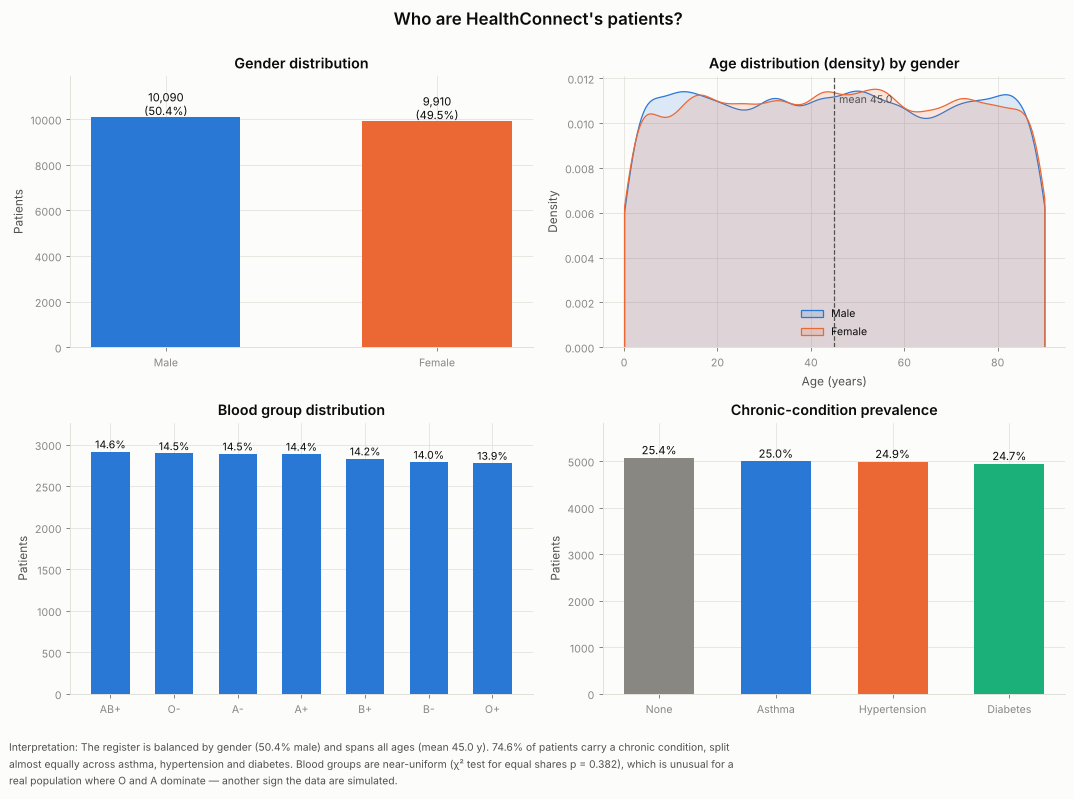

In [13]:
n_pat = len(PATIENTS)
gender = PATIENTS.Gender.value_counts()
bg = PATIENTS.BloodGroup.value_counts()
chron = PATIENTS.ChronicCondition.value_counts()
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].bar(gender.index, gender.values, color=[C[0], C[1]], width=.55)
for i, v in enumerate(gender.values): ax[0, 0].text(i, v + 100, f"{v:,}\n({pct(v / n_pat)})", ha="center", fontsize=9)
ax[0, 0].set(title="Gender distribution", ylabel="Patients", ylim=(0, gender.max() * 1.18))
for gname, col in zip(["Male", "Female"], [C[0], C[1]]):
    sns.kdeplot(PATIENTS.loc[PATIENTS.Gender == gname, "Age"], ax=ax[0, 1], color=col, label=gname, fill=True, alpha=.15, bw_adjust=.7, clip=(0, 90))
ax[0, 1].axvline(PATIENTS.Age.mean(), color=INK2, ls="--", lw=1); ax[0, 1].text(PATIENTS.Age.mean() + 1, ax[0, 1].get_ylim()[1] * .9, f"mean {PATIENTS.Age.mean():.1f}", fontsize=8.5, color=INK2)
ax[0, 1].set(title="Age distribution (density) by gender", xlabel="Age (years)", ylabel="Density"); ax[0, 1].legend()
ax[1, 0].bar(bg.index, bg.values, color=C[0], width=.6)
ax[1, 0].set(title="Blood group distribution", ylabel="Patients", ylim=(0, bg.max() * 1.12))
for i, v in enumerate(bg.values): ax[1, 0].text(i, v + 40, pct(v / n_pat), ha="center", fontsize=8.5)
cc = chron.reindex(["None", "Asthma", "Hypertension", "Diabetes"])
ax[1, 1].bar(cc.index, cc.values, color=[MUTED, C[0], C[1], C[2]], width=.6)
for i, v in enumerate(cc.values): ax[1, 1].text(i, v + 80, pct(v / n_pat), ha="center", fontsize=9)
ax[1, 1].set(title="Chronic-condition prevalence", ylabel="Patients", ylim=(0, cc.max() * 1.15))
fig.suptitle("Who are HealthConnect's patients?", fontsize=13.5, fontweight="semibold", y=1.0)
fig.tight_layout()
chi_g = stats.chisquare(bg.values)
R["gender_split"] = {k: int(v) for k, v in gender.items()}; R["mean_age"] = float(PATIENTS.Age.mean()); R["chronic_prev"] = float(PATIENTS.ChronicFlag.mean())
R["blood_uniform_p"] = float(chi_g.pvalue)
save_fig(fig, "f01_patient_profile",
         f"The register is balanced by gender ({pct(gender['Male'] / n_pat)} male) and spans all ages (mean {PATIENTS.Age.mean():.1f} y). "
         f"{pct(PATIENTS.ChronicFlag.mean())} of patients carry a chronic condition, split almost equally across asthma, hypertension and diabetes. "
         f"Blood groups are near-uniform (χ² test for equal shares {fmt_p(chi_g.pvalue)}), which is unusual for a real population where O and A dominate — another sign the data are simulated.")

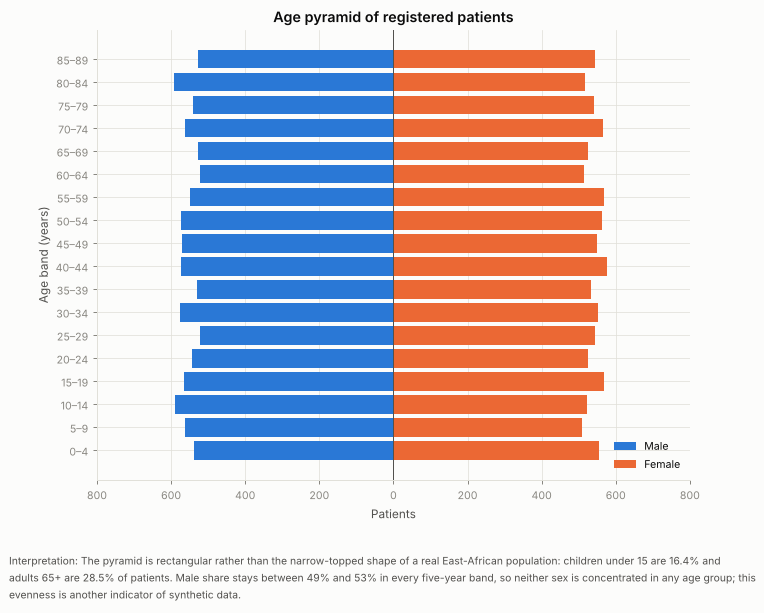

In [14]:
pyr = PATIENTS.assign(B=pd.cut(PATIENTS.Age, range(0, 95, 5), right=False)).groupby(["B", "Gender"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
y = np.arange(len(pyr))
ax.barh(y, -pyr["Male"], color=C[0], height=.8, label="Male"); ax.barh(y, pyr["Female"], color=C[1], height=.8, label="Female")
ax.set_yticks(y); ax.set_yticklabels([f"{int(i.left)}–{int(i.right) - 1}" for i in pyr.index])
mx = max(pyr.max()) * 1.1; ax.set_xlim(-mx, mx); ax.set_xticks(ax.get_xticks()); ax.set_xticklabels([f"{abs(int(t)):,}" for t in ax.get_xticks()])
ax.set(title="Age pyramid of registered patients", xlabel="Patients", ylabel="Age band (years)"); ax.legend(loc="lower right"); ax.axvline(0, color=INK2, lw=.8)
under15 = (PATIENTS.Age < 15).mean(); over65 = (PATIENTS.Age >= 65).mean()
msh = 100 * pyr.Male / (pyr.Male + pyr.Female)
R["under15"], R["over65"] = float(under15), float(over65)
save_fig(fig, "f02_age_pyramid", f"The pyramid is rectangular rather than the narrow-topped shape of a real East-African population: children under 15 are {pct(under15)} and adults 65+ are {pct(over65)} of patients. "
         f"Male share stays between {msh.min():.0f}% and {msh.max():.0f}% in every five-year band, so neither sex is concentrated in any age group; this evenness is another indicator of synthetic data.")

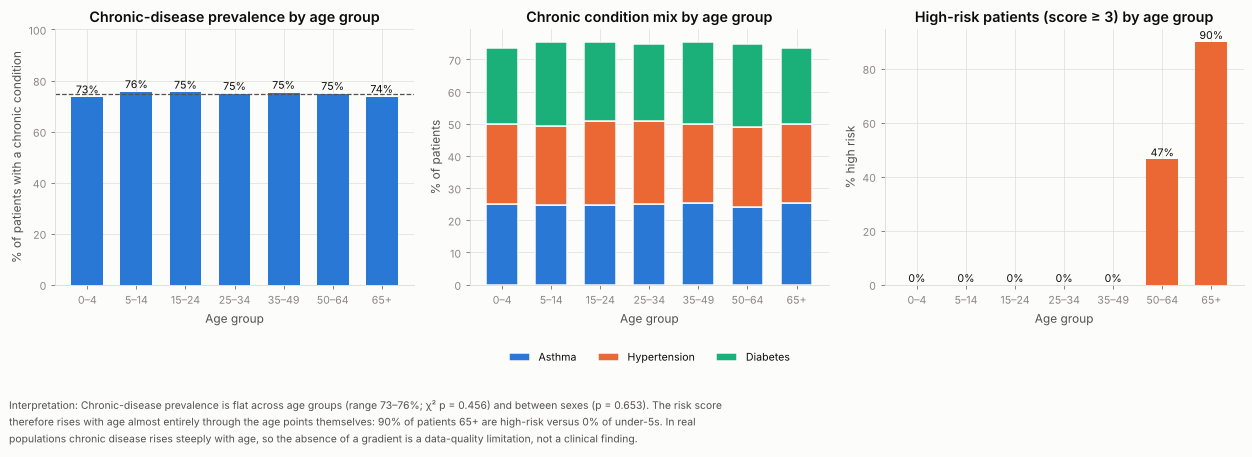

In [15]:
pg = PATIENTS.groupby("AgeGroup", observed=True).agg(n=("PatientID", "size"), chronic=("ChronicFlag", "mean"), highrisk=("HighRisk", "mean"), bmi=("BMI", "mean"))
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
ax[0].bar(pg.index.astype(str), 100 * pg.chronic, color=C[0], width=.65); ax[0].set(title="Chronic-disease prevalence by age group", xlabel="Age group", ylabel="% of patients with a chronic condition", ylim=(0, 100))
ax[0].axhline(100 * PATIENTS.ChronicFlag.mean(), color=INK2, ls="--", lw=1)
for i, v in enumerate(pg.chronic): ax[0].text(i, 100 * v + 1.5, f"{100 * v:.0f}%", ha="center", fontsize=8.5)
ct = pd.crosstab(PATIENTS.AgeGroup, PATIENTS.ChronicCondition, normalize="index")[["Asthma", "Hypertension", "Diabetes"]] * 100
bottom = np.zeros(len(ct))
for i, c in enumerate(ct.columns):
    ax[1].bar(ct.index.astype(str), ct[c], bottom=bottom, color=C[i], width=.65, label=c, edgecolor=SURF, linewidth=1.2); bottom += ct[c].values
ax[1].set(title="Chronic condition mix by age group", xlabel="Age group", ylabel="% of patients"); ax[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.22))
ax[2].bar(pg.index.astype(str), 100 * pg.highrisk, color=C[1], width=.65); ax[2].set(title="High-risk patients (score ≥ 3) by age group", xlabel="Age group", ylabel="% high risk")
for i, v in enumerate(pg.highrisk): ax[2].text(i, 100 * v + 1, f"{100 * v:.0f}%", ha="center", fontsize=8.5)
fig.tight_layout()
chi_age_chr = stats.chi2_contingency(pd.crosstab(PATIENTS.AgeGroup, PATIENTS.ChronicFlag))
chi_sex_chr = stats.chi2_contingency(pd.crosstab(PATIENTS.Gender, PATIENTS.ChronicFlag))
R["chronic_age_p"], R["chronic_sex_p"] = float(chi_age_chr[1]), float(chi_sex_chr[1])
save_fig(fig, "f03_chronic_by_age",
         f"Chronic-disease prevalence is flat across age groups (range {100 * pg.chronic.min():.0f}–{100 * pg.chronic.max():.0f}%; χ² {fmt_p(chi_age_chr[1])}) and between sexes ({fmt_p(chi_sex_chr[1])}). "
         f"The risk score therefore rises with age almost entirely through the age points themselves: {pct(pg.highrisk.iloc[-1], 0)} of patients 65+ are high-risk versus {pct(pg.highrisk.iloc[0], 0)} of under-5s. "
         "In real populations chronic disease rises steeply with age, so the absence of a gradient is a data-quality limitation, not a clinical finding.")

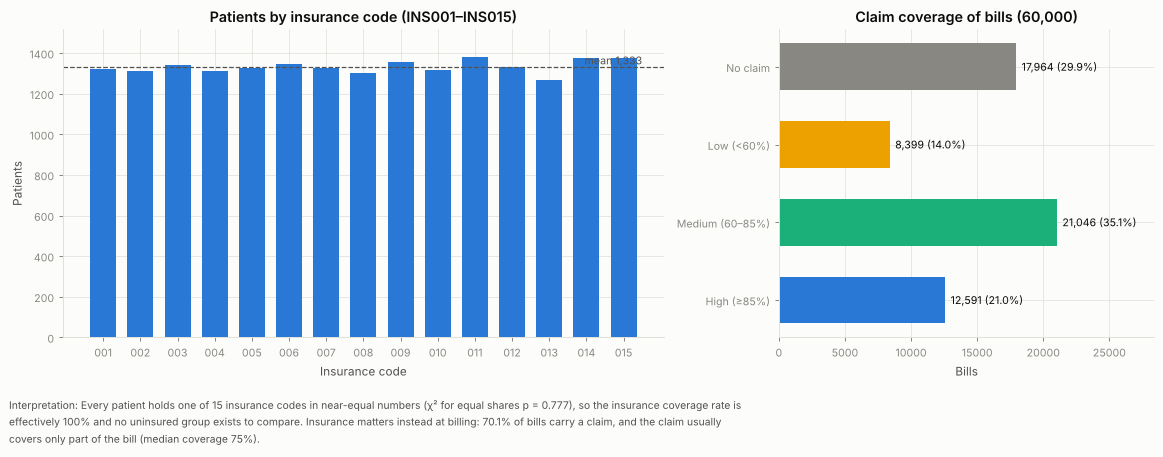

In [16]:
ins = PATIENTS.InsuranceID.value_counts().sort_index()
chi_ins = stats.chisquare(ins.values)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].bar(ins.index.str.replace("INS", ""), ins.values, color=C[0], width=.7)
ax[0].axhline(ins.mean(), color=INK2, ls="--", lw=1); ax[0].text(len(ins) - .5, ins.mean() + 12, f"mean {ins.mean():,.0f}", ha="right", fontsize=8.5, color=INK2)
ax[0].set(title="Patients by insurance code (INS001–INS015)", xlabel="Insurance code", ylabel="Patients", ylim=(0, ins.max() * 1.1))
cl = FIN.assign(Cov=FIN.CoverageCategory).Cov.value_counts().reindex(["No claim", "Low (<60%)", "Medium (60–85%)", "High (≥85%)"])
ax[1].barh(cl.index[::-1], cl.values[::-1], color=[C[0], C[2], C[3], MUTED], height=.6)
for i, v in enumerate(cl.values[::-1]): ax[1].text(v + 400, i, f"{v:,} ({pct(v / len(FIN))})", va="center", fontsize=8.5)
ax[1].set(title="Claim coverage of bills (60,000)", xlabel="Bills", xlim=(0, cl.max() * 1.35))
fig.tight_layout()
R["insurance_cov_all"] = 1.0; R["claim_rate"] = float(FIN.HasClaim.mean())
save_fig(fig, "f04_insurance",
         f"Every patient holds one of 15 insurance codes in near-equal numbers (χ² for equal shares {fmt_p(chi_ins.pvalue)}), so the insurance coverage rate is effectively 100% and no uninsured group exists to compare. "
         f"Insurance matters instead at billing: {pct(FIN.HasClaim.mean())} of bills carry a claim, and the claim usually covers only part of the bill (median coverage {pct(FIN.ClaimRatio.median(), 0)}).")

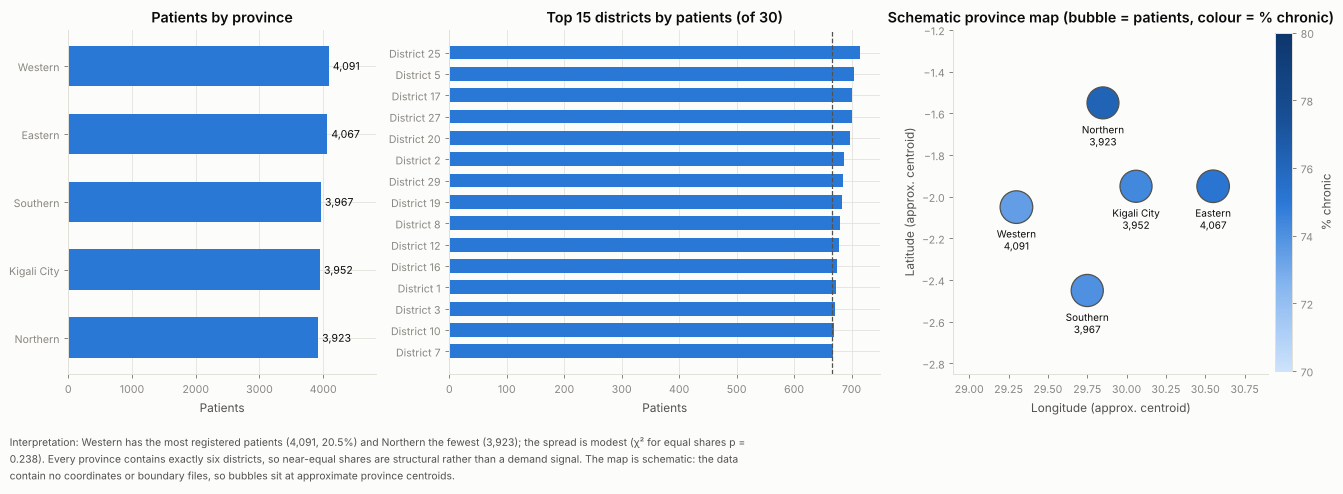

In [17]:
prov = PATIENTS.groupby("ProvinceName").agg(Patients=("PatientID", "size"), Chronic=("ChronicFlag", "mean"), HighRisk=("HighRisk", "mean"), MeanAge=("Age", "mean")).sort_values("Patients", ascending=False)
dist = PATIENTS.groupby("DistrictName").size().sort_values(ascending=False)
centroid = {"Kigali City": (30.06, -1.95), "Eastern": (30.55, -1.95), "Northern": (29.85, -1.55), "Southern": (29.75, -2.45), "Western": (29.30, -2.05)}
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.4, 1.1]})
ax[0].barh(prov.index[::-1], prov.Patients[::-1], color=C[0], height=.6)
for i, v in enumerate(prov.Patients[::-1]): ax[0].text(v + 60, i, f"{v:,}", va="center", fontsize=8.5)
ax[0].set(title="Patients by province", xlabel="Patients", xlim=(0, prov.Patients.max() * 1.18))
ax[1].barh(dist.index[:15][::-1], dist.values[:15][::-1], color=C[0], height=.65); ax[1].set(title="Top 15 districts by patients (of 30)", xlabel="Patients")
ax[1].axvline(dist.mean(), color=INK2, ls="--", lw=1)
xs = [centroid[p][0] for p in prov.index]; ys = [centroid[p][1] for p in prov.index]
sc = ax[2].scatter(xs, ys, s=prov.Patients / 6, c=100 * prov.Chronic, cmap=SEQ, edgecolor=INK2, linewidth=1, vmin=70, vmax=80, zorder=3)
for p, x_, y_ in zip(prov.index, xs, ys): ax[2].annotate(f"{p}\n{prov.loc[p, 'Patients']:,}", (x_, y_), textcoords="offset points", xytext=(0, -34), ha="center", fontsize=8)
ax[2].set(title="Schematic province map (bubble = patients, colour = % chronic)", xlim=(28.9, 30.9), ylim=(-2.85, -1.2), xlabel="Longitude (approx. centroid)", ylabel="Latitude (approx. centroid)"); ax[2].grid(False)
cb = fig.colorbar(sc, ax=ax[2], fraction=.05, pad=.02); cb.set_label("% chronic")
fig.tight_layout()
chi_prov = stats.chisquare(prov.Patients.values)
R["province_patients"] = prov.Patients.to_dict(); R["top_province"] = prov.index[0]
save_fig(fig, "f05_geography",
         f"{prov.index[0]} has the most registered patients ({prov.Patients.iloc[0]:,}, {pct(prov.Patients.iloc[0] / n_pat)}) and {prov.index[-1]} the fewest ({prov.Patients.iloc[-1]:,}); the spread is modest (χ² for equal shares {fmt_p(chi_prov.pvalue)}). "
         "Every province contains exactly six districts, so near-equal shares are structural rather than a demand signal. "
         "The map is schematic: the data contain no coordinates or boundary files, so bubbles sit at approximate province centroids.")

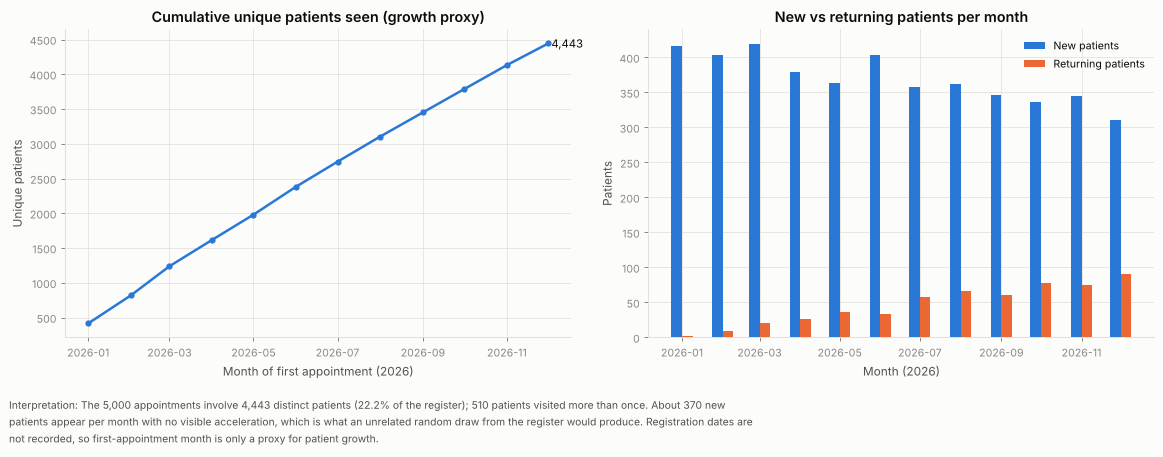

In [18]:
first = E.groupby("PatientID").Date.min().dt.to_period("M").dt.to_timestamp()
newp = first.value_counts().sort_index()
cum = newp.cumsum()
vol = E.groupby("Month").size()
ret = vol - newp.reindex(vol.index).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].plot(cum.index, cum.values, color=C[0], lw=2, marker="o", ms=4); ax[0].set(title="Cumulative unique patients seen (growth proxy)", xlabel="Month of first appointment (2026)", ylabel="Unique patients")
ax[0].text(cum.index[-1], cum.values[-1], f" {cum.values[-1]:,}", va="center", fontsize=9)
w = 8
ax[1].bar(newp.index - pd.Timedelta(days=4), newp.values, width=w, color=C[0], label="New patients"); ax[1].bar(ret.index + pd.Timedelta(days=4), ret.values, width=w, color=C[1], label="Returning patients")
ax[1].set(title="New vs returning patients per month", xlabel="Month (2026)", ylabel="Patients"); ax[1].legend()
fig.tight_layout()
R["unique_patients_seen"] = int(len(first)); R["returning_patients"] = int((visits >= 2).sum()); R["patients_seen_pct"] = float(len(first) / n_pat)
save_fig(fig, "f06_patient_growth",
         f"The 5,000 appointments involve {len(first):,} distinct patients ({pct(len(first) / n_pat)} of the register); {int((visits >= 2).sum())} patients visited more than once. "
         f"About {len(first) / 12:.0f} new patients appear per month with no visible acceleration, which is what an unrelated random draw from the register would produce. Registration dates are not recorded, so first-appointment month is only a proxy for patient growth.")

### 3.2 Clinical analysis

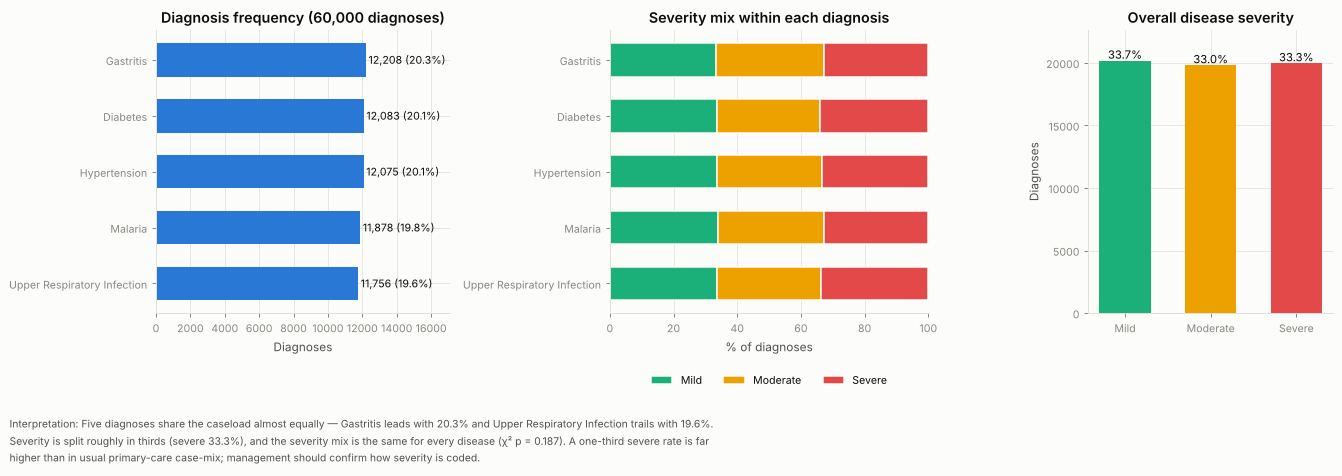

In [19]:
dxu_all = D["Diagnoses_csv"]
dfreq = dxu_all.Diagnosis.value_counts()
sev_ct = pd.crosstab(dxu_all.Diagnosis, dxu_all.Severity, normalize="index")[["Mild", "Moderate", "Severe"]] * 100
sev_ct = sev_ct.loc[dfreq.index]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.2, 1.3, 1]})
ax[0].barh(dfreq.index[::-1], dfreq.values[::-1], color=C[0], height=.6)
for i, v in enumerate(dfreq.values[::-1]): ax[0].text(v + 150, i, f"{v:,} ({pct(v / len(dxu_all))})", va="center", fontsize=8.5)
ax[0].set(title="Diagnosis frequency (60,000 diagnoses)", xlabel="Diagnoses", xlim=(0, dfreq.max() * 1.4))
left = np.zeros(len(sev_ct))
for i, s in enumerate(["Mild", "Moderate", "Severe"]):
    ax[1].barh(sev_ct.index[::-1], sev_ct[s][::-1], left=left, color=[C[2], C[3], C[7]][i], label=s, height=.6, edgecolor=SURF, linewidth=1.2); left += sev_ct[s][::-1].values
ax[1].set(title="Severity mix within each diagnosis", xlabel="% of diagnoses"); ax[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.18)); ax[1].set_xlim(0, 100)
sv = dxu_all.Severity.value_counts().reindex(["Mild", "Moderate", "Severe"])
ax[2].bar(sv.index, sv.values, color=[C[2], C[3], C[7]], width=.6)
for i, v in enumerate(sv.values): ax[2].text(i, v + 150, pct(v / len(dxu_all)), ha="center", fontsize=9)
ax[2].set(title="Overall disease severity", ylabel="Diagnoses", ylim=(0, sv.max() * 1.12))
fig.tight_layout()
chi_dx_sev = stats.chi2_contingency(pd.crosstab(dxu_all.Diagnosis, dxu_all.Severity))
R["dx_freq"] = dfreq.to_dict(); R["severity_mix"] = (sv / len(dxu_all)).to_dict(); R["dx_sev_p"] = float(chi_dx_sev[1])
save_fig(fig, "f07_diagnoses",
         f"Five diagnoses share the caseload almost equally — {dfreq.index[0]} leads with {pct(dfreq.iloc[0] / len(dxu_all))} and {dfreq.index[-1]} trails with {pct(dfreq.iloc[-1] / len(dxu_all))}. "
         f"Severity is split roughly in thirds (severe {pct(sv['Severe'] / len(dxu_all))}), and the severity mix is the same for every disease (χ² {fmt_p(chi_dx_sev[1])}). "
         "A one-third severe rate is far higher than in usual primary-care case-mix; management should confirm how severity is coded.")

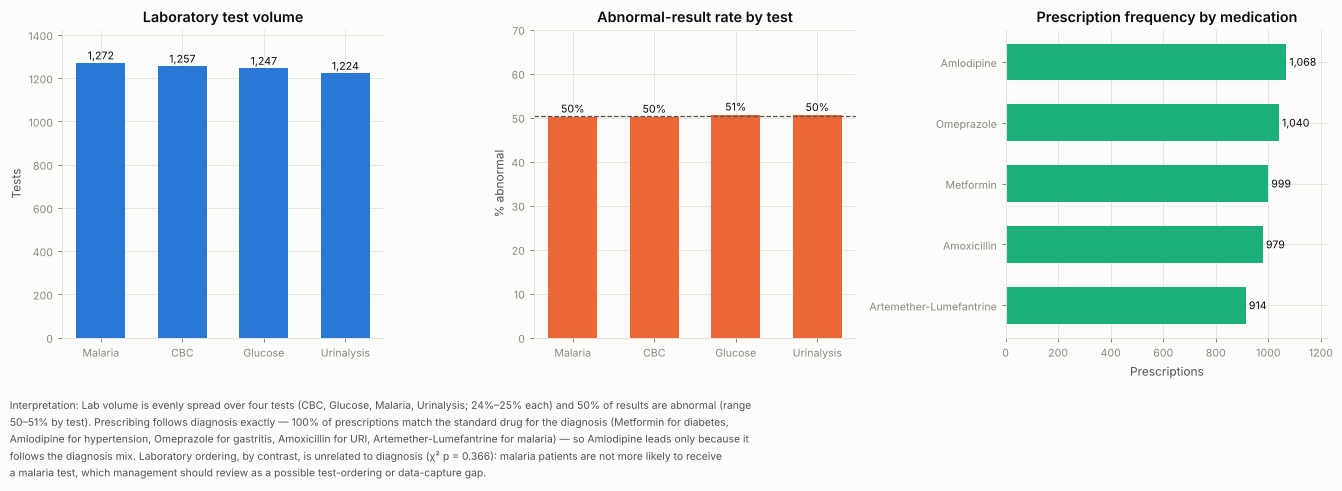

In [20]:
labs_t = T["Laboratory_Tests"]; rx_t = T["Prescriptions"]
lab_use = labs_t.Test.value_counts(); lab_abn = labs_t.groupby("Test").Result.apply(lambda s: (s == "Abnormal").mean()).reindex(lab_use.index)
rx_use = rx_t.Medication.value_counts()
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
ax[0].bar(lab_use.index, lab_use.values, color=C[0], width=.6)
for i, v in enumerate(lab_use.values): ax[0].text(i, v + 15, f"{v:,}", ha="center", fontsize=8.5)
ax[0].set(title="Laboratory test volume", ylabel="Tests", ylim=(0, lab_use.max() * 1.12))
ax[1].bar(lab_abn.index, 100 * lab_abn.values, color=C[1], width=.6); ax[1].axhline(100 * (labs_t.Result == "Abnormal").mean(), color=INK2, ls="--", lw=1)
for i, v in enumerate(lab_abn.values): ax[1].text(i, 100 * v + 1, f"{100 * v:.0f}%", ha="center", fontsize=8.5)
ax[1].set(title="Abnormal-result rate by test", ylabel="% abnormal", ylim=(0, 70))
ax[2].barh(rx_use.index[::-1], rx_use.values[::-1], color=C[2], height=.6)
for i, v in enumerate(rx_use.values[::-1]): ax[2].text(v + 12, i, f"{v:,}", va="center", fontsize=8.5)
ax[2].set(title="Prescription frequency by medication", xlabel="Prescriptions", xlim=(0, rx_use.max() * 1.15))
fig.tight_layout()
# does the medication fit the diagnosis?  (clinical-logic check)
mx_ct = pd.crosstab(E.Diagnosis, E.Medication)
chi_med = stats.chi2_contingency(mx_ct)
conc_map = {"Diabetes": "Metformin", "Gastritis": "Omeprazole", "Hypertension": "Amlodipine", "Upper Respiratory Infection": "Amoxicillin", "Malaria": "Artemether-Lumefantrine"}
_m = E[E.Medication.notna()]
rx_conc = float((_m.Medication == _m.Diagnosis.map(conc_map)).mean())
lab_dx = stats.chi2_contingency(pd.crosstab(E.Diagnosis[E.LabTest.notna()], E.LabTest[E.LabTest.notna()]))
lab_match = float((E[E.LabTest.notna()].LabTest == E[E.LabTest.notna()].Diagnosis.map({"Malaria": "Malaria", "Diabetes": "Glucose"})).sum() / E.Diagnosis[E.LabTest.notna()].isin(["Malaria", "Diabetes"]).sum())
R["rx_concordance"], R["lab_dx_p"] = rx_conc, float(lab_dx[1])
R["lab_volume"] = lab_use.to_dict(); R["rx_volume"] = rx_use.to_dict(); R["abnormal_rate"] = float((labs_t.Result == "Abnormal").mean()); R["med_dx_p"] = float(chi_med[1])
save_fig(fig, "f08_labs_rx",
         f"Lab volume is evenly spread over four tests (CBC, Glucose, Malaria, Urinalysis; {pct(lab_use.min() / lab_use.sum(), 0)}–{pct(lab_use.max() / lab_use.sum(), 0)} each) and {pct((labs_t.Result == 'Abnormal').mean(), 0)} of results are abnormal (range {100 * lab_abn.min():.0f}–{100 * lab_abn.max():.0f}% by test). "
         f"Prescribing follows diagnosis exactly — {pct(rx_conc, 0)} of prescriptions match the standard drug for the diagnosis (Metformin for diabetes, Amlodipine for hypertension, Omeprazole for gastritis, Amoxicillin for URI, Artemether-Lumefantrine for malaria) — so {rx_use.index[0]} leads only because it follows the diagnosis mix. "
         f"Laboratory ordering, by contrast, is unrelated to diagnosis (χ² {fmt_p(lab_dx[1])}): malaria patients are not more likely to receive a malaria test, which management should review as a possible test-ordering or data-capture gap.")

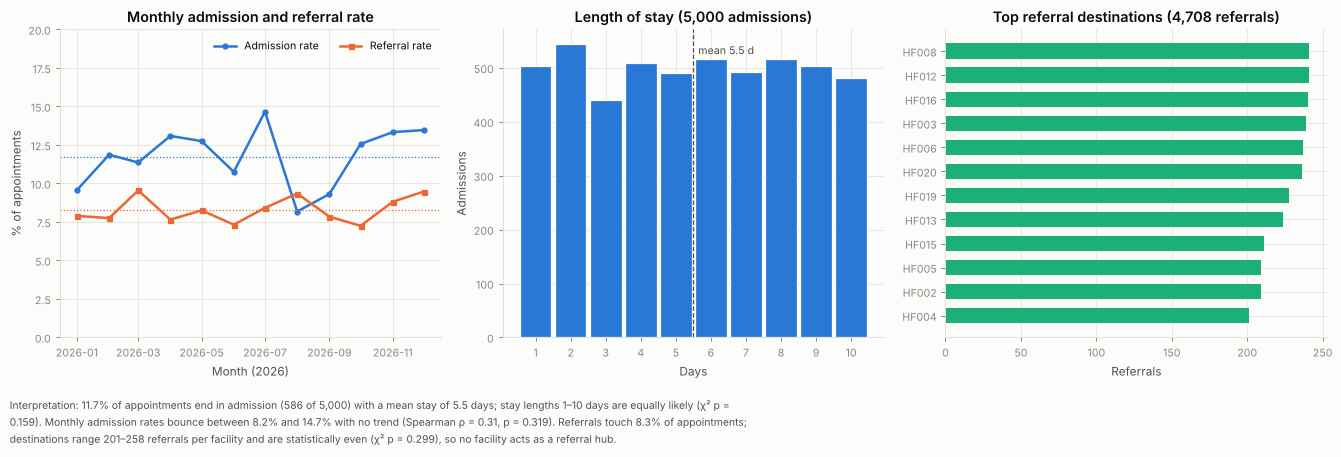

In [21]:
adm_m = E.groupby("Month").agg(Admissions=("Admitted", "sum"), Appts=("AppointmentID", "size"), Referrals=("Referred", "sum"))
adm_m["AdmitRate"] = 100 * adm_m.Admissions / adm_m.Appts; adm_m["RefRate"] = 100 * adm_m.Referrals / adm_m.Appts
adm_all = T["Admissions"]
ref_dest = T["Referrals"].ReferredFacilityID.value_counts()
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
ax[0].plot(adm_m.index, adm_m.AdmitRate, color=C[0], lw=2, marker="o", ms=4, label="Admission rate")
ax[0].plot(adm_m.index, adm_m.RefRate, color=C[1], lw=2, marker="s", ms=4, label="Referral rate")
ax[0].axhline(100 * E.Admitted.mean(), color=C[0], ls=":", lw=1); ax[0].axhline(100 * E.Referred.mean(), color=C[1], ls=":", lw=1)
ax[0].set(title="Monthly admission and referral rate", xlabel="Month (2026)", ylabel="% of appointments", ylim=(0, 20)); ax[0].legend(loc="upper right", ncol=2)
ax[1].hist(adm_all.LengthOfStayDays, bins=np.arange(.5, 11.5, 1), color=C[0], edgecolor=SURF, rwidth=.9); ax[1].axvline(adm_all.LengthOfStayDays.mean(), color=INK2, ls="--", lw=1)
ax[1].text(adm_all.LengthOfStayDays.mean() + .15, ax[1].get_ylim()[1] * .92, f"mean {adm_all.LengthOfStayDays.mean():.1f} d", fontsize=8.5, color=INK2)
ax[1].set(title="Length of stay (5,000 admissions)", xlabel="Days", ylabel="Admissions"); ax[1].set_xticks(range(1, 11))
ax[2].barh(ref_dest.index[::-1][:12], ref_dest.values[::-1][:12], color=C[2], height=.65); ax[2].set(title="Top referral destinations (4,708 referrals)", xlabel="Referrals")
fig.tight_layout()
trend_adm = stats.spearmanr(np.arange(12), adm_m.AdmitRate)
los_u = stats.chisquare(adm_all.LengthOfStayDays.value_counts().sort_index().values); ref_u = stats.chisquare(ref_dest.values)
R["admit_rate"] = float(E.Admitted.mean()); R["mean_los"] = float(adm_all.LengthOfStayDays.mean()); R["referral_rate"] = float(E.Referred.mean())
R["n_admissions_all"] = int(len(adm_all)); R["admit_trend_rho"], R["admit_trend_p"] = float(trend_adm[0]), float(trend_adm[1])
save_fig(fig, "f09_admissions_referrals",
         f"{pct(E.Admitted.mean())} of appointments end in admission (586 of 5,000) with a mean stay of {adm_all.LengthOfStayDays.mean():.1f} days; stay lengths 1–10 days are equally likely (χ² {fmt_p(los_u.pvalue)}). "
         f"Monthly admission rates bounce between {adm_m.AdmitRate.min():.1f}% and {adm_m.AdmitRate.max():.1f}% with no trend (Spearman ρ = {trend_adm[0]:.2f}, {fmt_p(trend_adm[1])}). "
         f"Referrals touch {pct(E.Referred.mean())} of appointments; destinations range {ref_dest.min()}–{ref_dest.max()} referrals per facility and are statistically even (χ² {fmt_p(ref_u.pvalue)}), so no facility acts as a referral hub.")

### 3.3 Operational analysis

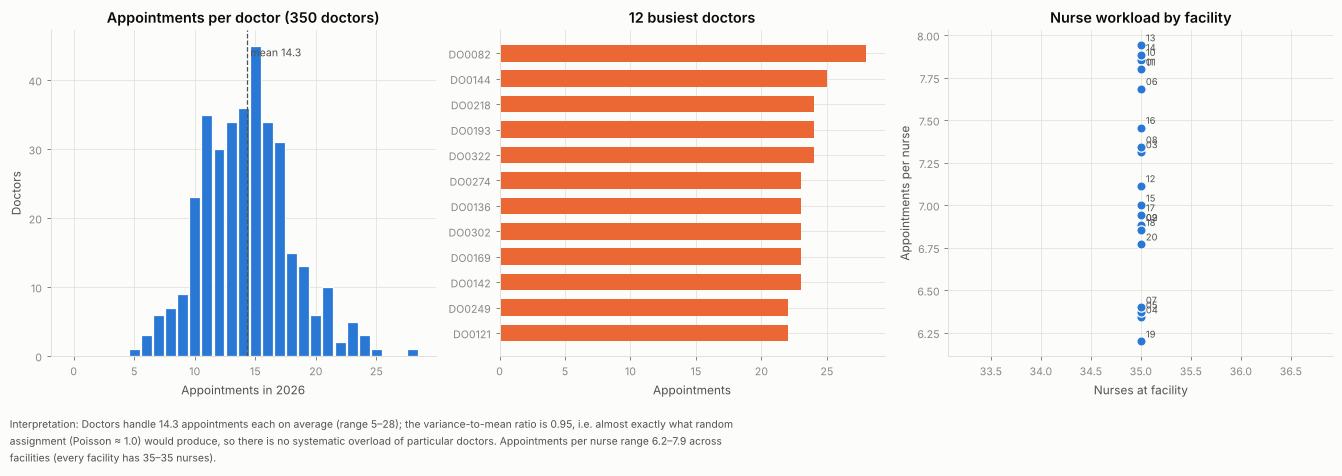

In [22]:
doc_load = E.groupby("DoctorID").size().reindex(doc.StaffID, fill_value=0)
nurse_fac = D["Nurses"].groupby("FacilityID").size()
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].hist(doc_load, bins=np.arange(-.5, doc_load.max() + 1.5, 1), color=C[0], edgecolor=SURF, rwidth=.9)
ax[0].axvline(doc_load.mean(), color=INK2, ls="--", lw=1); ax[0].text(doc_load.mean() + .3, ax[0].get_ylim()[1] * .92, f"mean {doc_load.mean():.1f}", fontsize=8.5, color=INK2)
ax[0].set(title="Appointments per doctor (350 doctors)", xlabel="Appointments in 2026", ylabel="Doctors")
topd = doc_load.sort_values(ascending=False).head(12)
ax[1].barh(topd.index[::-1], topd.values[::-1], color=C[1], height=.65); ax[1].set(title="12 busiest doctors", xlabel="Appointments")
ax[2].scatter(K.Nurses, K.Appointments / K.Nurses, s=55, color=C[0], edgecolor=SURF, zorder=3)
for f_, r_ in K.iterrows(): ax[2].annotate(f_[-2:], (r_.Nurses, r_.Appointments / r_.Nurses), textcoords="offset points", xytext=(4, 3), fontsize=7.5, color=INK2)
ax[2].set(title="Nurse workload by facility", xlabel="Nurses at facility", ylabel="Appointments per nurse")
fig.tight_layout()
cv = doc_load.std() / doc_load.mean()
R["doc_load_mean"], R["doc_load_max"], R["doc_load_cv"] = float(doc_load.mean()), int(doc_load.max()), float(cv)
exp_pois = stats.poisson(doc_load.mean())
disp = doc_load.var() / doc_load.mean()
R["doc_dispersion"] = float(disp)
save_fig(fig, "f10_staff_workload",
         f"Doctors handle {doc_load.mean():.1f} appointments each on average (range {doc_load.min()}–{doc_load.max()}); the variance-to-mean ratio is {disp:.2f}, i.e. almost exactly what random assignment (Poisson ≈ 1.0) would produce, so there is no systematic overload of particular doctors. "
         f"Appointments per nurse range {(K.Appointments / K.Nurses).min():.1f}–{(K.Appointments / K.Nurses).max():.1f} across facilities (every facility has {int(K.Nurses.min())}–{int(K.Nurses.max())} nurses).")

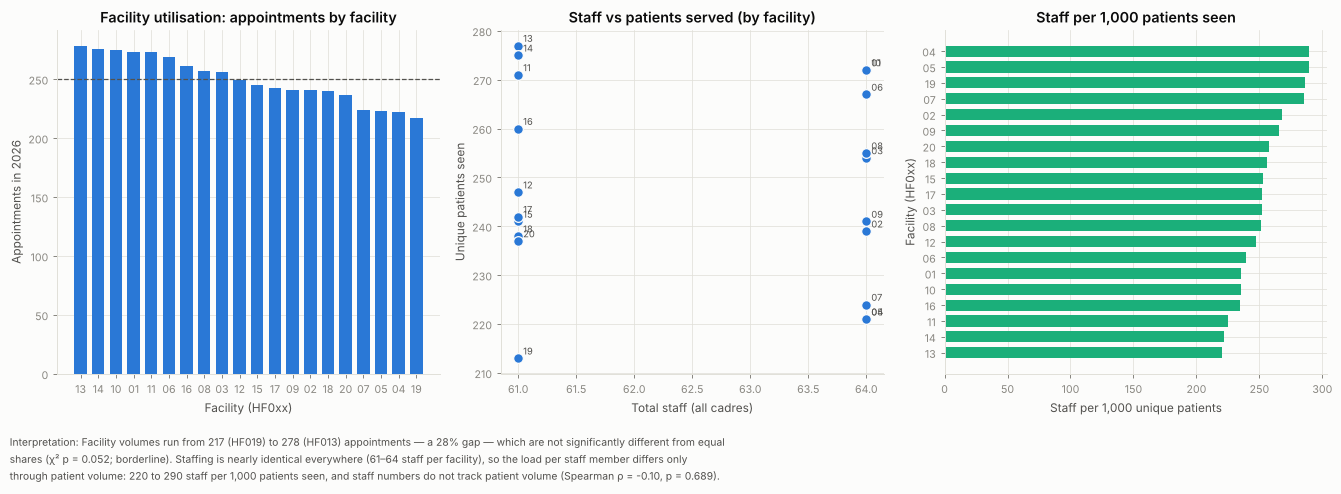

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
ks = K.sort_values("Appointments", ascending=False)
ax[0].bar(ks.index.str[-2:], ks.Appointments, color=C[0], width=.7); ax[0].axhline(ks.Appointments.mean(), color=INK2, ls="--", lw=1)
ax[0].set(title="Facility utilisation: appointments by facility", xlabel="Facility (HF0xx)", ylabel="Appointments in 2026")
ax[1].scatter(K.TotalStaff, K.UniquePatients, s=60, color=C[0], edgecolor=SURF, zorder=3)
for f_, r_ in K.iterrows(): ax[1].annotate(f_[-2:], (r_.TotalStaff, r_.UniquePatients), textcoords="offset points", xytext=(4, 3), fontsize=7.5, color=INK2)
rr = stats.spearmanr(K.TotalStaff, K.UniquePatients)
ax[1].set(title="Staff vs patients served (by facility)", xlabel="Total staff (all cadres)", ylabel="Unique patients seen")
kk = K.sort_values("StaffPer1000Pts", ascending=False)
ax[2].barh(kk.index.str[-2:][::-1], kk.StaffPer1000Pts[::-1], color=C[2], height=.7); ax[2].set(title="Staff per 1,000 patients seen", xlabel="Staff per 1,000 unique patients", ylabel="Facility (HF0xx)")
fig.tight_layout()
R["fac_appt_range"] = [int(K.Appointments.min()), int(K.Appointments.max())]; R["staff_per1000_range"] = [float(K.StaffPer1000Pts.min()), float(K.StaffPer1000Pts.max())]
R["staff_vs_patients_rho"], R["staff_vs_patients_p"] = float(rr[0]), float(rr[1])
busy, quiet = ks.index[0], ks.index[-1]
fac_chi = stats.chisquare(K.Appointments.values)
R["fac_uniform_p"] = float(fac_chi.pvalue); R["busiest_facility"], R["quietest_facility"] = busy, quiet
sig11 = "differ significantly" if fac_chi.pvalue < 0.05 else "are not significantly different from equal shares"
save_fig(fig, "f11_facility_utilisation",
         f"Facility volumes run from {int(K.Appointments.min())} ({quiet}) to {int(K.Appointments.max())} ({busy}) appointments — a {pct(K.Appointments.max() / K.Appointments.min() - 1, 0)} gap — which {sig11} (χ² {fmt_p(fac_chi.pvalue)}; borderline). "
         f"Staffing is nearly identical everywhere ({int(K.TotalStaff.min())}–{int(K.TotalStaff.max())} staff per facility), so the load per staff member differs only through patient volume: {K.StaffPer1000Pts.min():.0f} to {K.StaffPer1000Pts.max():.0f} staff per 1,000 patients seen, "
         f"and staff numbers do not track patient volume (Spearman ρ = {rr[0]:.2f}, {fmt_p(rr[1])}).")

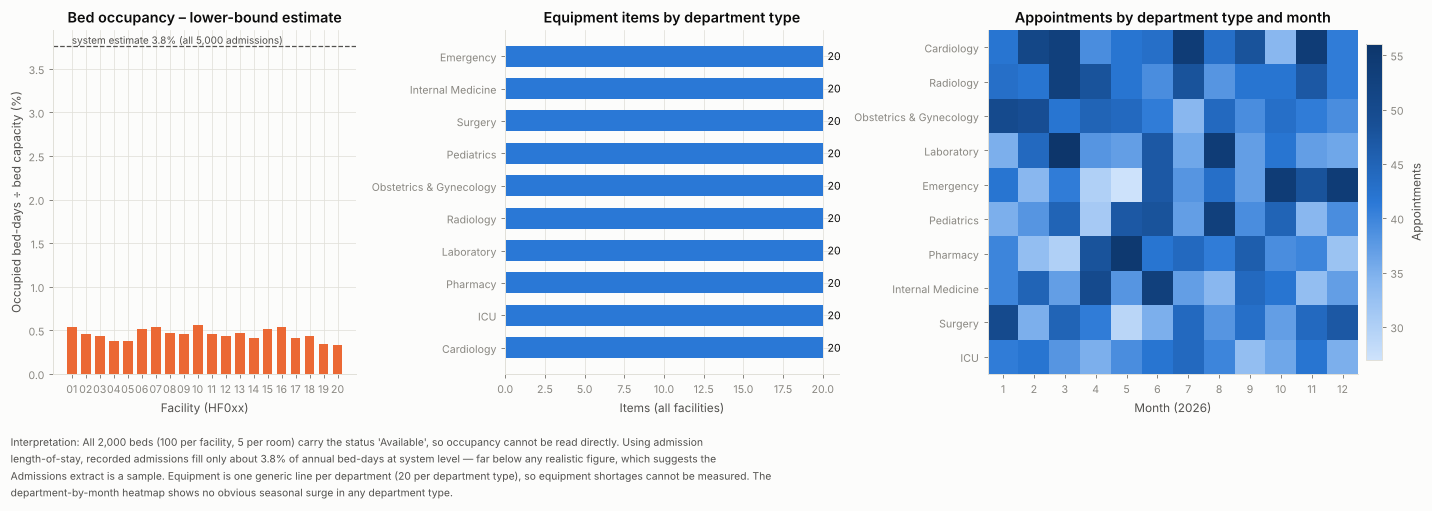

In [24]:
occ_sys = adm_all.LengthOfStayDays.sum() / (len(D["Beds"]) * 365)
occ_fac = (E.groupby("FacilityID").LengthOfStayDays.sum() / (K.Beds * 365)).fillna(0) * 100
dh = pd.crosstab(E.DepartmentName, E.Month.dt.month)
dh = dh.loc[DEPTT.sort_values("Appointments", ascending=False).index]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.1, 1.3]})
ax[0].bar(occ_fac.index.str[-2:], occ_fac.values, color=C[1], width=.7)
ax[0].axhline(100 * occ_sys, color=INK2, ls="--", lw=1); ax[0].text(0, 100 * occ_sys + .03, f"system estimate {100 * occ_sys:.1f}% (all 5,000 admissions)", fontsize=8, color=INK2)
ax[0].set(title="Bed occupancy – lower-bound estimate", xlabel="Facility (HF0xx)", ylabel="Occupied bed-days ÷ bed capacity (%)")
eq = D["Medical_Equipment"].EquipmentName.str.replace(" Equipment", "").value_counts()
ax[1].barh(eq.index[::-1], eq.values[::-1], color=C[0], height=.65); ax[1].set(title="Equipment items by department type", xlabel="Items (all facilities)")
for i, v in enumerate(eq.values[::-1]): ax[1].text(v + .3, i, str(v), va="center", fontsize=8.5)
im = ax[2].imshow(dh.values, aspect="auto", cmap=SEQ); ax[2].set_yticks(range(len(dh))); ax[2].set_yticklabels(dh.index); ax[2].set_xticks(range(12)); ax[2].set_xticklabels(range(1, 13))
ax[2].set(title="Appointments by department type and month", xlabel="Month (2026)"); ax[2].grid(False); fig.colorbar(im, ax=ax[2], fraction=.04, pad=.02, label="Appointments")
fig.tight_layout()
R["bed_occupancy_system"] = float(occ_sys); R["beds_total"] = int(len(D["Beds"])); R["beds_available_status"] = int((D["Beds"].Status == "Available").sum())
R["equip_per_dept_type"] = 20
save_fig(fig, "f12_capacity",
         f"All 2,000 beds (100 per facility, 5 per room) carry the status 'Available', so occupancy cannot be read directly. Using admission length-of-stay, recorded admissions fill only about {100 * occ_sys:.1f}% of annual bed-days at system level — "
         "far below any realistic figure, which suggests the Admissions extract is a sample. Equipment is one generic line per department (20 per department type), so equipment shortages cannot be measured. "
         "The department-by-month heatmap shows no obvious seasonal surge in any department type.")

### 3.4 Financial analysis

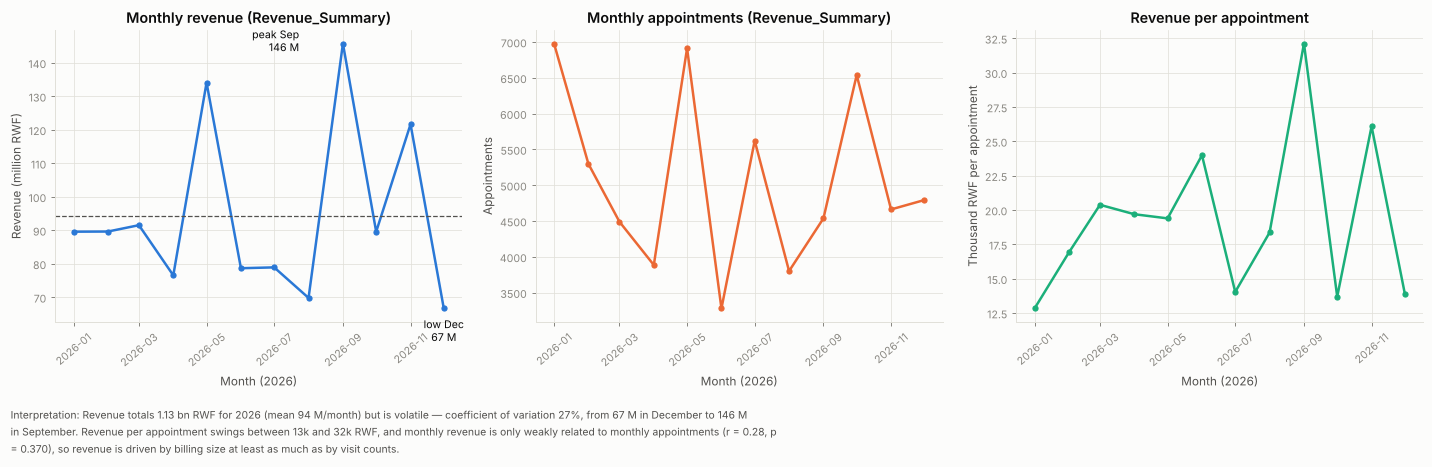

In [25]:
rs = D["Revenue_Summary"].copy(); rs["Month"] = pd.to_datetime(rs.Month + "-01"); rs["RevPerAppt"] = rs.Revenue / rs.Appointments
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot(rs.Month, rs.Revenue / 1e6, color=C[0], lw=2, marker="o", ms=4); ax[0].axhline(rs.Revenue.mean() / 1e6, color=INK2, ls="--", lw=1)
ax[0].set(title="Monthly revenue (Revenue_Summary)", xlabel="Month (2026)", ylabel="Revenue (million RWF)")
imax, imin = rs.Revenue.idxmax(), rs.Revenue.idxmin()
ax[0].annotate(f"peak {rs.Month[imax]:%b}\n{rs.Revenue[imax] / 1e6:.0f} M", (rs.Month[imax], rs.Revenue[imax] / 1e6), textcoords="offset points", xytext=(-35, -6), ha="right", fontsize=8.5)
ax[0].annotate(f"low {rs.Month[imin]:%b}\n{rs.Revenue[imin] / 1e6:.0f} M", (rs.Month[imin], rs.Revenue[imin] / 1e6), textcoords="offset points", xytext=(0, -26), ha="center", fontsize=8.5)
ax[1].plot(rs.Month, rs.Appointments, color=C[1], lw=2, marker="o", ms=4); ax[1].set(title="Monthly appointments (Revenue_Summary)", xlabel="Month (2026)", ylabel="Appointments")
ax[2].plot(rs.Month, rs.RevPerAppt / 1e3, color=C[2], lw=2, marker="o", ms=4); ax[2].set(title="Revenue per appointment", xlabel="Month (2026)", ylabel="Thousand RWF per appointment")
for a_ in ax: a_.tick_params(axis="x", rotation=40)
fig.tight_layout()
rev_cv = rs.Revenue.std() / rs.Revenue.mean()
rev_app_r = stats.pearsonr(rs.Revenue, rs.Appointments); R["rev_appt_corr"] = [float(rev_app_r[0]), float(rev_app_r[1])]
R["rev_total"] = float(rs.Revenue.sum()); R["rev_mean"] = float(rs.Revenue.mean()); R["rev_cv"] = float(rev_cv); R["rev_peak"] = [f"{rs.Month[imax]:%b}", float(rs.Revenue[imax])]; R["rev_low"] = [f"{rs.Month[imin]:%b}", float(rs.Revenue[imin])]
R["appts_summary_total"] = int(rs.Appointments.sum())
save_fig(fig, "f13_revenue_trend",
         f"Revenue totals {rs.Revenue.sum() / 1e9:.2f} bn RWF for 2026 (mean {rs.Revenue.mean() / 1e6:.0f} M/month) but is volatile — coefficient of variation {pct(rev_cv, 0)}, from {rs.Revenue[imin] / 1e6:.0f} M in {rs.Month[imin]:%B} to {rs.Revenue[imax] / 1e6:.0f} M in {rs.Month[imax]:%B}. "
         f"Revenue per appointment swings between {rs.RevPerAppt.min() / 1e3:.0f}k and {rs.RevPerAppt.max() / 1e3:.0f}k RWF, and monthly revenue is only weakly related to monthly appointments (r = {rev_app_r[0]:.2f}, {fmt_p(rev_app_r[1])}), so revenue is driven by billing size at least as much as by visit counts.")

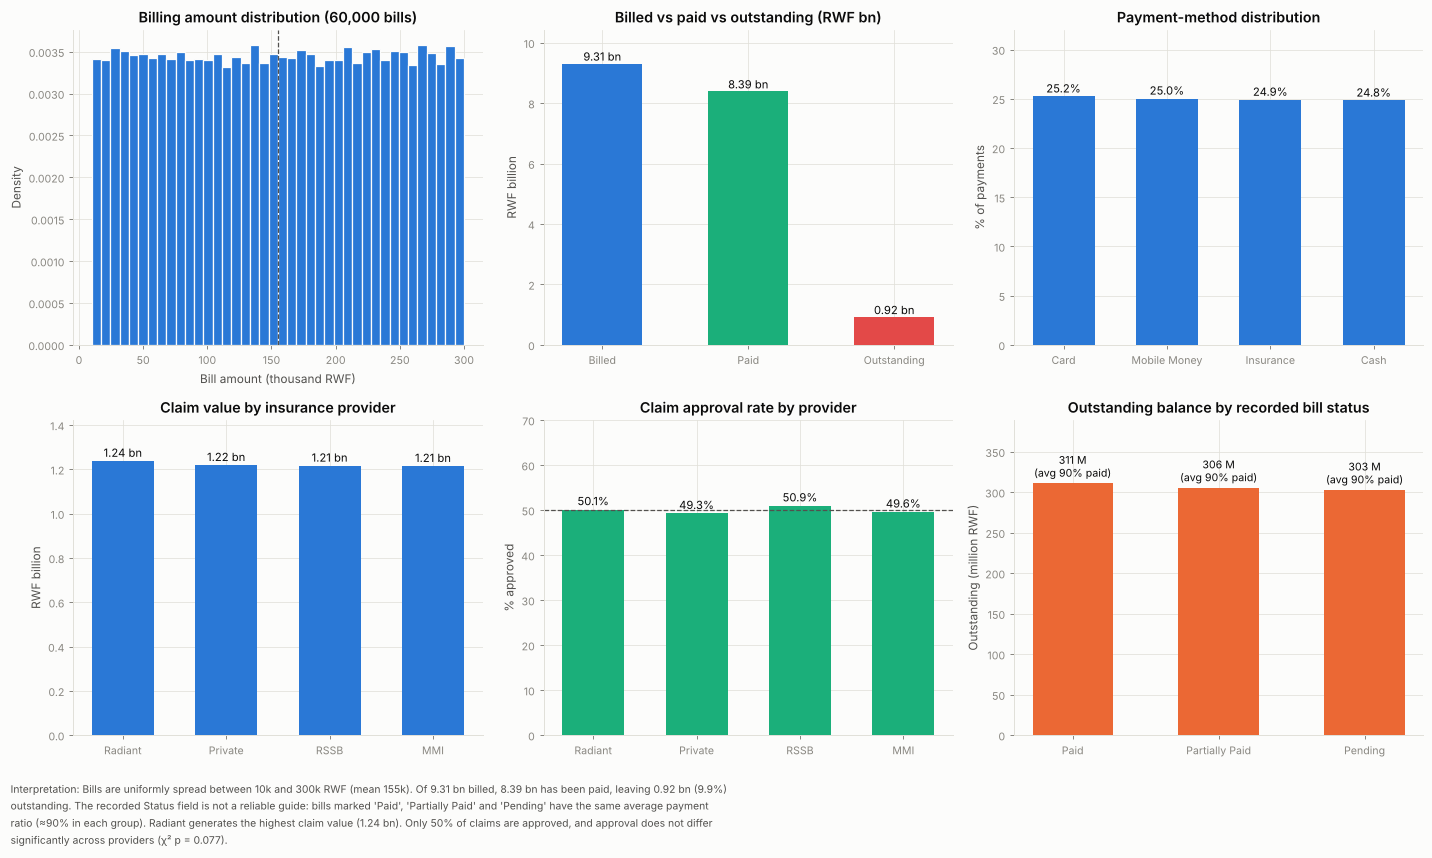

In [26]:
paid_tot, bill_tot, out_tot = F.AmountPaid.sum(), F.Amount.sum(), F.Outstanding.sum()
fig, ax = plt.subplots(2, 3, figsize=(16, 8.6))
ax[0, 0].hist(F.Amount / 1e3, bins=40, color=C[0], edgecolor=SURF, density=True); ax[0, 0].axvline(F.Amount.median() / 1e3, color=INK2, ls="--", lw=1)
ax[0, 0].set(title="Billing amount distribution (60,000 bills)", xlabel="Bill amount (thousand RWF)", ylabel="Density")
ax[0, 1].bar(["Billed", "Paid", "Outstanding"], np.array([bill_tot, paid_tot, out_tot]) / 1e9, color=[C[0], C[2], C[7]], width=.55)
for i, v in enumerate([bill_tot, paid_tot, out_tot]): ax[0, 1].text(i, v / 1e9 + .1, f"{v / 1e9:.2f} bn", ha="center", fontsize=9)
ax[0, 1].set(title="Billed vs paid vs outstanding (RWF bn)", ylabel="RWF billion", ylim=(0, bill_tot / 1e9 * 1.12))
pm = F.groupby("Method").agg(n=("PaymentID", "size"), paid=("AmountPaid", "sum"), out=("Outstanding", "sum")).sort_values("n", ascending=False)
ax[0, 2].bar(pm.index, 100 * pm.n / pm.n.sum(), color=C[0], width=.6)
for i, v in enumerate(pm.n): ax[0, 2].text(i, 100 * v / pm.n.sum() + .4, pct(v / pm.n.sum()), ha="center", fontsize=9)
ax[0, 2].set(title="Payment-method distribution", ylabel="% of payments", ylim=(0, 32))
cp = clm.groupby("Provider").agg(n=("ClaimID", "size"), amt=("ClaimAmount", "sum"), appr=("Status", lambda s: (s == "Approved").mean())).sort_values("amt", ascending=False)
ax[1, 0].bar(cp.index, cp.amt / 1e9, color=C[0], width=.6)
for i, v in enumerate(cp.amt): ax[1, 0].text(i, v / 1e9 + .02, f"{v / 1e9:.2f} bn", ha="center", fontsize=9)
ax[1, 0].set(title="Claim value by insurance provider", ylabel="RWF billion", ylim=(0, cp.amt.max() / 1e9 * 1.15))
ax[1, 1].bar(cp.index, 100 * cp.appr, color=C[2], width=.6); ax[1, 1].axhline(100 * (clm.Status == "Approved").mean(), color=INK2, ls="--", lw=1)
for i, v in enumerate(cp.appr): ax[1, 1].text(i, 100 * v + 1, f"{100 * v:.1f}%", ha="center", fontsize=9)
ax[1, 1].set(title="Claim approval rate by provider", ylabel="% approved", ylim=(0, 70))
sp_ = F.groupby("Status").agg(n=("BillingID", "size"), out=("Outstanding", "sum"), paid_ratio=("PaidRatio", "mean"))
ax[1, 2].bar(sp_.index, sp_.out / 1e6, color=C[1], width=.55)
for i, (v, r_) in enumerate(zip(sp_.out, sp_.paid_ratio)): ax[1, 2].text(i, v / 1e6 + 8, f"{v / 1e6:.0f} M\n(avg {100 * r_:.0f}% paid)", ha="center", fontsize=8.5)
ax[1, 2].set(title="Outstanding balance by recorded bill status", ylabel="Outstanding (million RWF)", ylim=(0, sp_.out.max() / 1e6 * 1.25))
fig.tight_layout()
R["bill_total"], R["paid_total"], R["outstanding_total"] = float(bill_tot), float(paid_tot), float(out_tot)
R["outstanding_pct"] = float(out_tot / bill_tot); R["mean_bill"], R["median_bill"] = float(F.Amount.mean()), float(F.Amount.median())
R["claim_approval"] = float((clm.Status == "Approved").mean()); R["claim_value"] = float(clm.ClaimAmount.sum())
R["provider_claim_value"] = cp.amt.to_dict(); R["provider_approval"] = cp.appr.to_dict(); R["pay_method_share"] = (pm.n / pm.n.sum()).to_dict()
chi_prov_appr = stats.chi2_contingency(pd.crosstab(clm.Provider, clm.Status))
R["provider_approval_p"] = float(chi_prov_appr[1])
save_fig(fig, "f14_billing_claims_payments",
         f"Bills are uniformly spread between 10k and 300k RWF (mean {F.Amount.mean() / 1e3:.0f}k). Of {bill_tot / 1e9:.2f} bn billed, {paid_tot / 1e9:.2f} bn has been paid, leaving {out_tot / 1e9:.2f} bn ({pct(out_tot / bill_tot)}) outstanding. "
         f"The recorded Status field is not a reliable guide: bills marked 'Paid', 'Partially Paid' and 'Pending' have the same average payment ratio (≈{100 * sp_.paid_ratio.mean():.0f}% in each group). "
         f"{cp.index[0]} generates the highest claim value ({cp.amt.iloc[0] / 1e9:.2f} bn). Only {pct((clm.Status == 'Approved').mean(), 0)} of claims are approved, and approval does not differ significantly across providers (χ² {fmt_p(chi_prov_appr[1])}).")

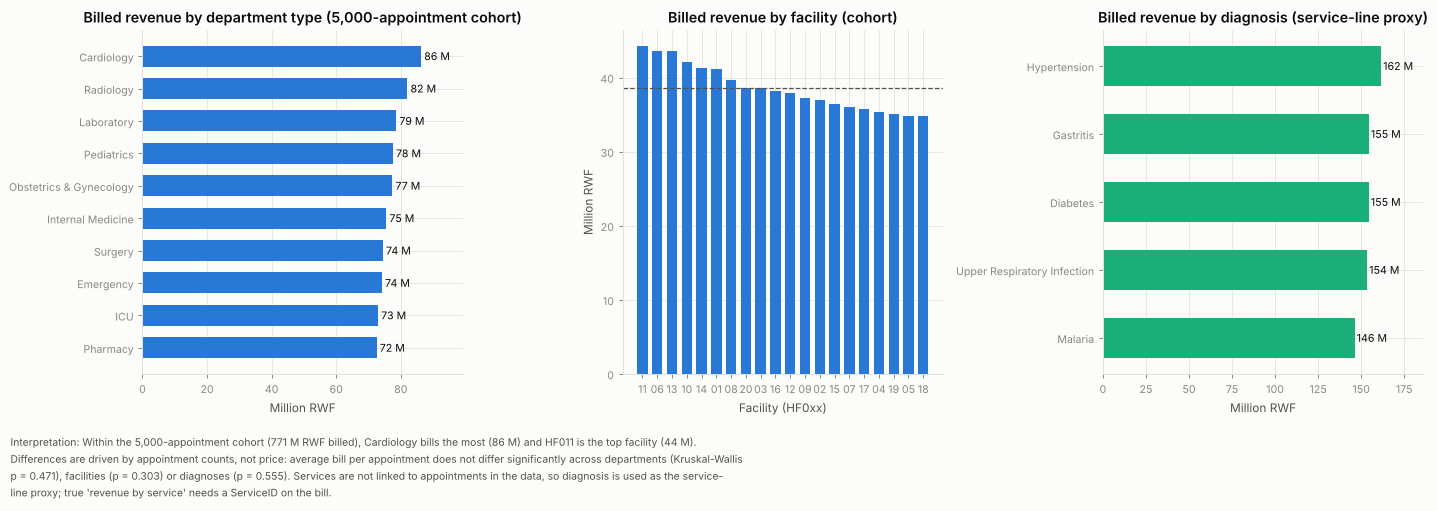

In [27]:
dep_rev = E.groupby("DepartmentName").agg(Revenue=("BillAmount", "sum"), Bills=("BillAmount", "size"), Mean=("BillAmount", "mean"), Sd=("BillAmount", "std")).sort_values("Revenue", ascending=False)
dep_rev["CI"] = 1.96 * dep_rev.Sd / np.sqrt(dep_rev.Bills)
fac_rev = E.groupby("FacilityID").agg(Revenue=("BillAmount", "sum"), Mean=("BillAmount", "mean")).sort_values("Revenue", ascending=False)
svc = E.assign(ServiceType="Consultation/Procedure")  # services are not linked to appointments -> documented
srv = E.groupby("Diagnosis").BillAmount.agg(["sum", "mean", "count"]).sort_values("sum", ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].barh(dep_rev.index[::-1], dep_rev.Revenue[::-1] / 1e6, color=C[0], height=.65)
for i, v in enumerate(dep_rev.Revenue[::-1]): ax[0].text(v / 1e6 + 1, i, f"{v / 1e6:.0f} M", va="center", fontsize=8.5)
ax[0].set(title="Billed revenue by department type (5,000-appointment cohort)", xlabel="Million RWF", xlim=(0, dep_rev.Revenue.max() / 1e6 * 1.15))
ax[1].bar(fac_rev.index.str[-2:], fac_rev.Revenue / 1e6, color=C[0], width=.7); ax[1].axhline(fac_rev.Revenue.mean() / 1e6, color=INK2, ls="--", lw=1)
ax[1].set(title="Billed revenue by facility (cohort)", xlabel="Facility (HF0xx)", ylabel="Million RWF")
ax[2].barh(srv.index[::-1], srv["sum"][::-1] / 1e6, color=C[2], height=.6)
for i, v in enumerate(srv["sum"][::-1]): ax[2].text(v / 1e6 + 1, i, f"{v / 1e6:.0f} M", va="center", fontsize=8.5)
ax[2].set(title="Billed revenue by diagnosis (service-line proxy)", xlabel="Million RWF", xlim=(0, srv["sum"].max() / 1e6 * 1.15))
fig.tight_layout()
kw_dep = stats.kruskal(*[g_.BillAmount.values for _, g_ in E.groupby("DepartmentName")])
kw_fac = stats.kruskal(*[g_.BillAmount.values for _, g_ in E.groupby("FacilityID")])
kw_dx = stats.kruskal(*[g_.BillAmount.values for _, g_ in E.groupby("Diagnosis")])
R["dep_rev_top"] = [dep_rev.index[0], float(dep_rev.Revenue.iloc[0])]; R["dep_rev_kw_p"] = float(kw_dep.pvalue); R["fac_rev_kw_p"] = float(kw_fac.pvalue); R["dx_rev_kw_p"] = float(kw_dx.pvalue)
R["fac_rev_top"] = [fac_rev.index[0], float(fac_rev.Revenue.iloc[0])]; R["cohort_billed"] = float(E.BillAmount.sum())
save_fig(fig, "f15_revenue_by_unit",
         f"Within the 5,000-appointment cohort ({E.BillAmount.sum() / 1e6:.0f} M RWF billed), {dep_rev.index[0]} bills the most ({dep_rev.Revenue.iloc[0] / 1e6:.0f} M) and {fac_rev.index[0]} is the top facility ({fac_rev.Revenue.iloc[0] / 1e6:.0f} M). "
         f"Differences are driven by appointment counts, not price: average bill per appointment does not differ significantly across departments (Kruskal-Wallis {fmt_p(kw_dep.pvalue)}), facilities ({fmt_p(kw_fac.pvalue)}) or diagnoses ({fmt_p(kw_dx.pvalue)}). "
         "Services are not linked to appointments in the data, so diagnosis is used as the service-line proxy; true 'revenue by service' needs a ServiceID on the bill.")

### 3.5 Patient experience

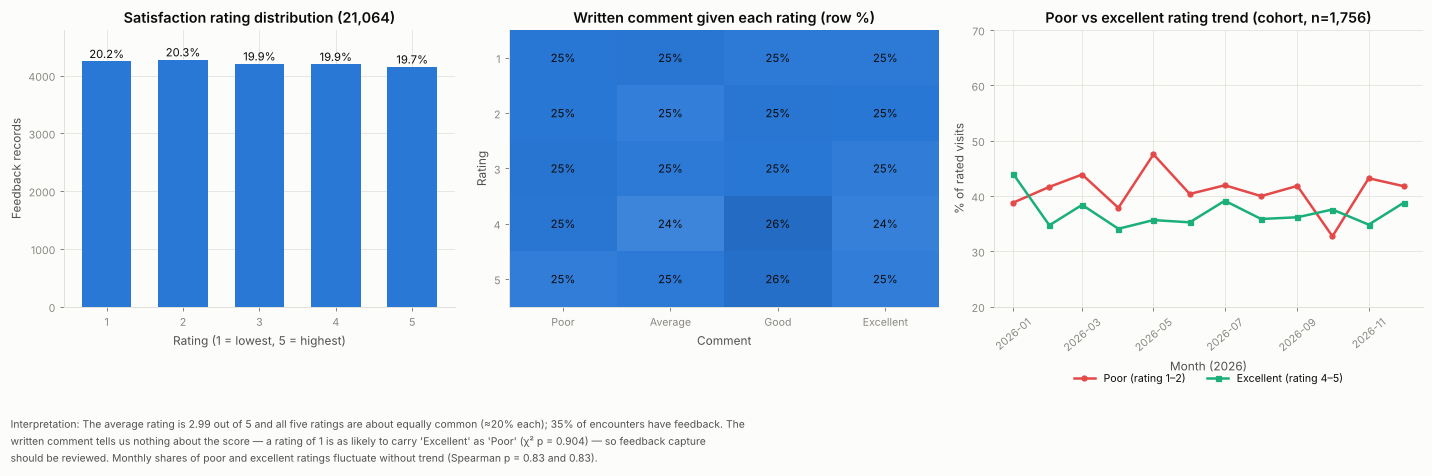

In [28]:
fb_u = fb.copy()
rate_d = fb_u.Rating.value_counts().sort_index()
rc = pd.crosstab(fb_u.Rating, fb_u.Comment, normalize="index").loc[:, ["Poor", "Average", "Good", "Excellent"]] * 100
chi_rc = stats.chi2_contingency(pd.crosstab(fb_u.Rating, fb_u.Comment))
Ef = E[E.Rating.notna()].copy()
mf = Ef.groupby("Month").agg(poor=("Rating", lambda s: (s <= 2).mean()), exc=("Rating", lambda s: (s >= 4).mean()), mean=("Rating", "mean"), n=("Rating", "size"))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
ax[0].bar(rate_d.index.astype(str), rate_d.values, color=C[0], width=.65)
for i, v in enumerate(rate_d.values): ax[0].text(i, v + 60, pct(v / len(fb_u)), ha="center", fontsize=9)
ax[0].set(title="Satisfaction rating distribution (21,064)", xlabel="Rating (1 = lowest, 5 = highest)", ylabel="Feedback records", ylim=(0, rate_d.max() * 1.12))
im = ax[1].imshow(rc.values, cmap=SEQ, aspect="auto", vmin=15, vmax=35)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(rc.columns); ax[1].set_yticks(range(5)); ax[1].set_yticklabels(rc.index); ax[1].grid(False)
for i in range(5):
    for j in range(4): ax[1].text(j, i, f"{rc.values[i, j]:.0f}%", ha="center", va="center", fontsize=9, color="white" if rc.values[i, j] > 27 else INK)
ax[1].set(title="Written comment given each rating (row %)", xlabel="Comment", ylabel="Rating")
ax[2].plot(mf.index, 100 * mf.poor, color=C[7], lw=2, marker="o", ms=4, label="Poor (rating 1–2)"); ax[2].plot(mf.index, 100 * mf.exc, color=C[2], lw=2, marker="s", ms=4, label="Excellent (rating 4–5)")
ax[2].set(title="Poor vs excellent rating trend (cohort, n=1,756)", xlabel="Month (2026)", ylabel="% of rated visits", ylim=(20, 70)); ax[2].legend(loc="upper center", ncol=2, bbox_to_anchor=(.5, -.2))
for t_ in ax[2].get_xticklabels(): t_.set_rotation(40)
fig.tight_layout()
tr_p = stats.spearmanr(np.arange(len(mf)), mf.poor); tr_e = stats.spearmanr(np.arange(len(mf)), mf.exc)
R["mean_rating"] = float(fb_u.Rating.mean()); R["rating_dist"] = (rate_d / len(fb_u)).to_dict(); R["rating_comment_p"] = float(chi_rc[1])
R["feedback_coverage"] = float(len(fb_u) / len(bill)); R["poor_trend"] = [float(tr_p[0]), float(tr_p[1])]; R["exc_trend"] = [float(tr_e[0]), float(tr_e[1])]
save_fig(fig, "f16_satisfaction",
         f"The average rating is {fb_u.Rating.mean():.2f} out of 5 and all five ratings are about equally common (≈20% each); {pct(len(fb_u) / len(bill), 0)} of encounters have feedback. "
         f"The written comment tells us nothing about the score — a rating of 1 is as likely to carry 'Excellent' as 'Poor' (χ² {fmt_p(chi_rc[1])}) — so feedback capture should be reviewed. "
         f"Monthly shares of poor and excellent ratings fluctuate without trend (Spearman p = {tr_p[1]:.2f} and {tr_e[1]:.2f}).")

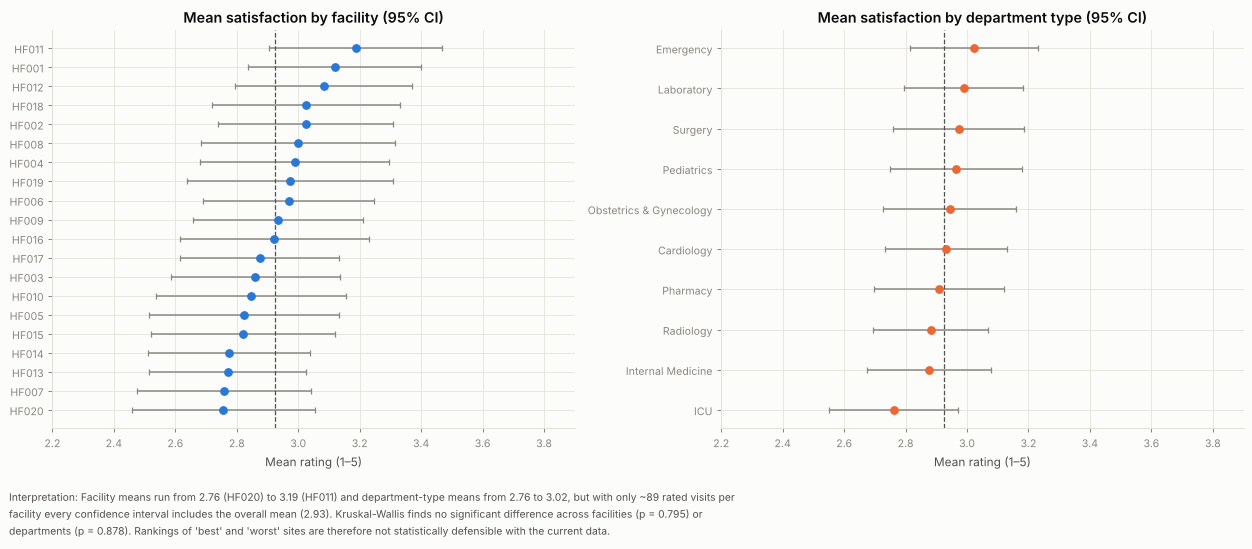

In [29]:
fs = Ef.groupby("FacilityID").Rating.agg(["mean", "std", "count"]); fs["ci"] = 1.96 * fs["std"] / np.sqrt(fs["count"]); fs = fs.sort_values("mean", ascending=False)
ds = Ef.groupby("DepartmentName").Rating.agg(["mean", "std", "count"]); ds["ci"] = 1.96 * ds["std"] / np.sqrt(ds["count"]); ds = ds.sort_values("mean", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
ax[0].errorbar(fs["mean"][::-1], range(len(fs)), xerr=fs.ci[::-1], fmt="o", color=C[0], ecolor=MUTED, elinewidth=1.2, capsize=2.5, ms=6)
ax[0].set_yticks(range(len(fs))); ax[0].set_yticklabels(fs.index[::-1]); ax[0].axvline(Ef.Rating.mean(), color=INK2, ls="--", lw=1)
ax[0].set(title="Mean satisfaction by facility (95% CI)", xlabel="Mean rating (1–5)", xlim=(2.2, 3.9))
ax[1].errorbar(ds["mean"][::-1], range(len(ds)), xerr=ds.ci[::-1], fmt="o", color=C[1], ecolor=MUTED, elinewidth=1.2, capsize=2.5, ms=6)
ax[1].set_yticks(range(len(ds))); ax[1].set_yticklabels(ds.index[::-1]); ax[1].axvline(Ef.Rating.mean(), color=INK2, ls="--", lw=1)
ax[1].set(title="Mean satisfaction by department type (95% CI)", xlabel="Mean rating (1–5)", xlim=(2.2, 3.9))
fig.tight_layout()
kw_fs = stats.kruskal(*[g_.Rating.values for _, g_ in Ef.groupby("FacilityID")]); kw_ds = stats.kruskal(*[g_.Rating.values for _, g_ in Ef.groupby("DepartmentName")])
R["sat_fac_p"], R["sat_dept_p"] = float(kw_fs.pvalue), float(kw_ds.pvalue)
R["sat_best_fac"] = [fs.index[0], float(fs["mean"].iloc[0])]; R["sat_worst_fac"] = [fs.index[-1], float(fs["mean"].iloc[-1])]
R["sat_best_dept"] = [ds.index[0], float(ds["mean"].iloc[0])]; R["sat_worst_dept"] = [ds.index[-1], float(ds["mean"].iloc[-1])]
all_overlap = bool(((fs["mean"] - Ef.Rating.mean()).abs() <= fs.ci).all())
save_fig(fig, "f17_satisfaction_comparison",
         f"Facility means run from {fs['mean'].iloc[-1]:.2f} ({fs.index[-1]}) to {fs['mean'].iloc[0]:.2f} ({fs.index[0]}) and department-type means from {ds['mean'].iloc[-1]:.2f} to {ds['mean'].iloc[0]:.2f}, but with only ~{int(fs['count'].median())} rated visits per facility {'every confidence interval includes' if all_overlap else 'most confidence intervals include'} the overall mean "
         f"({Ef.Rating.mean():.2f}). Kruskal-Wallis finds no significant difference across facilities ({fmt_p(kw_fs.pvalue)}) or departments ({fmt_p(kw_ds.pvalue)}). Rankings of 'best' and 'worst' sites are therefore not statistically defensible with the current data.")

## 4. Statistical analysis
### 4.1 Descriptive statistics
Mean, median, mode, standard deviation, variance, quartiles and percentiles for the key numeric variables, each on the
most complete data source available for that variable (the base is shown in the `Source` column).

In [30]:
def describe_full(s, name, source):
    s = pd.Series(s).dropna().astype(float)
    mode = s.round(0).mode().iloc[0] if s.nunique() > 50 else s.mode().iloc[0]
    q = s.quantile([.05, .10, .25, .5, .75, .90, .95, .99])
    return {"Variable": name, "Source": source, "n": len(s), "Mean": s.mean(), "Median": s.median(), "Mode": mode, "Std Dev": s.std(), "Variance": s.var(),
            "Min": s.min(), "P5": q[.05], "P10": q[.10], "Q1 (P25)": q[.25], "Q3 (P75)": q[.75], "P90": q[.90], "P95": q[.95], "P99": q[.99], "Max": s.max(),
            "IQR": q[.75] - q[.25], "Skewness": stats.skew(s), "Excess kurtosis": stats.kurtosis(s), "CV %": 100 * s.std() / s.mean() if s.mean() else np.nan}

staff_exp = STAFF.YearsExperience
desc_rows = [
    describe_full(PATIENTS.Age, "Patient age (years)", "Patients (20,000)"),
    describe_full(PATIENTS.BMI, "BMI (kg/m²)", "Patients (20,000)"),
    describe_full(PATIENTS.HeightCm, "Height (cm)", "Patients (20,000)"),
    describe_full(PATIENTS.WeightKg, "Weight (kg)", "Patients (20,000)"),
    describe_full(adm_all.LengthOfStayDays, "Length of stay (days)", "Admissions (5,000)"),
    describe_full(FIN.BillAmount, "Bill amount (RWF)", "Billing (60,000)"),
    describe_full(FIN.AmountPaid, "Amount paid (RWF)", "Payments (60,000)"),
    describe_full(FIN.Outstanding, "Outstanding balance (RWF)", "Billing − Payments (60,000)"),
    describe_full(FIN.ClaimAmount, "Claim amount (RWF)", "Insurance claims (42,036)"),
    describe_full(FIN.ClaimRatio, "Claim ÷ bill", "Insurance claims (42,036)"),
    describe_full(fb.Rating, "Satisfaction rating (1–5)", "Feedback (21,064)"),
    describe_full(staff_exp, "Staff experience (years)", "All staff (1,250)"),
    describe_full(doc_load, "Appointments per doctor", "Appointments × doctors (350)"),
    describe_full(rs.Revenue / 1e6, "Monthly revenue (M RWF)", "Revenue summary (12)"),
    describe_full(rs.Appointments, "Monthly appointments", "Revenue summary (12)"),
]
DESC = pd.DataFrame(desc_rows)
R["descriptives"] = DESC.round(3).to_dict("records")
pd.options.display.float_format = "{:,.2f}".format
DESC.set_index("Variable")[["Source", "n", "Mean", "Median", "Mode", "Std Dev", "Variance", "Q1 (P25)", "Q3 (P75)", "P5", "P95", "Skewness", "CV %"]]

,Source,n,Mean,Median,Mode,Std Dev,Variance,Q1 (P25),Q3 (P75),P5,P95,Skewness,CV %
Variable,,,,,,,,,,,,,
Patient age (years),"Patients (20,000)",20000,45.03,45.00,90.00,26.26,689.64,22.00,68.00,4.00,86.00,0.01,58.31
BMI (kg/m²),"Patients (20,000)",20000,30.04,29.20,32.00,10.43,108.70,21.70,36.90,15.00,49.30,0.46,34.70
Height (cm),"Patients (20,000)",20000,164.90,165.00,152.00,14.79,218.75,152.00,178.00,142.00,188.00,0.02,8.97
Weight (kg),"Patients (20,000)",20000,79.76,80.00,78.00,23.38,546.62,60.00,100.00,44.00,116.00,0.01,29.31
Length of stay (days),"Admissions (5,000)",5000,5.49,6.00,2.00,2.87,8.26,3.00,8.00,1.00,10.00,-0.01,52.38
Bill amount (RWF),"Billing (60,000)",60000,"155,156.70","155,247.00","36,833.00","83,840.37","7,029,207,256.60","82,275.25","227,907.75","24,717.85","285,651.70",-0.00,54.04
Amount paid (RWF),"Payments (60,000)",60000,"139,824.24","129,821.50","129,528.00","83,370.19","6,950,588,556.41","68,694.25","210,240.00","20,555.95","282,129.45",0.26,59.62
Outstanding balance (RWF),"Billing − Payments (60,000)",60000,"15,332.46",0.00,0.00,"36,038.07","1,298,742,597.62",0.00,0.00,0.00,"113,261.25",2.33,235.04
Claim amount (RWF),"Insurance claims (42,036)",42036,"116,135.30","111,421.64","42,625.00","67,812.49","4,598,533,237.18","59,153.72","165,174.94","17,900.12","236,446.77",0.33,58.39


In [31]:
# categorical modes + normality checks
cat_modes = pd.DataFrame({"Variable": ["Gender", "Blood group", "Chronic condition", "Diagnosis", "Severity", "Visit type", "Lab test", "Medication", "Payment method", "Claim provider", "Rating"],
                          "Mode": [PATIENTS.Gender.mode()[0], PATIENTS.BloodGroup.mode()[0], PATIENTS.ChronicCondition.mode()[0], E.Diagnosis.mode()[0], E.Severity.mode()[0], E.VisitType.mode()[0],
                                   labs_t.Test.mode()[0], rx_t.Medication.mode()[0], pay.Method.mode()[0], clm.Provider.mode()[0], int(fb.Rating.mode()[0])],
                          "Share": [PATIENTS.Gender.value_counts(normalize=True).iloc[0], PATIENTS.BloodGroup.value_counts(normalize=True).iloc[0], PATIENTS.ChronicCondition.value_counts(normalize=True).iloc[0],
                                    E.Diagnosis.value_counts(normalize=True).iloc[0], E.Severity.value_counts(normalize=True).iloc[0], E.VisitType.value_counts(normalize=True).iloc[0],
                                    labs_t.Test.value_counts(normalize=True).iloc[0], rx_t.Medication.value_counts(normalize=True).iloc[0], pay.Method.value_counts(normalize=True).iloc[0],
                                    clm.Provider.value_counts(normalize=True).iloc[0], fb.Rating.value_counts(normalize=True).iloc[0]]})
cat_modes["Share"] = (100 * cat_modes.Share).round(1).astype(str) + "%"
R["cat_modes"] = cat_modes.to_dict("records")
norm = []
for nm, s in [("Patient age", PATIENTS.Age), ("BMI", PATIENTS.BMI), ("Bill amount", FIN.BillAmount), ("Length of stay", adm_all.LengthOfStayDays), ("Staff experience", staff_exp)]:
    smp = s.sample(min(len(s), 5000), random_state=SEED)
    nt = stats.normaltest(s); sw = stats.shapiro(smp)
    uni = stats.kstest((s - s.min()) / (s.max() - s.min()), "uniform")
    norm.append({"Variable": nm, "Shapiro-Wilk p": sw.pvalue, "D'Agostino p": nt.pvalue, "Skew": stats.skew(s), "KS vs uniform p": uni.pvalue,
                 "Verdict": "Not normal; consistent with uniform" if (nt.pvalue < .05 and uni.pvalue > .05) else ("Not normal" if nt.pvalue < .05 else "Cannot reject normality")})
NORM = pd.DataFrame(norm); R["normality"] = NORM.round(4).to_dict("records")
print(cat_modes.to_string(index=False)); print()
NORM

         Variable         Mode Share
           Gender         Male 50.4%
      Blood group          AB+ 14.6%
Chronic condition         None 25.4%
        Diagnosis Hypertension 21.2%
         Severity     Moderate 33.9%
       Visit type    Follow-up 33.9%
         Lab test      Malaria 25.4%
       Medication   Amlodipine 21.4%
   Payment method         Card 25.2%
   Claim provider      Radiant 25.3%
           Rating            2 20.3%



,Variable,Shapiro-Wilk p,D'Agostino p,Skew,KS vs uniform p,Verdict
0,Patient age,0.00,0.00,0.01,0.00,Not normal
1,BMI,0.00,0.00,0.46,0.00,Not normal
2,Bill amount,0.00,0.00,-0.00,0.92,Not normal; consistent with uniform
3,Length of stay,0.00,0.00,-0.01,0.00,Not normal
4,Staff experience,0.00,0.00,0.02,0.01,Not normal


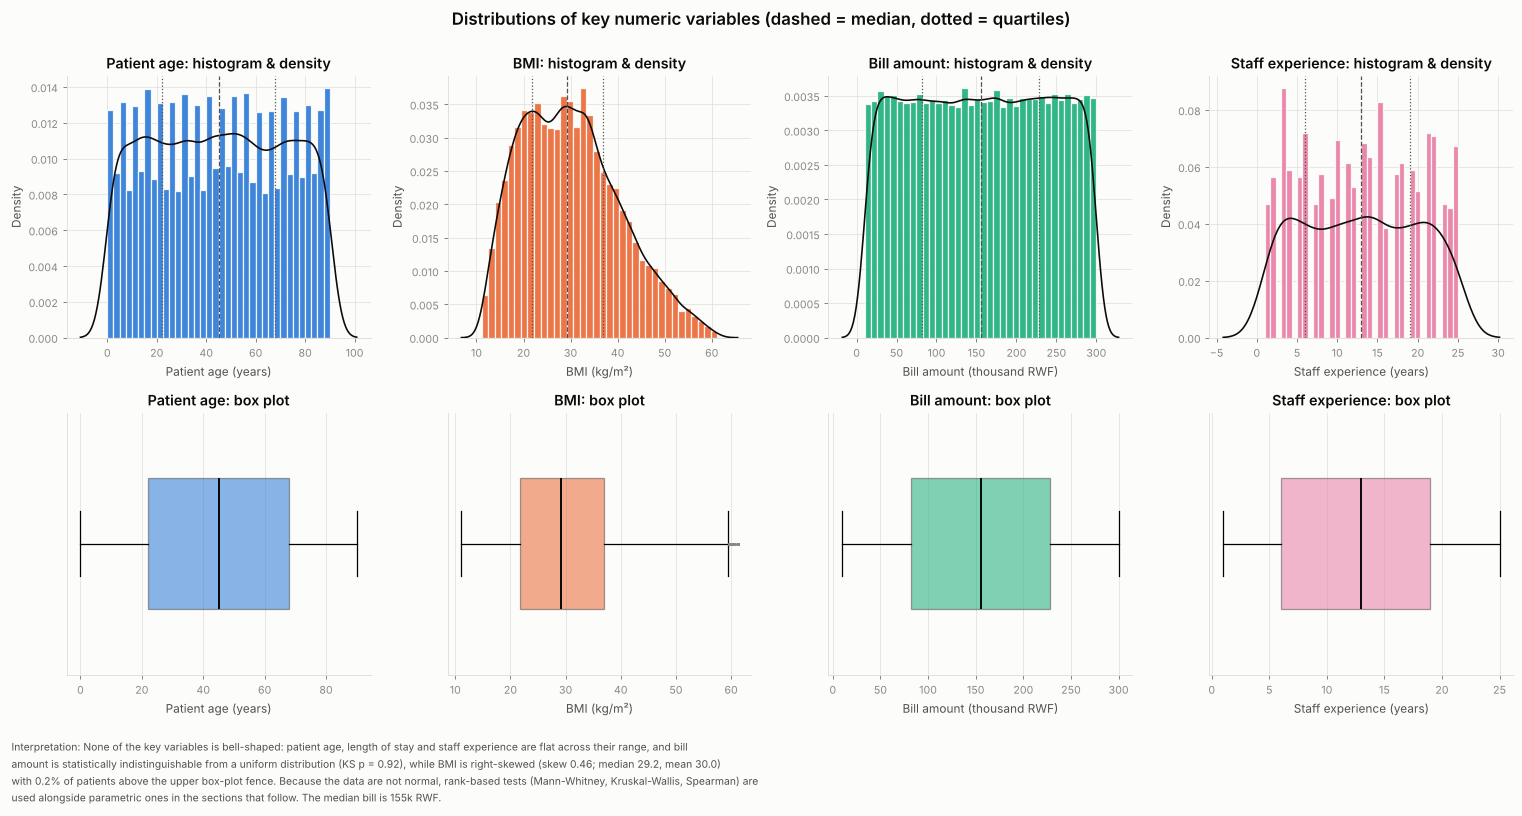

In [32]:
fig, ax = plt.subplots(2, 4, figsize=(17, 8))
specs = [(PATIENTS.Age, "Patient age (years)", C[0]), (PATIENTS.BMI, "BMI (kg/m²)", C[1]), (FIN.BillAmount / 1e3, "Bill amount (thousand RWF)", C[2]), (staff_exp, "Staff experience (years)", C[4])]
for j, (s_, lab_, col) in enumerate(specs):
    ax[0, j].hist(s_, bins=36, color=col, edgecolor=SURF, density=True, alpha=.9)
    sns.kdeplot(s_, ax=ax[0, j], color=INK, lw=1.3)
    for p_, ls_ in [(.25, ":"), (.5, "--"), (.75, ":")]: ax[0, j].axvline(s_.quantile(p_), color=INK2, ls=ls_, lw=1)
    ax[0, j].set(title=f"{lab_.split(' (')[0]}: histogram & density", xlabel=lab_, ylabel="Density")
    ax[1, j].boxplot(s_.dropna(), vert=False, widths=.5, patch_artist=True, boxprops=dict(facecolor=col, alpha=.55, edgecolor=INK2), medianprops=dict(color=INK, lw=1.6), flierprops=dict(marker=".", ms=2, markeredgecolor=MUTED))
    ax[1, j].set(title=f"{lab_.split(' (')[0]}: box plot", xlabel=lab_, yticks=[]); ax[1, j].grid(axis="y", visible=False)
fig.suptitle("Distributions of key numeric variables (dashed = median, dotted = quartiles)", fontsize=13.5, fontweight="semibold", y=1.0)
fig.tight_layout()
out_bmi = ((PATIENTS.BMI > PATIENTS.BMI.quantile(.75) + 1.5 * stats.iqr(PATIENTS.BMI))).mean()
R["bmi_outlier_pct"] = float(out_bmi)
save_fig(fig, "f18_distributions",
         f"None of the key variables is bell-shaped: patient age, length of stay and staff experience are flat across their range, and bill amount is statistically indistinguishable from a uniform distribution (KS p = {stats.kstest((FIN.BillAmount - FIN.BillAmount.min()) / (FIN.BillAmount.max() - FIN.BillAmount.min()), 'uniform').pvalue:.2f}), "
         f"while BMI is right-skewed (skew {stats.skew(PATIENTS.BMI):.2f}; median {PATIENTS.BMI.median():.1f}, mean {PATIENTS.BMI.mean():.1f}) with {pct(out_bmi)} of patients above the upper box-plot fence. "
         f"Because the data are not normal, rank-based tests (Mann-Whitney, Kruskal-Wallis, Spearman) are used alongside parametric ones in the sections that follow. The median bill is {FIN.BillAmount.median() / 1e3:.0f}k RWF.")

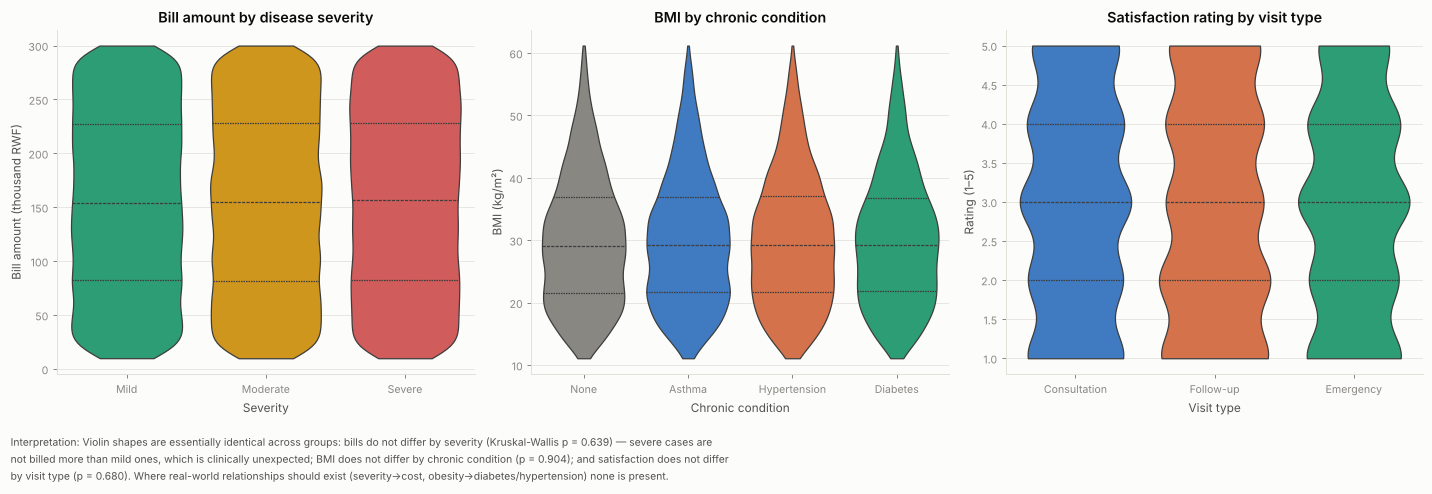

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
order_s = ["Mild", "Moderate", "Severe"]
sns.violinplot(data=FIN.dropna(subset=["Severity"]), x="Severity", y=FIN.BillAmount / 1e3, order=order_s, palette=[C[2], C[3], C[7]], inner="quartile", linewidth=1, ax=ax[0], cut=0)
ax[0].set(title="Bill amount by disease severity", xlabel="Severity", ylabel="Bill amount (thousand RWF)")
sns.violinplot(data=PATIENTS, x="ChronicCondition", y="BMI", order=["None", "Asthma", "Hypertension", "Diabetes"], palette=[MUTED, C[0], C[1], C[2]], inner="quartile", linewidth=1, ax=ax[1], cut=0)
ax[1].set(title="BMI by chronic condition", xlabel="Chronic condition", ylabel="BMI (kg/m²)")
sns.violinplot(data=E.dropna(subset=["Rating"]), x="VisitType", y="Rating", order=["Consultation", "Follow-up", "Emergency"], palette=[C[0], C[1], C[2]], inner="quartile", linewidth=1, ax=ax[2], cut=0)
ax[2].set(title="Satisfaction rating by visit type", xlabel="Visit type", ylabel="Rating (1–5)")
fig.tight_layout()
kw_sev_bill = stats.kruskal(*[g_.BillAmount.values for _, g_ in FIN.dropna(subset=["Severity"]).groupby("Severity")])
kw_bmi_chr = stats.kruskal(*[g_.BMI.values for _, g_ in PATIENTS.groupby("ChronicCondition")])
kw_vt_rat = stats.kruskal(*[g_.Rating.values for _, g_ in E.dropna(subset=["Rating"]).groupby("VisitType")])
R["bill_sev_p"], R["bmi_chronic_p"], R["rating_visit_p"] = float(kw_sev_bill.pvalue), float(kw_bmi_chr.pvalue), float(kw_vt_rat.pvalue)
save_fig(fig, "f19_violins",
         f"Violin shapes are essentially identical across groups: bills do not differ by severity (Kruskal-Wallis {fmt_p(kw_sev_bill.pvalue)}) — severe cases are not billed more than mild ones, which is clinically unexpected; "
         f"BMI does not differ by chronic condition ({fmt_p(kw_bmi_chr.pvalue)}); and satisfaction does not differ by visit type ({fmt_p(kw_vt_rat.pvalue)}). Where real-world relationships should exist (severity→cost, obesity→diabetes/hypertension) none is present.")

### 4.2 Correlation analysis
The six relationships required by the brief. Each uses the largest valid sample, the appropriate coefficient, and reports an effect size so that
"significant" is not confused with "important". Strength labels: |r| < 0.1 negligible, 0.1–0.3 weak, 0.3–0.5 moderate, > 0.5 strong.

In [34]:
def strength(r):
    r = abs(r); return "negligible" if r < .1 else "weak" if r < .3 else "moderate" if r < .5 else "strong"

def eps2(H, n): return H / (n - 1)
CORR = []
# 1 Age ~ admission
pb = stats.pointbiserialr(E.Admitted, E.Age); sp1 = stats.spearmanr(E.Age, E.Admitted)
CORR.append(dict(Pair="Age ↔ hospital admission (0/1)", Data="Appointment cohort", n=len(E), Method="Point-biserial (Spearman ρ = %.3f)" % sp1[0], Coefficient=pb[0], p_value=pb[1], Strength=strength(pb[0])))
# 2 Age ~ billing
pr2 = stats.pearsonr(E.Age, E.BillAmount); sp2 = stats.spearmanr(E.Age, E.BillAmount)
CORR.append(dict(Pair="Age ↔ billing amount", Data="Appointment cohort", n=len(E), Method="Pearson (Spearman ρ = %.3f)" % sp2[0], Coefficient=pr2[0], p_value=pr2[1], Strength=strength(pr2[0])))
# 3 Diagnosis ~ LOS
Ea = E[E.Admitted == 1]
kw3 = stats.kruskal(*[g_.LengthOfStayDays.values for _, g_ in Ea.groupby("Diagnosis")]); an3 = stats.f_oneway(*[g_.LengthOfStayDays.values for _, g_ in Ea.groupby("Diagnosis")])
grand = Ea.LengthOfStayDays.mean(); ssb = sum(len(g_) * (g_.LengthOfStayDays.mean() - grand) ** 2 for _, g_ in Ea.groupby("Diagnosis")); sst = ((Ea.LengthOfStayDays - grand) ** 2).sum()
eta = np.sqrt(ssb / sst)
CORR.append(dict(Pair="Diagnosis ↔ length of stay", Data="Admitted cohort", n=len(Ea), Method="Kruskal-Wallis; η = %.3f (ANOVA p = %.3f)" % (eta, an3.pvalue), Coefficient=eta, p_value=kw3.pvalue, Strength=strength(eta)))
# 4 Department workload ~ satisfaction (department-ID level, department-type level, facility level)
dsat = DEPT.dropna(subset=["MeanRating", "WorkloadIndex"]); sp4 = stats.spearmanr(dsat.WorkloadIndex, dsat.MeanRating)
CORR.append(dict(Pair="Department workload index ↔ mean satisfaction", Data="200 departments (IDs)", n=len(dsat), Method="Spearman", Coefficient=sp4[0], p_value=sp4[1], Strength=strength(sp4[0])))
dts = Ef.groupby("DepartmentName").Rating.mean(); sp4b = stats.spearmanr(DEPTT.WorkloadIndex.loc[dts.index], dts)
CORR.append(dict(Pair="  … same, 10 department types", Data="10 department types", n=len(dts), Method="Spearman", Coefficient=sp4b[0], p_value=sp4b[1], Strength=strength(sp4b[0])))
sp4c = stats.spearmanr(K.ApptPerClinician, K.MeanRating)
CORR.append(dict(Pair="  … same, 20 facilities (appts per clinician)", Data="20 facilities", n=len(K), Method="Spearman", Coefficient=sp4c[0], p_value=sp4c[1], Strength=strength(sp4c[0])))
# 5 Revenue ~ patient volume
pr5 = stats.pearsonr(rs.Revenue, rs.Appointments); sp5 = stats.spearmanr(rs.Revenue, rs.Appointments)
CORR.append(dict(Pair="Monthly revenue ↔ monthly appointments", Data="Revenue summary, 12 months", n=12, Method="Pearson (Spearman ρ = %.3f)" % sp5[0], Coefficient=pr5[0], p_value=pr5[1], Strength=strength(pr5[0])))
pr5b = stats.pearsonr(K.BilledTotal, K.Appointments)
CORR.append(dict(Pair="  … facility billed revenue ↔ appointments", Data="20 facilities (cohort)", n=20, Method="Pearson", Coefficient=pr5b[0], p_value=pr5b[1], Strength=strength(pr5b[0])))
# 6 Insurance coverage ~ utilisation
vis_kw = stats.kruskal(*[g_.Visits2026.values for _, g_ in PATIENTS.groupby("InsuranceID")])
chi6 = stats.chi2_contingency(pd.crosstab(PATIENTS.InsuranceID, PATIENTS.Visits2026 > 0)); v6 = np.sqrt(chi6[0] / (len(PATIENTS) * 14))
CORR.append(dict(Pair="Insurance code (15) ↔ healthcare utilisation (visited yes/no)", Data="20,000 patients", n=len(PATIENTS), Method="χ²; Cramér's V = %.3f" % v6, Coefficient=v6, p_value=chi6[1], Strength=strength(v6)))
cv = FIN.dropna(subset=["ClaimRatio"]); sp6 = stats.spearmanr(cv.ClaimRatio, cv.BillAmount)
CORR.append(dict(Pair="Claim coverage ratio ↔ bill amount", Data="42,036 bills with claims", n=len(cv), Method="Spearman", Coefficient=sp6[0], p_value=sp6[1], Strength=strength(sp6[0])))
fcl = stats.mannwhitneyu(FIN[FIN.HasClaim == 1].BillAmount, FIN[FIN.HasClaim == 0].BillAmount)
CORR.append(dict(Pair="Claim filed (0/1) ↔ bill amount", Data="60,000 bills", n=len(FIN), Method="Point-biserial", Coefficient=stats.pointbiserialr(FIN.HasClaim, FIN.BillAmount)[0], p_value=fcl.pvalue, Strength=strength(stats.pointbiserialr(FIN.HasClaim, FIN.BillAmount)[0])))
CORRT = pd.DataFrame(CORR); CORRT["Significant (α=.05)"] = np.where(CORRT.p_value < .05, "Yes", "No")
R["correlations"] = CORRT.round(4).to_dict("records")
pd.options.display.float_format = "{:,.4f}".format
CORRT[["Pair", "Data", "n", "Method", "Coefficient", "p_value", "Strength", "Significant (α=.05)"]]

,Pair,Data,n,Method,Coefficient,p_value,Strength,Significant (α=.05)
0,Age ↔ hospital admission (0/1),Appointment cohort,5000,Point-biserial (Spearman ρ = 0.021),0.0215,0.1290,negligible,No
1,Age ↔ billing amount,Appointment cohort,5000,Pearson (Spearman ρ = -0.003),-0.0025,0.8592,negligible,No
2,Diagnosis ↔ length of stay,Admitted cohort,586,Kruskal-Wallis; η = 0.073 (ANOVA p = 0.544),0.0727,0.5384,negligible,No
3,Department workload index ↔ mean satisfaction,200 departments (IDs),200,Spearman,-0.0245,0.7310,negligible,No
4,"… same, 10 department types",10 department types,10,Spearman,0.2249,0.5321,weak,No
5,"… same, 20 facilities (appts per clinician)",20 facilities,20,Spearman,0.0188,0.9373,negligible,No
6,Monthly revenue ↔ monthly appointments,"Revenue summary, 12 months",12,Pearson (Spearman ρ = 0.329),0.2845,0.3701,weak,No
7,… facility billed revenue ↔ appointments,20 facilities (cohort),20,Pearson,0.8964,0.0000,strong,Yes
8,Insurance code (15) ↔ healthcare utilisation (visited yes/no),"20,000 patients",20000,χ²; Cramér's V = 0.006,0.0062,0.6931,negligible,No
9,Claim coverage ratio ↔ bill amount,"42,036 bills with claims",42036,Spearman,0.0008,0.8620,negligible,No


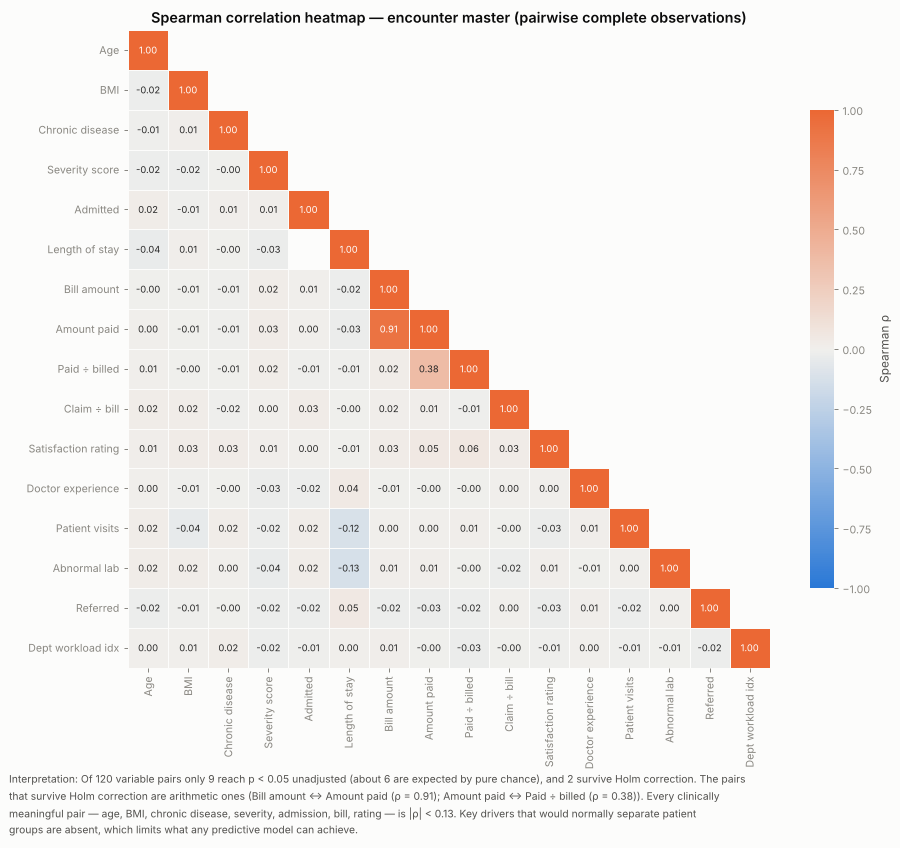

In [35]:
# Full Spearman correlation matrix on the encounter master + multiple-testing reality check
E["LabAbnormalNum"] = np.where(E.LabDone == 1, E.LabAbnormal, np.nan)
cm_cols = {"Age": "Age", "BMI": "BMI", "ChronicFlag": "Chronic disease", "SeverityScore": "Severity score", "Admitted": "Admitted", "LengthOfStayDays": "Length of stay",
           "BillAmount": "Bill amount", "AmountPaid": "Amount paid", "PaidRatio": "Paid ÷ billed", "ClaimRatio": "Claim ÷ bill", "Rating": "Satisfaction rating",
           "DoctorYearsExp": "Doctor experience", "PatientVisits": "Patient visits", "LabAbnormalNum": "Abnormal lab", "Referred": "Referred", "DeptWorkloadIndex": "Dept workload idx"}
M = E[list(cm_cols)].rename(columns=cm_cols).astype(float)
rho = M.corr(method="spearman")
pv = pd.DataFrame(np.ones_like(rho.values), index=rho.index, columns=rho.columns); nn = pv.copy()
for a_, b_ in itertools.combinations(M.columns, 2):
    d_ = M[[a_, b_]].dropna()
    r_, p_ = stats.spearmanr(d_[a_], d_[b_]); pv.loc[a_, b_] = pv.loc[b_, a_] = p_; nn.loc[a_, b_] = nn.loc[b_, a_] = len(d_)
iu = np.triu_indices(len(rho), 1)
n_pairs = len(iu[0]); n_sig = int((pv.values[iu] < .05).sum())
pairs = pd.DataFrame({"A": rho.index[iu[0]], "B": rho.columns[iu[1]], "rho": rho.values[iu], "p": pv.values[iu], "n": nn.values[iu]})
pairs["abs"] = pairs.rho.abs(); top_pairs = pairs.sort_values("abs", ascending=False).head(8)
def holm(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for i, idx in enumerate(o): run = max(run, (m - i) * p[idx]); adj[idx] = min(1, run)
    return adj
pairs["p_holm"] = holm(pairs.p.values); n_sig_holm = int((pairs.p_holm < .05).sum())
R["corr_matrix_pairs"], R["corr_matrix_sig"], R["corr_matrix_sig_holm"] = int(n_pairs), n_sig, n_sig_holm
R["corr_top"] = top_pairs.round(3).to_dict("records")
fig, ax = plt.subplots(figsize=(11.5, 9.2))
mask = np.triu(np.ones_like(rho, dtype=bool), 1)
sns.heatmap(rho, mask=mask, cmap=DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 7.5}, linewidths=.6, linecolor=SURF, cbar_kws={"label": "Spearman ρ", "shrink": .75}, ax=ax)
ax.set(title="Spearman correlation heatmap — encounter master (pairwise complete observations)"); ax.grid(False)
by_design = [("Admitted", "Length of stay"), ("Bill amount", "Amount paid"), ("Amount paid", "Paid ÷ billed"), ("Bill amount", "Paid ÷ billed"), ("Bill amount", "Claim ÷ bill")]
save_fig(fig, "f20_correlation_heatmap",
         f"Of {n_pairs} variable pairs only {n_sig} reach p < 0.05 unadjusted (about {int(round(.05 * n_pairs))} are expected by pure chance), and {n_sig_holm} survive Holm correction. "
         f"The pairs that survive Holm correction are arithmetic ones ({'; '.join(f'{r_.A} ↔ {r_.B} (ρ = {r_.rho:.2f})' for _, r_ in pairs[pairs.p_holm < .05].iterrows())}). Every clinically meaningful pair — age, BMI, chronic disease, severity, admission, bill, rating — is |ρ| < 0.13. "
         "Key drivers that would normally separate patient groups are absent, which limits what any predictive model can achieve.")

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


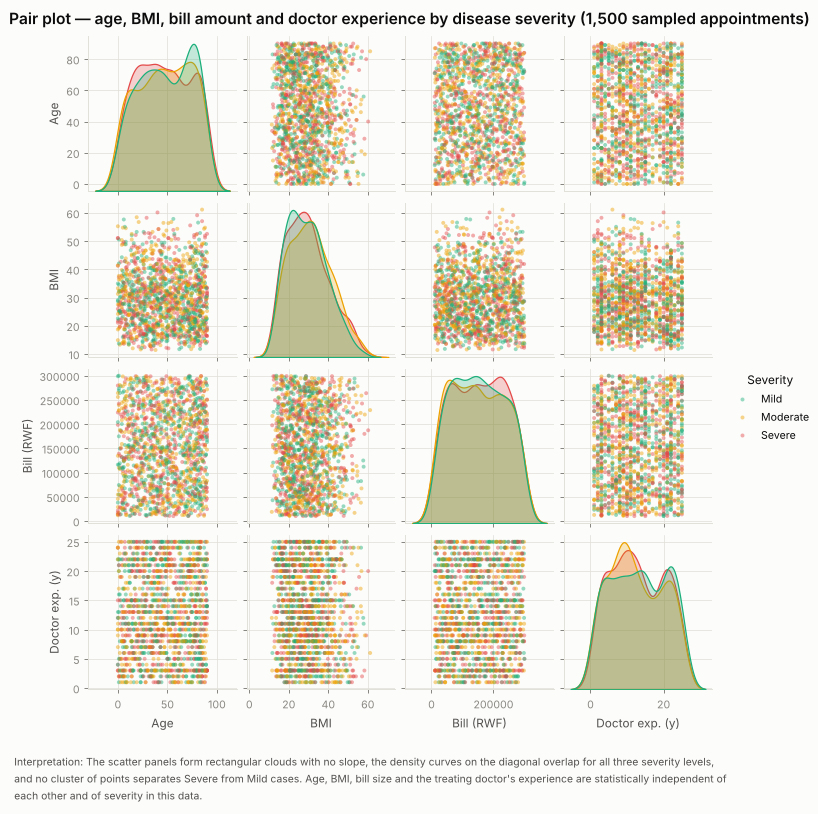

In [36]:
samp = E.sample(1500, random_state=SEED)[["Age", "BMI", "BillAmount", "DoctorYearsExp", "Severity"]].rename(columns={"BillAmount": "Bill (RWF)", "DoctorYearsExp": "Doctor exp. (y)"})
g_ = sns.pairplot(samp, hue="Severity", hue_order=["Mild", "Moderate", "Severe"], palette=[C[2], C[3], C[7]], diag_kind="kde", plot_kws=dict(s=10, alpha=.45, linewidth=0), height=2.0, corner=False)
g_.figure.suptitle("Pair plot — age, BMI, bill amount and doctor experience by disease severity (1,500 sampled appointments)", y=1.02, fontsize=12.5, fontweight="semibold")
save_fig(g_.figure, "f21_pairplot", "The scatter panels form rectangular clouds with no slope, the density curves on the diagonal overlap for all three severity levels, and no cluster of points separates Severe from Mild cases. "
         "Age, BMI, bill size and the treating doctor's experience are statistically independent of each other and of severity in this data.", title="Pair plot — age, BMI, bill amount, doctor experience by severity")

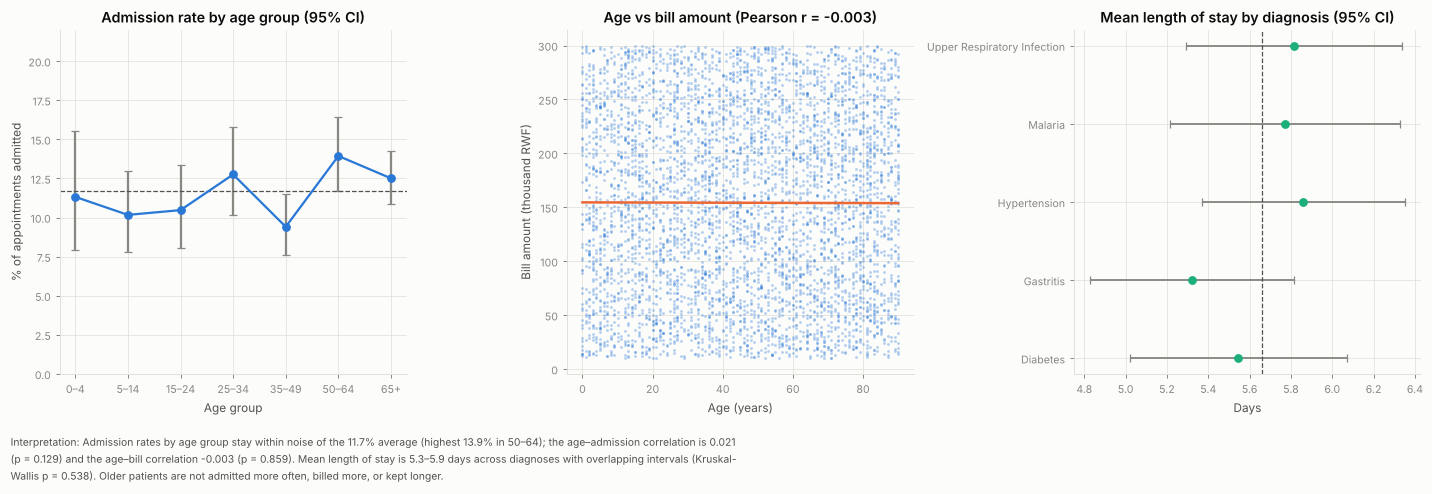

In [37]:
ag = E.groupby("AgeGroup", observed=True).agg(n=("Admitted", "size"), adm=("Admitted", "sum"), bill=("BillAmount", "mean"))
ag["rate"] = ag.adm / ag.n
lo, hi = zip(*[stats.beta.interval(.95, k + .5, n - k + .5) for k, n in zip(ag.adm, ag.n)])
dl = Ea.groupby("Diagnosis").LengthOfStayDays.agg(["mean", "std", "count"]); dl["ci"] = 1.96 * dl["std"] / np.sqrt(dl["count"])
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].errorbar(range(len(ag)), 100 * ag.rate, yerr=[100 * (ag.rate - np.array(lo)), 100 * (np.array(hi) - ag.rate)], fmt="o-", color=C[0], ecolor=MUTED, capsize=3, lw=1.8)
ax[0].axhline(100 * E.Admitted.mean(), color=INK2, ls="--", lw=1); ax[0].set_xticks(range(len(ag))); ax[0].set_xticklabels(ag.index.astype(str))
ax[0].set(title="Admission rate by age group (95% CI)", xlabel="Age group", ylabel="% of appointments admitted", ylim=(0, 22))
ax[1].scatter(E.Age, E.BillAmount / 1e3, s=5, alpha=.35, color=C[0], linewidths=0); xs_ = np.linspace(0, 90, 50); b_ = np.polyfit(E.Age, E.BillAmount / 1e3, 1)
ax[1].plot(xs_, np.polyval(b_, xs_), color=C[1], lw=2); ax[1].set(title=f"Age vs bill amount (Pearson r = {pr2[0]:.3f})", xlabel="Age (years)", ylabel="Bill amount (thousand RWF)")
ax[2].errorbar(dl["mean"], range(len(dl)), xerr=dl.ci, fmt="o", color=C[2], ecolor=MUTED, capsize=3); ax[2].set_yticks(range(len(dl))); ax[2].set_yticklabels(dl.index)
ax[2].axvline(Ea.LengthOfStayDays.mean(), color=INK2, ls="--", lw=1); ax[2].set(title="Mean length of stay by diagnosis (95% CI)", xlabel="Days")
fig.tight_layout()
save_fig(fig, "f22_age_admission_bill_los",
         f"Admission rates by age group stay within noise of the {pct(E.Admitted.mean())} average (highest {100 * ag.rate.max():.1f}% in {ag.rate.idxmax()}); the age–admission correlation is {pb[0]:.3f} ({fmt_p(pb[1])}) and the age–bill correlation {pr2[0]:.3f} ({fmt_p(pr2[1])}). "
         f"Mean length of stay is {dl['mean'].min():.1f}–{dl['mean'].max():.1f} days across diagnoses with overlapping intervals (Kruskal-Wallis {fmt_p(kw3.pvalue)}). Older patients are not admitted more often, billed more, or kept longer.")

### 4.3 What drives hospital admission? (business question 1)
Every candidate factor available at or around the time of the appointment is tested against admission (n = 5,000, 586 admitted).
Categorical factors use a χ² test (Cramér's V), numeric factors a Mann-Whitney test; p-values are Holm-adjusted for the number of factors screened.

In [38]:
fac_tests = []
Ec = E.copy(); Ec["Province"] = Ec.ProvinceName; Ec["Month_"] = Ec.MonthNum.astype(str)
for col, nm in [("VisitType", "Visit type"), ("Severity", "Disease severity"), ("Diagnosis", "Diagnosis"), ("DepartmentName", "Department type"), ("Gender", "Gender"), ("AgeGroup", "Age group"),
                ("ChronicCondition", "Chronic condition"), ("HighRisk", "High-risk patient flag"), ("BMICategory", "BMI category"), ("FacilityID", "Facility"), ("Province", "Patient province"),
                ("Month_", "Month of visit"), ("DayOfWeek", "Day of week"), ("Referred", "Referred"), ("LabAbnormalNum", "Abnormal lab result"), ("FrequentVisitor", "Frequent visitor"),
                ("Education", "Education"), ("MaritalStatus", "Marital status"), ("InsuranceID", "Insurance code"), ("CoverageCategory", "Claim coverage category")]:
    d_ = Ec[[col, "Admitted"]].dropna(); ct_ = pd.crosstab(d_[col], d_["Admitted"]); c2 = stats.chi2_contingency(ct_)
    V = np.sqrt(c2[0] / (len(d_) * (min(ct_.shape) - 1))); rates = d_.groupby(col, observed=True).Admitted.mean()
    fac_tests.append(dict(Factor=nm, Type="categorical", n=len(d_), Test="χ²", Statistic=c2[0], p=c2[1], Effect=V, Effect_name="Cramér's V", Highest_group=f"{rates.idxmax()} ({100 * rates.max():.1f}%)", Lowest_group=f"{rates.idxmin()} ({100 * rates.min():.1f}%)"))
for col, nm in [("Age", "Age"), ("BMI", "BMI"), ("DoctorYearsExp", "Doctor experience (y)"), ("BillAmount", "Bill amount"), ("PatientVisits", "Patient visits"), ("DeptWorkloadIndex", "Department workload index")]:
    a_, b_ = Ec.loc[Ec.Admitted == 1, col].dropna(), Ec.loc[Ec.Admitted == 0, col].dropna(); mw = stats.mannwhitneyu(a_, b_)
    r_ = 1 - 2 * mw.statistic / (len(a_) * len(b_))
    fac_tests.append(dict(Factor=nm, Type="numeric", n=len(a_) + len(b_), Test="Mann-Whitney", Statistic=mw.statistic, p=mw.pvalue, Effect=abs(r_), Effect_name="|rank-biserial r|", Highest_group=f"admitted median {a_.median():.1f}", Lowest_group=f"not admitted median {b_.median():.1f}"))
FT = pd.DataFrame(fac_tests); FT["p_holm"] = holm(FT.p.values); FT["Signif_raw"] = FT.p < .05; FT["Signif_holm"] = FT.p_holm < .05
FT = FT.sort_values("p").reset_index(drop=True)
R["admission_factor_scan"] = FT.round(4).to_dict("records"); R["admission_factors_sig_raw"] = int(FT.Signif_raw.sum()); R["admission_factors_tested"] = len(FT); R["admission_factors_sig_holm"] = int(FT.Signif_holm.sum())
pd.options.display.float_format = "{:,.4f}".format
FT[["Factor", "n", "Test", "p", "p_holm", "Effect", "Effect_name", "Highest_group", "Lowest_group"]]

,Factor,n,Test,p,p_holm,Effect,Effect_name,Highest_group,Lowest_group
0,High-risk patient flag,5000,χ²,0.0223,0.5797,0.0323,Cramér's V,1 (13.2%),0 (11.0%)
1,Gender,5000,χ²,0.0372,0.9294,0.0295,Cramér's V,Male (12.7%),Female (10.7%)
2,Age group,5000,χ²,0.0653,1.0000,0.0487,Cramér's V,50–64 (13.9%),35–49 (9.4%)
3,Insurance code,5000,χ²,0.0840,1.0000,0.0659,Cramér's V,INS001 (15.4%),INS010 (8.0%)
4,Month of visit,5000,χ²,0.1095,1.0000,0.0582,Cramér's V,7 (14.7%),8 (8.2%)
5,Day of week,5000,χ²,0.1316,1.0000,0.0444,Cramér's V,Saturday (13.9%),Tuesday (9.3%)
6,Age,5000,Mann-Whitney,0.1322,1.0000,0.0382,|rank-biserial r|,admitted median 50.0,not admitted median 46.0
7,Patient province,5000,χ²,0.1397,1.0000,0.0372,Cramér's V,Eastern (13.4%),Kigali City (9.6%)
8,Patient visits,5000,Mann-Whitney,0.1629,1.0000,0.0252,|rank-biserial r|,admitted median 1.0,not admitted median 1.0
9,Frequent visitor,5000,χ²,0.1816,1.0000,0.0189,Cramér's V,1 (12.9%),0 (11.4%)


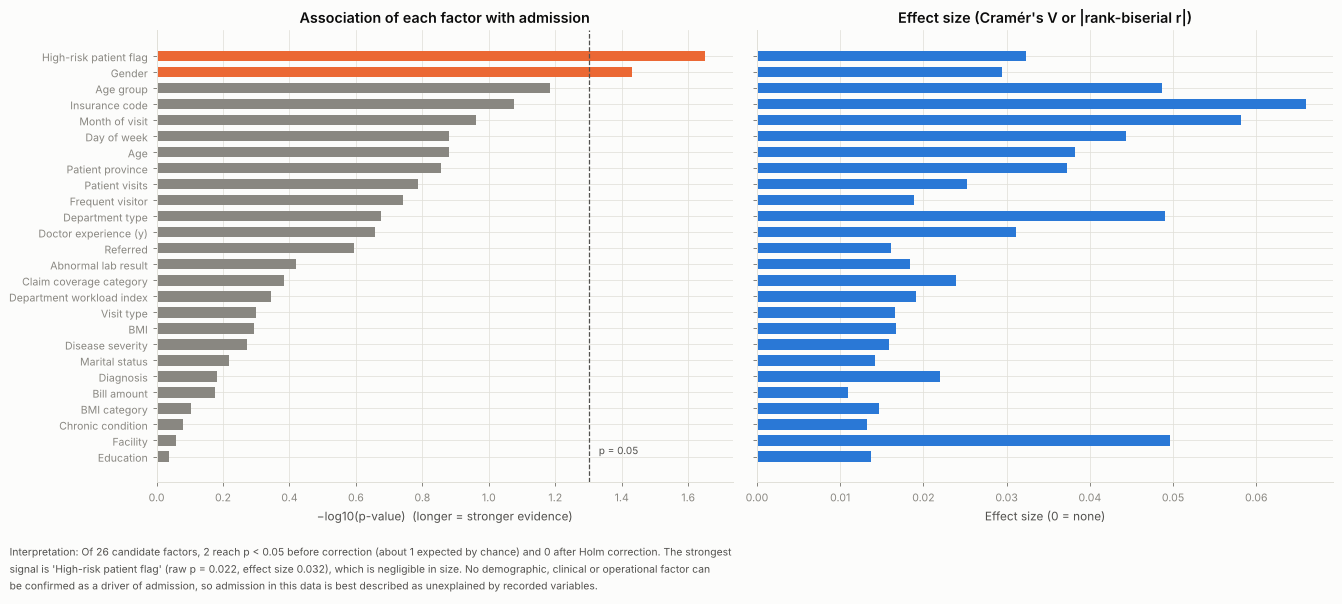

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
colors_ = [C[7] if s_ else (C[1] if r_ else MUTED) for s_, r_ in zip(FT.Signif_holm, FT.Signif_raw)]
ax[0].barh(FT.Factor[::-1], -np.log10(FT.p[::-1]), color=colors_[::-1], height=.65)
ax[0].axvline(-np.log10(.05), color=INK2, ls="--", lw=1); ax[0].text(-np.log10(.05) + .03, 0, "p = 0.05", fontsize=8, color=INK2, va="bottom")
ax[0].set(title="Association of each factor with admission", xlabel="−log10(p-value)  (longer = stronger evidence)")
ax[1].barh(FT.Factor[::-1], FT.Effect[::-1], color=C[0], height=.65); ax[1].set(title="Effect size (Cramér's V or |rank-biserial r|)", xlabel="Effect size (0 = none)"); ax[1].set_yticklabels([])
fig.tight_layout()
best = FT.iloc[0]
save_fig(fig, "f23_admission_drivers",
         f"Of {len(FT)} candidate factors, {int(FT.Signif_raw.sum())} reach p < 0.05 before correction (about {max(1, int(round(.05 * len(FT))))} expected by chance) and {int(FT.Signif_holm.sum())} after Holm correction. "
         f"The strongest signal is '{best.Factor}' (raw p = {best.p:.3f}, effect size {best.Effect:.3f}), which is negligible in size. "
         "No demographic, clinical or operational factor can be confirmed as a driver of admission, so admission in this data is best described as unexplained by recorded variables.")

### 4.4 Which patient groups are most at risk of chronic disease? (business question 2)
Prevalence of any chronic condition (asthma, hypertension or diabetes) by every patient attribute, compared with the overall rate
(74.6%) using Wilson 95% confidence intervals and a χ² test per attribute. A logistic regression then tests whether the attributes
jointly predict chronic disease.

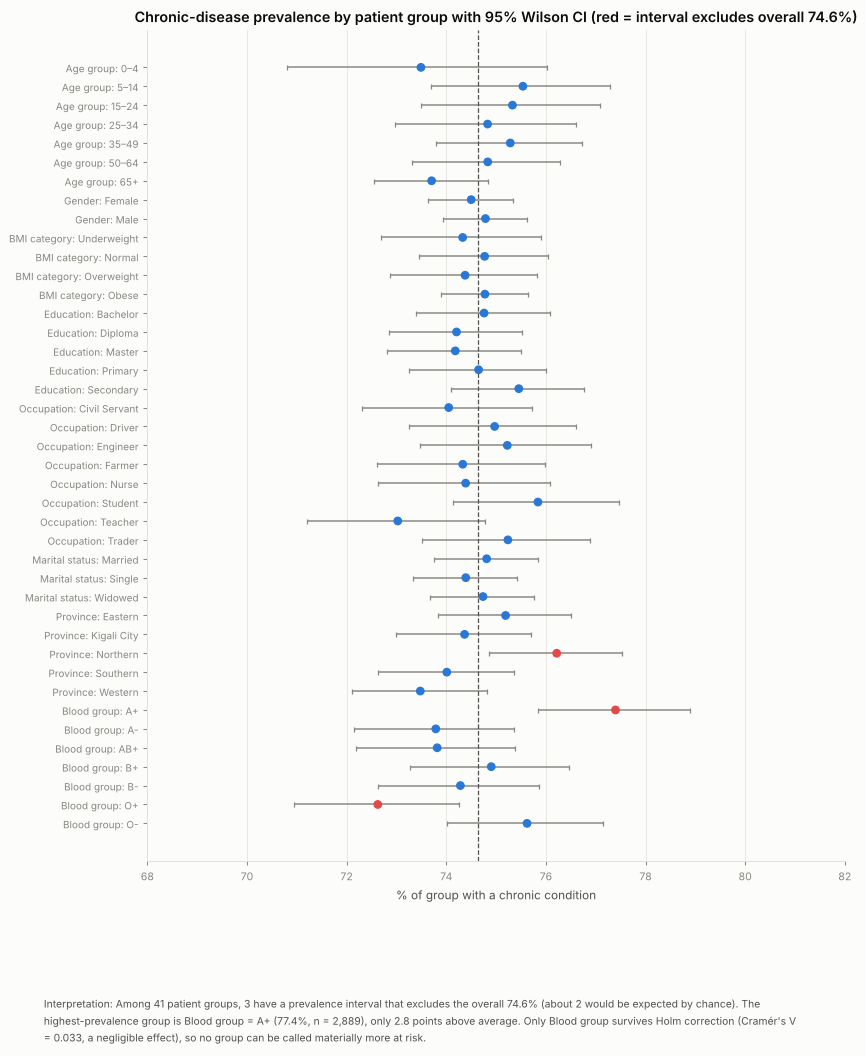

In [40]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d

base = PATIENTS.ChronicFlag.mean()
rows, attr_tests = [], []
for col, nm in [("AgeGroup", "Age group"), ("Gender", "Gender"), ("BMICategory", "BMI category"), ("Education", "Education"), ("Occupation", "Occupation"),
                ("MaritalStatus", "Marital status"), ("ProvinceName", "Province"), ("BloodGroup", "Blood group")]:
    ct_ = pd.crosstab(PATIENTS[col], PATIENTS.ChronicFlag); c2 = stats.chi2_contingency(ct_)
    attr_tests.append(dict(Attribute=nm, chi2=c2[0], p=c2[1], CramersV=np.sqrt(c2[0] / (len(PATIENTS) * (min(ct_.shape) - 1)))))
    for lvl, r_ in ct_.iterrows():
        n_, k_ = r_.sum(), r_.get(1, 0); lo_, hi_ = wilson(k_, n_)
        rows.append(dict(Attribute=nm, Group=str(lvl), n=int(n_), Prevalence=k_ / n_, Lo=lo_, Hi=hi_, Diff=k_ / n_ - base, Excludes=(lo_ > base) or (hi_ < base)))
PREV = pd.DataFrame(rows); ATT = pd.DataFrame(attr_tests); ATT["p_holm"] = holm(ATT.p.values)
R["chronic_attr_tests"] = ATT.round(4).to_dict("records"); R["chronic_groups_excluding_base"] = int(PREV.Excludes.sum()); R["chronic_groups_tested"] = len(PREV)
PREV_sorted = PREV.sort_values("Diff", ascending=False)
R["chronic_top_groups"] = PREV_sorted.head(5).round(4).to_dict("records")
fig, ax = plt.subplots(figsize=(10, 12))
pv_ = PREV.reset_index(drop=True); ypos = np.arange(len(pv_))[::-1]
ax.errorbar(100 * pv_.Prevalence, ypos, xerr=[100 * (pv_.Prevalence - pv_.Lo), 100 * (pv_.Hi - pv_.Prevalence)], fmt="none", ecolor=MUTED, elinewidth=1.2, capsize=2)
ax.scatter(100 * pv_.Prevalence, ypos, c=np.where(pv_.Excludes, C[7], C[0]), s=36, zorder=3)
ax.axvline(100 * base, color=INK2, ls="--", lw=1); ax.set_yticks(ypos); ax.set_yticklabels(pv_.Attribute + ": " + pv_.Group, fontsize=8)
ax.set(title="Chronic-disease prevalence by patient group with 95% Wilson CI (red = interval excludes overall 74.6%)", xlabel="% of group with a chronic condition", xlim=(68, 82)); ax.grid(axis="y", visible=False)
save_fig(fig, "f24_chronic_risk_groups",
         f"Among {len(PREV)} patient groups, {int(PREV.Excludes.sum())} have a prevalence interval that excludes the overall {pct(base)} (about {int(round(.05 * len(PREV)))} would be expected by chance). The highest-prevalence group is "
         f"{PREV_sorted.iloc[0].Attribute} = {PREV_sorted.iloc[0].Group} ({pct(PREV_sorted.iloc[0].Prevalence)}, n = {int(PREV_sorted.iloc[0].n):,}), only {100 * PREV_sorted.iloc[0].Diff:.1f} points above average. "
         + (f"Only {', '.join(ATT[ATT.p_holm < .05].Attribute)} survives Holm correction (Cramér's V = {ATT[ATT.p_holm < .05].CramersV.max():.3f}, a negligible effect), so no group can be called materially more at risk." if (ATT.p_holm < .05).any() else "No attribute test survives Holm correction, so no group can be called materially more at risk on the evidence available."))

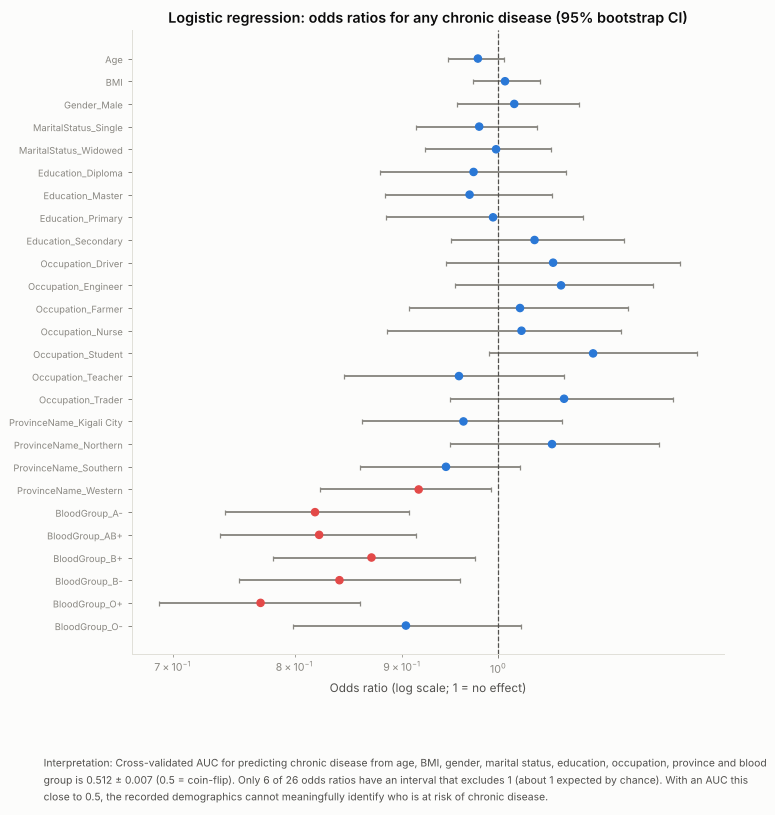

In [41]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

num_c = ["Age", "BMI"]; cat_c = ["Gender", "MaritalStatus", "Education", "Occupation", "ProvinceName", "BloodGroup"]
pre = ColumnTransformer([("n", StandardScaler(), num_c), ("c", OneHotEncoder(drop="first"), cat_c)])
lr_c = Pipeline([("p", pre), ("m", LogisticRegression(max_iter=1000))])
yC = PATIENTS.ChronicFlag.values
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
auc_chr = cross_val_score(lr_c, PATIENTS[num_c + cat_c], yC, cv=skf, scoring="roc_auc")
lr_c.fit(PATIENTS[num_c + cat_c], yC)
names = lr_c.named_steps["p"].get_feature_names_out(); coefs = lr_c.named_steps["m"].coef_[0]
# bootstrap odds-ratio intervals (200 resamples)
bs = []
Xc = lr_c.named_steps["p"].transform(PATIENTS[num_c + cat_c])
for b_ in range(150):
    ix = rng.integers(0, len(yC), len(yC)); bs.append(LogisticRegression(max_iter=500).fit(Xc[ix], yC[ix]).coef_[0])
bs = np.array(bs); OR = pd.DataFrame({"Feature": [n.split("__")[1] for n in names], "OR": np.exp(coefs), "Lo": np.exp(np.percentile(bs, 2.5, 0)), "Hi": np.exp(np.percentile(bs, 97.5, 0))})
OR["Excludes1"] = (OR.Lo > 1) | (OR.Hi < 1)
R["chronic_auc_cv"] = [float(auc_chr.mean()), float(auc_chr.std())]; R["chronic_or_excl"] = int(OR.Excludes1.sum()); R["chronic_or_n"] = len(OR)
fig, ax = plt.subplots(figsize=(8.5, 9))
yy = np.arange(len(OR))[::-1]
ax.errorbar(OR.OR, yy, xerr=[OR.OR - OR.Lo, OR.Hi - OR.OR], fmt="none", ecolor=MUTED, capsize=2); ax.scatter(OR.OR, yy, c=np.where(OR.Excludes1, C[7], C[0]), s=34, zorder=3)
ax.axvline(1, color=INK2, ls="--", lw=1); ax.set_yticks(yy); ax.set_yticklabels(OR.Feature, fontsize=7.5); ax.set_xscale("log"); ax.grid(axis="y", visible=False)
ax.set(title="Logistic regression: odds ratios for any chronic disease (95% bootstrap CI)", xlabel="Odds ratio (log scale; 1 = no effect)")
save_fig(fig, "f25_chronic_odds_ratios",
         f"Cross-validated AUC for predicting chronic disease from age, BMI, gender, marital status, education, occupation, province and blood group is {auc_chr.mean():.3f} ± {auc_chr.std():.3f} (0.5 = coin-flip). "
         f"Only {int(OR.Excludes1.sum())} of {len(OR)} odds ratios have an interval that excludes 1 (about {max(1, int(round(.05 * len(OR))))} expected by chance). With an AUC this close to 0.5, the recorded demographics cannot meaningfully identify who is at risk of chronic disease.")

### 4.5 Hypothesis tests
Significance level **α = 0.05** for every test. Where several tests address the same family, Holm-adjusted p-values are also given. Effect sizes are reported
because with large n tiny differences become "significant" and with small n large differences can be missed.

In [42]:
HT = []
def add_ht(i, q, h0, h1, test, n, stat, p, eff, effname, concl_extra=""):
    dec = "Reject H0" if p < .05 else "Fail to reject H0"
    HT.append(dict(ID=i, Question=q, H0=h0, H1=h1, Test=test, Alpha=.05, n=n, Statistic=float(stat), p_value=float(p), Effect=float(eff), Effect_measure=effname, Decision=dec, Conclusion=concl_extra))

# H1 billing: claim vs no claim (the closest available analogue of insured vs uninsured)
a_, b_ = FIN[FIN.HasClaim == 1].BillAmount, FIN[FIN.HasClaim == 0].BillAmount
tt = stats.ttest_ind(a_, b_, equal_var=False); mw = stats.mannwhitneyu(a_, b_); d = (a_.mean() - b_.mean()) / np.sqrt((a_.var() + b_.var()) / 2)
add_ht("H1", "Do average bills differ between bills with an insurance claim and bills without? (100% of patients are insured, so 'uninsured' cannot be tested)",
       "Mean bill (claim) = mean bill (no claim)", "Mean bills differ", "Welch two-sample t-test (Mann-Whitney U agrees: p = %.3f)" % mw.pvalue, len(FIN), tt.statistic, tt.pvalue, d, "Cohen's d",
       f"Mean bill {a_.mean():,.0f} RWF with claim vs {b_.mean():,.0f} RWF without ({a_.mean() - b_.mean():+,.0f}).")
# H1b payment method
ins_b = FIN[FIN.PayMethod == "Insurance"].BillAmount; oth_b = FIN[FIN.PayMethod != "Insurance"].BillAmount; t1b = stats.ttest_ind(ins_b, oth_b, equal_var=False)
add_ht("H1b", "Do bills paid via the 'Insurance' method differ from other payment methods?", "Mean bill equal", "Mean bill differs", "Welch t-test", len(FIN), t1b.statistic, t1b.pvalue,
       (ins_b.mean() - oth_b.mean()) / np.sqrt((ins_b.var() + oth_b.var()) / 2), "Cohen's d", f"{ins_b.mean():,.0f} vs {oth_b.mean():,.0f} RWF.")
# H2 satisfaction across facilities
an2 = stats.f_oneway(*[g_.Rating.values for _, g_ in Ef.groupby("FacilityID")])
add_ht("H2", "Does patient satisfaction differ across the 20 facilities?", "Median rating identical in all facilities", "At least one facility differs", "Kruskal-Wallis H (one-way ANOVA agrees: p = %.3f)" % an2.pvalue,
       len(Ef), kw_fs.statistic, kw_fs.pvalue, eps2(kw_fs.statistic, len(Ef)), "ε² (rank)", f"Facility means {fs['mean'].min():.2f}–{fs['mean'].max():.2f}.")
add_ht("H2b", "Does satisfaction differ across the 10 department types?", "Median rating identical", "At least one differs", "Kruskal-Wallis H", len(Ef), kw_ds.statistic, kw_ds.pvalue, eps2(kw_ds.statistic, len(Ef)), "ε² (rank)", "")
# H3 admission by age group
ct3 = pd.crosstab(E.AgeGroup, E.Admitted); c3 = stats.chi2_contingency(ct3)
add_ht("H3", "Do admission rates differ between age groups?", "Admission rate equal across the 7 age groups", "At least one age group differs", "χ² test of independence (df = %d)" % c3[2], len(E), c3[0], c3[1],
       np.sqrt(c3[0] / (len(E) * (min(ct3.shape) - 1))), "Cramér's V", f"Rates {100 * ag.rate.min():.1f}%–{100 * ag.rate.max():.1f}%.")
# H4 satisfaction vs severity (universe)
fsv = FIN.dropna(subset=["Rating", "Severity"]); kw4 = stats.kruskal(*[g_.Rating.values for _, g_ in fsv.groupby("Severity")])
add_ht("H4", "Does satisfaction depend on disease severity?", "Rating distribution identical across Mild/Moderate/Severe", "Differs", "Kruskal-Wallis H", len(fsv), kw4.statistic, kw4.pvalue, eps2(kw4.statistic, len(fsv)), "ε² (rank)", "")
# H5 LOS by diagnosis
add_ht("H5", "Does length of stay differ by diagnosis?", "Median LOS equal across diagnoses", "At least one differs", "Kruskal-Wallis H", len(Ea), kw3.statistic, kw3.pvalue, eps2(kw3.statistic, len(Ea)), "ε² (rank)", f"Mean LOS {dl['mean'].min():.1f}–{dl['mean'].max():.1f} d.")
# H6 satisfaction vs billing status / payment completeness
fst = FIN.dropna(subset=["Rating"]); kw6 = stats.kruskal(*[g_.Rating.values for _, g_ in fst.groupby("BillStatus")]); sp6b = stats.spearmanr(fst.PaidRatio, fst.Rating)
add_ht("H6", "Is satisfaction related to billing outcome (recorded bill status)?", "Rating equal across Paid / Partially Paid / Pending", "Differs", "Kruskal-Wallis H (Spearman ρ rating vs paid ratio = %.3f, p = %.3f)" % (sp6b[0], sp6b[1]),
       len(fst), kw6.statistic, kw6.pvalue, eps2(kw6.statistic, len(fst)), "ε² (rank)", "")
# H7 emergency vs other admission
ct7 = pd.crosstab(E.VisitType == "Emergency", E.Admitted); c7 = stats.chi2_contingency(ct7)
add_ht("H7", "Are emergency visits admitted more often than other visits?", "Admission proportion equal", "Proportions differ", "χ² test (2×2, Yates)", len(E), c7[0], c7[1], np.sqrt(c7[0] / len(E)), "φ",
       f"Emergency {100 * E[E.VisitType == 'Emergency'].Admitted.mean():.1f}% vs other {100 * E[E.VisitType != 'Emergency'].Admitted.mean():.1f}%.")
# H8 severe vs mild admission
ct8 = pd.crosstab(E.Severity, E.Admitted); c8 = stats.chi2_contingency(ct8)
add_ht("H8", "Are severe cases admitted more often than mild cases?", "Admission rate equal across severity levels", "Differs", "χ² test (df = 2)", len(E), c8[0], c8[1], np.sqrt(c8[0] / (len(E) * 1)), "Cramér's V",
       "Rates: " + ", ".join(f"{k} {100 * v:.1f}%" for k, v in E.groupby("Severity").Admitted.mean().items()))
# H9 chronic disease prevalence by gender & by age group
ctg = pd.crosstab(PATIENTS.Gender, PATIENTS.ChronicFlag); cg = stats.chi2_contingency(ctg)
add_ht("H9", "Does chronic-disease prevalence differ by gender?", "Prevalence equal for men and women", "Differs", "χ² test (2×2, Yates)", len(PATIENTS), cg[0], cg[1], np.sqrt(cg[0] / len(PATIENTS)), "φ", "")
cta = pd.crosstab(PATIENTS.AgeGroup, PATIENTS.ChronicFlag); ca = stats.chi2_contingency(cta)
add_ht("H10", "Does chronic-disease prevalence differ by age group?", "Prevalence equal across age groups", "Differs", "χ² test (df = %d)" % ca[2], len(PATIENTS), ca[0], ca[1], np.sqrt(ca[0] / (len(PATIENTS) * 1)), "Cramér's V", "")
# H11 rating-comment independence ; H12 claim approval by provider
add_ht("H11", "Is the written comment related to the numeric rating?", "Comment independent of rating", "Associated", "χ² test of independence", len(fb), chi_rc[0], chi_rc[1], np.sqrt(chi_rc[0] / (len(fb) * 3)), "Cramér's V", "A valid feedback instrument should show strong association.")
add_ht("H12", "Does the claim approval rate differ between insurance providers?", "Approval rate equal", "Differs", "χ² test (df = 3)", len(clm), chi_prov_appr[0], chi_prov_appr[1], np.sqrt(chi_prov_appr[0] / len(clm)), "Cramér's V", "")
# H13 monthly revenue seasonality (Q-test vs flat) skipped -> H13 payment ratio across methods
kw13 = stats.kruskal(*[g_.PaidRatio.values for _, g_ in FIN.groupby("PayMethod")])
add_ht("H13", "Does the share of the bill actually paid differ by payment method?", "Payment ratio equal across methods", "Differs", "Kruskal-Wallis H", len(FIN), kw13.statistic, kw13.pvalue, eps2(kw13.statistic, len(FIN)), "ε² (rank)", "")
HTT = pd.DataFrame(HT)
HTT["p_holm_all"] = holm(HTT.p_value.values)
# plain-language conclusion
def concl(r):
    if r.Decision == "Reject H0":
        return f"Statistically significant (p = {r.p_value:.4f}); effect size {r.Effect:.3f} ({r.Effect_measure})."
    return f"No significant difference (p = {r.p_value:.3f}); effect size {r.Effect:.3f} is negligible."
HTT["Interpretation"] = HTT.apply(concl, axis=1) + " " + HTT.Conclusion
R["hypothesis_tests"] = HTT.round(5).to_dict("records")
R["ht_rejected"] = int((HTT.Decision == "Reject H0").sum()); R["ht_total"] = len(HTT)
pd.options.display.float_format = "{:,.4f}".format
HTT[["ID", "Question", "Test", "n", "Statistic", "p_value", "p_holm_all", "Effect", "Effect_measure", "Decision"]]

,ID,Question,Test,n,Statistic,p_value,p_holm_all,Effect,Effect_measure,Decision
0,H1,"Do average bills differ between bills with an insurance claim and bills without? (100% of patients are insured, so 'uninsured' cannot be tested)",Welch two-sample t-test (Mann-Whitney U agrees: p = 0.155),60000,-1.4242,0.1544,1.0000,-0.0127,Cohen's d,Fail to reject H0
1,H1b,Do bills paid via the 'Insurance' method differ from other payment methods?,Welch t-test,60000,0.4389,0.6608,1.0000,0.0041,Cohen's d,Fail to reject H0
2,H2,Does patient satisfaction differ across the 20 facilities?,Kruskal-Wallis H (one-way ANOVA agrees: p = 0.785),1756,13.7999,0.7952,1.0000,0.0079,ε² (rank),Fail to reject H0
3,H2b,Does satisfaction differ across the 10 department types?,Kruskal-Wallis H,1756,4.4673,0.8781,1.0000,0.0025,ε² (rank),Fail to reject H0
4,H3,Do admission rates differ between age groups?,χ² test of independence (df = 6),5000,11.8539,0.0653,0.9796,0.0487,Cramér's V,Fail to reject H0
5,H4,Does satisfaction depend on disease severity?,Kruskal-Wallis H,21064,0.3600,0.8353,1.0000,0.0000,ε² (rank),Fail to reject H0
6,H5,Does length of stay differ by diagnosis?,Kruskal-Wallis H,586,3.1173,0.5384,1.0000,0.0053,ε² (rank),Fail to reject H0
7,H6,Is satisfaction related to billing outcome (recorded bill status)?,"Kruskal-Wallis H (Spearman ρ rating vs paid ratio = -0.001, p = 0.893)",21064,0.6691,0.7156,1.0000,0.0000,ε² (rank),Fail to reject H0
8,H7,Are emergency visits admitted more often than other visits?,"χ² test (2×2, Yates)",5000,0.6894,0.4064,1.0000,0.0117,φ,Fail to reject H0
9,H8,Are severe cases admitted more often than mild cases?,χ² test (df = 2),5000,1.2596,0.5327,1.0000,0.0159,Cramér's V,Fail to reject H0


0 of 15 hypothesis tests reject H0 at α = 0.05; after Holm correction: 0


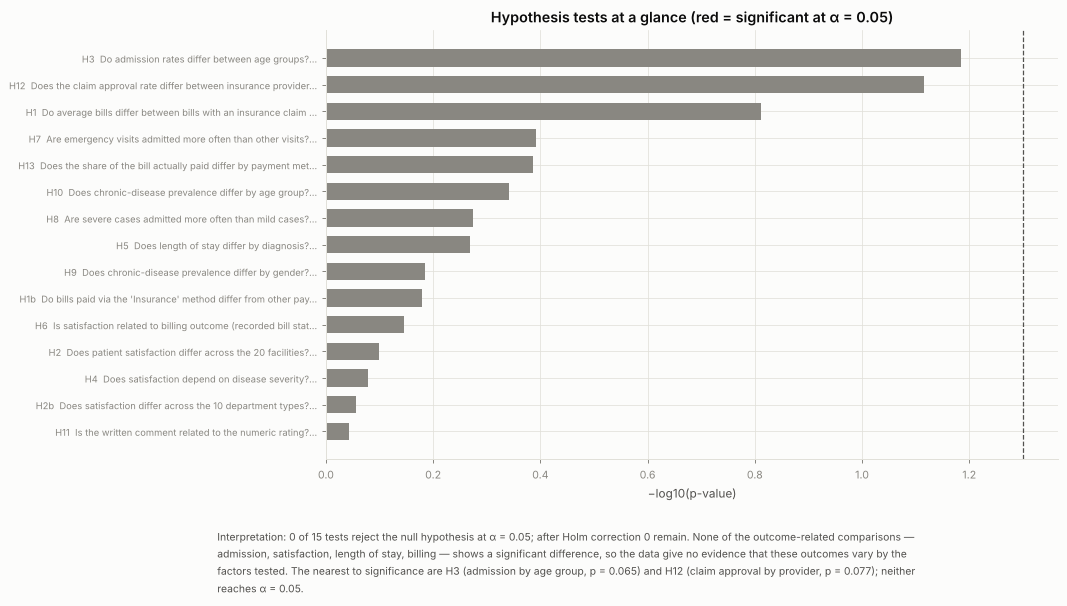

In [43]:
# Which tests rejected H0?  (chance expectation: ~5% of independent true-null tests)
print(f"{R['ht_rejected']} of {R['ht_total']} hypothesis tests reject H0 at α = 0.05; after Holm correction: {(HTT.p_holm_all < .05).sum()}")
for _, r_ in HTT[HTT.Decision == "Reject H0"].iterrows(): print(f"  {r_.ID}: {r_.Question}  (p = {r_.p_value:.4g}, Holm p = {r_.p_holm_all:.4g}, {r_.Effect_measure} = {r_.Effect:.3f})")
fig, ax = plt.subplots(figsize=(10.5, 6.2))
ht_ = HTT.sort_values("p_value", ascending=False)
ax.barh(ht_.ID + "  " + ht_.Question.str.slice(0, 62) + "…", -np.log10(ht_.p_value.clip(lower=1e-12)), color=np.where(ht_.p_value < .05, C[7], MUTED), height=.65)
ax.axvline(-np.log10(.05), color=INK2, ls="--", lw=1); ax.set(title="Hypothesis tests at a glance (red = significant at α = 0.05)", xlabel="−log10(p-value)"); ax.tick_params(axis="y", labelsize=7.5)
rej = HTT[HTT.Decision == "Reject H0"]
save_fig(fig, "f26_hypothesis_summary",
         (f"{R['ht_rejected']} of {R['ht_total']} tests reject the null hypothesis at α = 0.05" + (": " + "; ".join(f"{r_.ID} (effect {r_.Effect:.2f})" for _, r_ in rej.iterrows()) if len(rej) else "") + f"; after Holm correction {(HTT.p_holm_all < .05).sum()} remain. "
          + ("None of the outcome-related comparisons — admission, satisfaction, length of stay, billing — shows a significant difference, so the data give no evidence that these outcomes vary by the factors tested. " if len(rej) == 0 else "")
          + f"The nearest to significance are H3 (admission by age group, p = {HTT.loc[HTT.ID == 'H3', 'p_value'].iloc[0]:.3f}) and H12 (claim approval by provider, p = {HTT.loc[HTT.ID == 'H12', 'p_value'].iloc[0]:.3f}); neither reaches α = 0.05."))

## 5. Predictive analytics & forecasting
Method notes that apply to every model below:
* Models are judged on **out-of-sample** performance only (rolling-origin back-tests for time series; repeated stratified k-fold
  cross-validation for classifiers/regressors) and always against a **naïve baseline** — a model that cannot beat "predict the average" has no value.
* A **label-permutation test** checks whether any apparent skill exceeds chance.
* Forecast horizon: the data cover Jan–Dec 2026, so "the next 12 months" is **Jan–Dec 2027**.
* statsmodels is unavailable in this environment, so the exponential-smoothing models are implemented directly in NumPy (simple, Holt damped-trend)
  alongside mean, naïve and linear-trend benchmarks. With only 12 monthly observations, seasonal models (which need ≥ 24) cannot be estimated.

### 5.1 Time-series tools

In [44]:
from itertools import product

def f_mean(y, h):  return np.repeat(np.mean(y), h)
def f_naive(y, h): return np.repeat(y[-1], h)
def f_trend(y, h):
    t = np.arange(len(y)); b = np.polyfit(t, y, 1); return np.polyval(b, np.arange(len(y), len(y) + h))
def _ses(y, a):
    l = y[0]; sse = 0.0
    for v in y[1:]:
        sse += (v - l) ** 2; l = a * v + (1 - a) * l
    return l, sse
def f_ses(y, h):
    best = min(((_ses(y, a)[1], a) for a in np.linspace(.05, 1, 20)))[1]; return np.repeat(_ses(y, best)[0], h)
def _holt(y, a, b, phi):
    l, tr, sse = y[0], y[1] - y[0], 0.0
    for v in y[1:]:
        f = l + phi * tr; sse += (v - f) ** 2; ln = a * v + (1 - a) * f; tr = b * (ln - l) + (1 - b) * phi * tr; l = ln
    return l, tr, sse
def f_holt(y, h):
    best = min(((_holt(y, a, b, p)[2], a, b, p) for a, b, p in product(np.linspace(.1, 1, 10), np.linspace(.05, .5, 6), [.8, .9, .98])))
    l, tr, _ = _holt(y, *best[1:]); return np.array([l + sum(best[3] ** k for k in range(1, i + 1)) * tr for i in range(1, h + 1)])

MODELS = {"Mean": f_mean, "Naïve (last value)": f_naive, "Linear trend": f_trend, "Simple exp. smoothing": f_ses, "Holt damped trend": f_holt}

def backtest(y, min_train=6, hmax=3):
    y = np.asarray(y, float); rows = []
    for name, fn in MODELS.items():
        errs, perr = [], []
        for t in range(min_train, len(y)):
            h = min(hmax, len(y) - t); f = fn(y[:t], h); a = y[t:t + h]
            errs += list(a - f); perr += list(np.abs(a - f) / np.abs(a))
        errs = np.array(errs); rows.append(dict(Model=name, MAE=np.mean(np.abs(errs)), RMSE=np.sqrt(np.mean(errs ** 2)), MAPE=100 * np.mean(perr), Folds=len(errs)))
    return pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)

def forecast_series(y, dates, h=12):
    bt = backtest(y); best = bt.iloc[0].Model; base_mae = bt.set_index("Model").loc["Mean", "MAE"]
    fc = MODELS[best](np.asarray(y, float), h); sig = bt.iloc[0].RMSE
    fd = pd.date_range(dates.iloc[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    return bt, best, pd.DataFrame({"Month": fd, "Forecast": fc, "Lower95": fc - 1.96 * sig, "Upper95": fc + 1.96 * sig}), sig

def trend_diag(y):
    y = np.asarray(y, float); t = np.arange(len(y)); sp = stats.spearmanr(t, y); y0 = y - y.mean()
    ac1 = (y0[1:] * y0[:-1]).sum() / (y0 ** 2).sum(); slope = np.polyfit(t, y, 1)[0]
    return dict(trend_rho=sp[0], trend_p=sp[1], lag1_acf=ac1, acf_bound=1.96 / np.sqrt(len(y)), slope_pct_per_month=100 * slope / y.mean())

### 5.2 Task 1 — Patient-volume forecast (next 12 months)
Series used: the **Revenue_Summary monthly appointment counts** (system-wide, ~60,800 appointments), cross-checked with the monthly counts in the
5,000-appointment record. The rolling-origin back-test compares five models; the best by MAE produces the forecast, and 95% bands use the
back-test RMSE (so the width reflects real out-of-sample error rather than a theoretical formula).

In [45]:
y_app = rs.Appointments.values.astype(float)
bt_app, best_app, fc_app, sig_app = forecast_series(y_app, rs.Month)
diag_app = trend_diag(y_app)
y_cohort = E.groupby("Month").size().values.astype(float); bt_coh, best_coh, fc_coh, _ = forecast_series(y_cohort, pd.Series(sorted(E.Month.unique())))
diag_coh = trend_diag(y_cohort)
mean_mape_app = bt_app.set_index("Model").loc["Mean", "MAPE"]
R["fc_app"] = dict(best=best_app, backtest=bt_app.round(2).to_dict("records"), mape_best=float(bt_app.iloc[0].MAPE), mape_mean=float(mean_mape_app), diag=diag_app,
                   forecast_total_2027=float(fc_app.Forecast.sum()), forecast_monthly=fc_app.Forecast.round(0).tolist(), lower=fc_app.Lower95.round(0).tolist(), upper=fc_app.Upper95.round(0).tolist(), history_total_2026=float(y_app.sum()))
R["fc_app_cohort"] = dict(best=best_coh, mape_best=float(bt_coh.iloc[0].MAPE), diag=diag_coh)
pd.options.display.float_format = "{:,.2f}".format
print("Back-test (rolling origin, 1–3 month horizon) — system appointments:"); print(bt_app.to_string(index=False))
print("\nTrend/autocorrelation diagnostics:", {k: round(v, 3) for k, v in diag_app.items()})
fc_app.round(0)

Back-test (rolling origin, 1–3 month horizon) — system appointments:
                Model      MAE     RMSE  MAPE  Folds
Simple exp. smoothing   736.67   978.51 14.04     15
                 Mean   758.79   903.47 15.28     15
    Holt damped trend 1,111.61 1,427.42 21.17     15
         Linear trend 1,166.94 1,490.63 21.65     15
   Naïve (last value) 1,227.87 1,463.70 24.24     15

Trend/autocorrelation diagnostics: {'trend_rho': np.float64(-0.14), 'trend_p': np.float64(0.665), 'lag1_acf': np.float64(-0.408), 'acf_bound': np.float64(0.566), 'slope_pct_per_month': np.float64(-1.321)}


,Month,Forecast,Lower95,Upper95
0,2027-01-01,"4,975.00","3,057.00","6,893.00"
1,2027-02-01,"4,975.00","3,057.00","6,893.00"
2,2027-03-01,"4,975.00","3,057.00","6,893.00"
3,2027-04-01,"4,975.00","3,057.00","6,893.00"
4,2027-05-01,"4,975.00","3,057.00","6,893.00"
5,2027-06-01,"4,975.00","3,057.00","6,893.00"
6,2027-07-01,"4,975.00","3,057.00","6,893.00"
7,2027-08-01,"4,975.00","3,057.00","6,893.00"
8,2027-09-01,"4,975.00","3,057.00","6,893.00"
9,2027-10-01,"4,975.00","3,057.00","6,893.00"


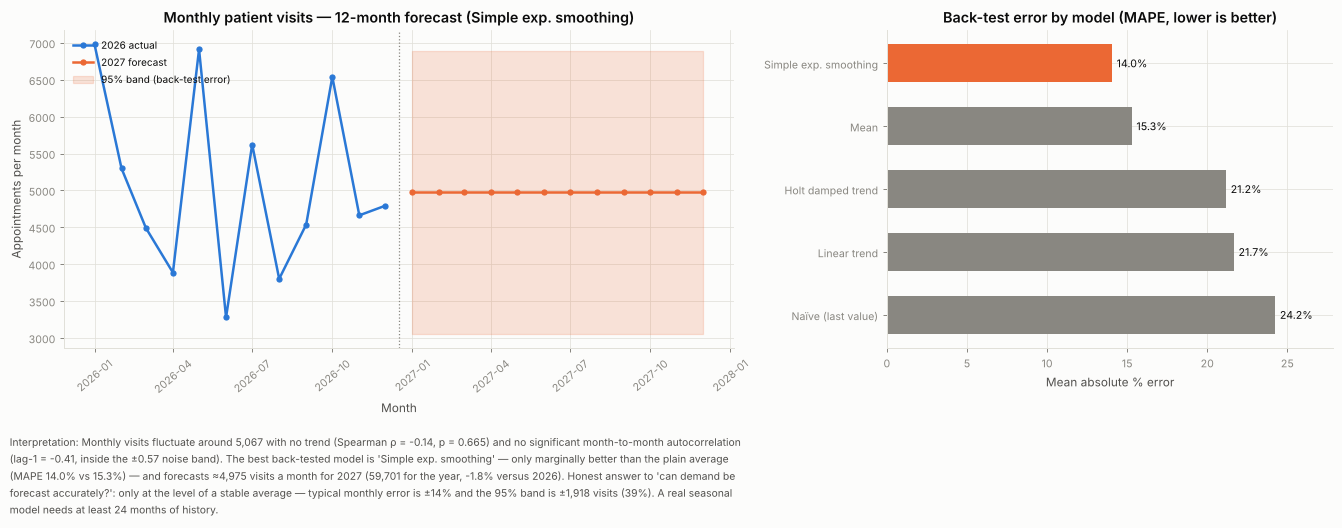

In [46]:
def fc_plot(ax, dates, y, fc, title, ylabel, scale=1, color=C[0]):
    ax.plot(dates, y / scale, color=color, lw=2, marker="o", ms=4, label="2026 actual")
    ax.plot(fc.Month, fc.Forecast / scale, color=C[1], lw=2, marker="o", ms=4, label="2027 forecast")
    ax.fill_between(fc.Month, fc.Lower95 / scale, fc.Upper95 / scale, color=C[1], alpha=.18, label="95% band (back-test error)")
    ax.axvline(pd.Timestamp("2026-12-16"), color=MUTED, ls=":", lw=1); ax.set(title=title, xlabel="Month", ylabel=ylabel); ax.legend(loc="upper left", fontsize=8)
    for t_ in ax.get_xticklabels(): t_.set_rotation(40)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
fc_plot(ax[0], rs.Month, y_app, fc_app, f"Monthly patient visits — 12-month forecast ({best_app})", "Appointments per month")
b_ = bt_app.sort_values("MAPE"); ax[1].barh(b_.Model[::-1], b_.MAPE[::-1], color=[C[1] if m == best_app else MUTED for m in b_.Model[::-1]], height=.6)
for i, v in enumerate(b_.MAPE[::-1]): ax[1].text(v + .3, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax[1].set(title="Back-test error by model (MAPE, lower is better)", xlabel="Mean absolute % error", xlim=(0, b_.MAPE.max() * 1.15))
fig.tight_layout()
w95 = (fc_app.Upper95 - fc_app.Lower95).mean() / 2
save_fig(fig, "f27_forecast_visits",
         f"Monthly visits fluctuate around {y_app.mean():,.0f} with no trend (Spearman ρ = {diag_app['trend_rho']:.2f}, {fmt_p(diag_app['trend_p'])}) and no significant month-to-month autocorrelation (lag-1 = {diag_app['lag1_acf']:.2f}, inside the ±{diag_app['acf_bound']:.2f} noise band). "
         f"The best back-tested model is '{best_app}' — only marginally better than the plain average (MAPE {bt_app.iloc[0].MAPE:.1f}% vs {mean_mape_app:.1f}%) — and forecasts ≈{fc_app.Forecast.mean():,.0f} visits a month for 2027 ({fc_app.Forecast.sum():,.0f} for the year, {pct(fc_app.Forecast.sum() / y_app.sum() - 1)} versus 2026). "
         f"Honest answer to 'can demand be forecast accurately?': only at the level of a stable average — typical monthly error is ±{bt_app.iloc[0].MAPE:.0f}% and the 95% band is ±{w95:,.0f} visits ({100 * w95 / fc_app.Forecast.mean():.0f}%). A real seasonal model needs at least 24 months of history.")

### 5.3 Task 2 — Revenue forecast (next 12 months)

                Model           MAE          RMSE  MAPE  Folds
Simple exp. smoothing 26,183,534.02 31,781,844.58 25.56     15
                 Mean 26,980,201.66 31,897,881.54 27.00     15
    Holt damped trend 27,143,406.38 32,295,130.17 27.16     15
         Linear trend 31,476,605.19 36,232,057.49 33.37     15
   Naïve (last value) 38,636,862.67 46,648,548.18 39.38     15

Diagnostics: {'trend_rho': np.float64(-0.175), 'trend_p': np.float64(0.587), 'lag1_acf': np.float64(-0.418), 'acf_bound': np.float64(0.566), 'slope_pct_per_month': np.float64(0.652)}


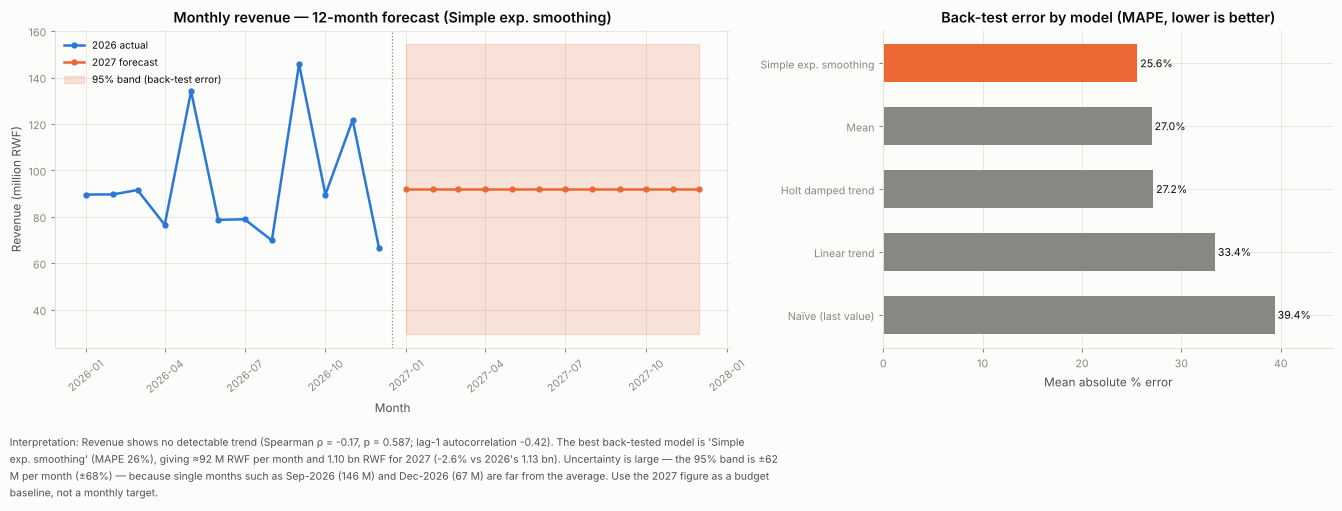

In [47]:
y_rev = rs.Revenue.values.astype(float)
bt_rev, best_rev, fc_rev, sig_rev = forecast_series(y_rev, rs.Month)
diag_rev = trend_diag(y_rev)
R["fc_rev"] = dict(best=best_rev, backtest=bt_rev.round(2).to_dict("records"), mape_best=float(bt_rev.iloc[0].MAPE), mape_mean=float(bt_rev.set_index("Model").loc["Mean", "MAPE"]), diag=diag_rev,
                   forecast_total_2027=float(fc_rev.Forecast.sum()), history_total_2026=float(y_rev.sum()), forecast_monthly=fc_rev.Forecast.round(0).tolist(), lower=fc_rev.Lower95.round(0).tolist(), upper=fc_rev.Upper95.round(0).tolist())
# revenue = visits × revenue-per-visit: decompose the uncertainty
print(bt_rev.to_string(index=False)); print("\nDiagnostics:", {k: round(v, 3) for k, v in diag_rev.items()})
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
fc_plot(ax[0], rs.Month, y_rev, fc_rev, f"Monthly revenue — 12-month forecast ({best_rev})", "Revenue (million RWF)", scale=1e6, color=C[0])
b_ = bt_rev.sort_values("MAPE"); ax[1].barh(b_.Model[::-1], b_.MAPE[::-1], color=[C[1] if m == best_rev else MUTED for m in b_.Model[::-1]], height=.6)
for i, v in enumerate(b_.MAPE[::-1]): ax[1].text(v + .3, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax[1].set(title="Back-test error by model (MAPE, lower is better)", xlabel="Mean absolute % error", xlim=(0, b_.MAPE.max() * 1.15))
fig.tight_layout()
w95r = (fc_rev.Upper95 - fc_rev.Lower95).mean() / 2
save_fig(fig, "f28_forecast_revenue",
         f"Revenue shows no detectable trend (Spearman ρ = {diag_rev['trend_rho']:.2f}, {fmt_p(diag_rev['trend_p'])}; lag-1 autocorrelation {diag_rev['lag1_acf']:.2f}). The best back-tested model is '{best_rev}' (MAPE {bt_rev.iloc[0].MAPE:.0f}%), giving "
         f"≈{fc_rev.Forecast.mean() / 1e6:,.0f} M RWF per month and {fc_rev.Forecast.sum() / 1e9:.2f} bn RWF for 2027 ({pct(fc_rev.Forecast.sum() / y_rev.sum() - 1)} vs 2026's {y_rev.sum() / 1e9:.2f} bn). "
         f"Uncertainty is large — the 95% band is ±{w95r / 1e6:,.0f} M per month (±{100 * w95r / fc_rev.Forecast.mean():.0f}%) — because single months such as Sep-2026 ({rs.Revenue.max() / 1e6:.0f} M) and Dec-2026 ({rs.Revenue.min() / 1e6:.0f} M) are far from the average. Use the 2027 figure as a budget baseline, not a monthly target.")

### 5.4 Task 5 — Department workload forecast
Department demand in the appointment record is too sparse to forecast per department-ID (≈2 appointments per department per month), so
demand is forecast at **department-type** level: the system-wide visit forecast (5.2) is split by each type's observed share of appointments, with
share uncertainty (Dirichlet) and forecast error (normal, back-test RMSE) propagated by Monte-Carlo simulation (5,000 runs). Capacity is the number
of clinicians (doctors + nurses) assigned to the department type. A department-type is **overload-prone** when simulated monthly appointments per clinician exceed 115 % of the all-department average.

In [48]:
cnt = E.groupby("DepartmentName").size(); share = cnt / cnt.sum()
clin = STAFF[STAFF.Clinician == 1].groupby("Department").size().reindex(cnt.index)
sim = 5000; rng2 = np.random.default_rng(SEED)
tot_draw = rng2.normal(fc_app.Forecast.values[None, :], sig_app, size=(sim, 12)).clip(min=0)          # sim × 12 system visits
sh_draw = rng2.dirichlet(cnt.values + 1, size=sim)                                                      # sim × 10 shares
dem = tot_draw[:, :, None] * sh_draw[:, None, :]                                                         # sim × month × dept
load = dem / clin.values[None, None, :]                                                                  # appointments per clinician per month
thr = 1.15 * (fc_app.Forecast.mean() / clin.sum())
p_over = (load > thr).mean(axis=(0, 1))
DF = pd.DataFrame({"Share_of_visits": share, "Clinicians": clin, "Fcst_visits_per_month": share * fc_app.Forecast.mean(), "Fcst_per_clinician": share * fc_app.Forecast.mean() / clin,
                   "P_overload": p_over, "Hist_WorkloadIndex": DEPTT.WorkloadIndex}).sort_values("P_overload", ascending=False)
DF["Fcst_WorkloadIndex"] = 100 * DF.Fcst_per_clinician / (fc_app.Forecast.mean() / clin.sum())
chi_sh = stats.chisquare(cnt.values)
R["dept_forecast"] = DF.round(4).reset_index().rename(columns={"index": "Department"}).to_dict("records"); R["dept_share_p"] = float(chi_sh.pvalue)
pd.options.display.float_format = "{:,.3f}".format
DF

,Share_of_visits,Clinicians,Fcst_visits_per_month,Fcst_per_clinician,P_overload,Hist_WorkloadIndex,Fcst_WorkloadIndex
DepartmentName,,,,,,,
Cardiology,0.109,105,541.285,5.155,0.384,108.800,108.800
Radiology,0.105,105,522.380,4.975,0.314,105.000,105.000
Obstetrics & Gynecology,0.102,105,508.450,4.842,0.263,102.200,102.200
Laboratory,0.100,105,496.510,4.729,0.221,99.800,99.800
Emergency,0.099,105,492.530,4.691,0.211,99.000,99.000
Pediatrics,0.098,105,488.550,4.653,0.197,98.200,98.200
Pharmacy,0.098,105,487.555,4.643,0.194,98.000,98.000
Internal Medicine,0.098,105,487.555,4.643,0.191,98.000,98.000
Surgery,0.098,105,485.565,4.624,0.188,97.600,97.600


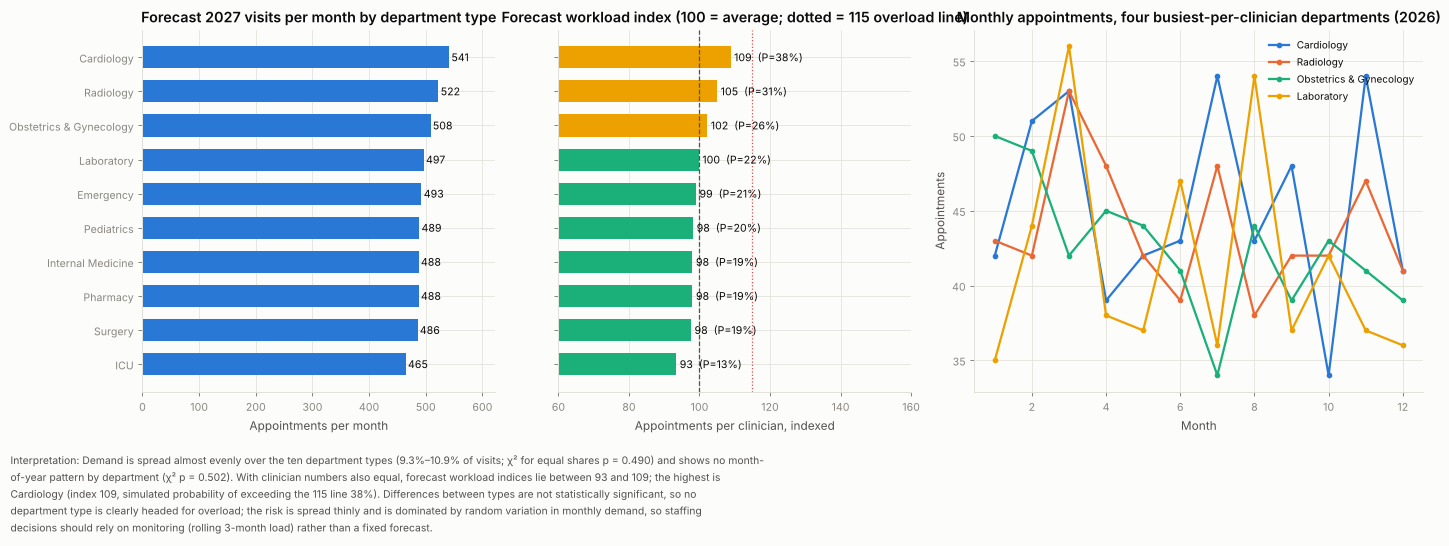

In [49]:
# seasonal pattern check by department (is there a month effect at all?)
dm = pd.crosstab(E.DepartmentName, E.MonthNum); chi_dm = stats.chi2_contingency(dm)
fig, ax = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.1, 1.1, 1.4]})
d1 = DF.sort_values("Fcst_visits_per_month")
ax[0].barh(d1.index, d1.Fcst_visits_per_month, color=C[0], height=.65)
for i, v in enumerate(d1.Fcst_visits_per_month): ax[0].text(v + 4, i, f"{v:,.0f}", va="center", fontsize=8.5)
ax[0].set(title="Forecast 2027 visits per month by department type", xlabel="Appointments per month", xlim=(0, d1.Fcst_visits_per_month.max() * 1.15))
d2 = DF.sort_values("Fcst_WorkloadIndex")
ax[1].barh(d2.index, d2.Fcst_WorkloadIndex, color=np.where(d2.P_overload > .5, C[7], np.where(d2.P_overload > .25, C[3], C[2])), height=.65); ax[1].axvline(100, color=INK2, ls="--", lw=1); ax[1].axvline(115, color=C[7], ls=":", lw=1)
for i, (v, p_) in enumerate(zip(d2.Fcst_WorkloadIndex, d2.P_overload)): ax[1].text(v + 1, i, f"{v:.0f}  (P={p_:.0%})", va="center", fontsize=8.5)
ax[1].set(title="Forecast workload index (100 = average; dotted = 115 overload line)", xlabel="Appointments per clinician, indexed", xlim=(60, 160)); ax[1].set_yticklabels([])
for j, dname in enumerate(DF.index[:4]):
    ax[2].plot(range(1, 13), dm.loc[dname].values, marker="o", ms=3.5, lw=1.8, color=C[j], label=dname)
ax[2].set(title="Monthly appointments, four busiest-per-clinician departments (2026)", xlabel="Month", ylabel="Appointments"); ax[2].legend(fontsize=8)
fig.tight_layout()
top_dep = DF.index[0]
save_fig(fig, "f29_department_workload_forecast",
         f"Demand is spread almost evenly over the ten department types ({100 * share.min():.1f}%–{100 * share.max():.1f}% of visits; χ² for equal shares {fmt_p(chi_sh.pvalue)}) and shows no month-of-year pattern by department (χ² {fmt_p(chi_dm[1])}). "
         f"With clinician numbers also equal, forecast workload indices lie between {DF.Fcst_WorkloadIndex.min():.0f} and {DF.Fcst_WorkloadIndex.max():.0f}; the highest is {top_dep} (index {DF.Fcst_WorkloadIndex.iloc[0]:.0f}, simulated probability of exceeding the 115 line {DF.P_overload.iloc[0]:.0%}). "
         f"Differences between types are not statistically significant, so no department type is clearly headed for overload; the risk is spread thinly and is dominated by random variation in monthly demand, so staffing decisions should rely on monitoring (rolling 3-month load) rather than a fixed forecast.")

### 5.5 Task 3 — Hospital-admission prediction
**Target:** the appointment resulted in an admission (586 of 5,000, 11.7 %). **Feature sets** are nested so that we can see what each information layer adds:
* **A — at registration/booking:** demographics, chronic condition, BMI, risk score, visit type, department, facility, month, weekday, doctor experience, prior visits
* **B — + clinical assessment:** diagnosis and severity
* **C — + investigations:** lab done/abnormal, medication, referral (available only after the visit — shown for completeness, not for use in advance triage)

Models: majority-class baseline, regularised logistic regression, random forest, histogram gradient boosting. 5-fold × 3-repeat stratified CV.

In [50]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import RepeatedStratifiedKFold, RepeatedKFold, cross_validate, train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, r2_score, mean_absolute_error, roc_curve
from sklearn.inspection import permutation_importance

Ew = E.copy(); Ew["LabAbnormalNum"] = Ew.LabAbnormalNum.fillna(0); Ew["Medication"] = Ew.Medication.fillna("None"); Ew["Month_"] = Ew.MonthNum
FS_A_num = ["Age", "BMI", "RiskScore", "DoctorYearsExp", "PatientVisits", "Month_", "ChronicFlag"]
FS_A_cat = ["Gender", "MaritalStatus", "Education", "Occupation", "ProvinceName", "BloodGroup", "ChronicCondition", "VisitType", "DepartmentName", "FacilityID", "DayOfWeek"]
FS_B_cat = FS_A_cat + ["Diagnosis", "Severity"]
FS_C_num = FS_A_num + ["LabDone", "LabAbnormalNum", "Referred"]; FS_C_cat = FS_B_cat + ["Medication"]
SETS = {"A  Booking-time": (FS_A_num, FS_A_cat), "B  + Diagnosis & severity": (FS_A_num, FS_B_cat), "C  + Labs, Rx, referral": (FS_C_num, FS_C_cat)}

def make_pipe(num, cat, est):
    return Pipeline([("p", ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), cat)])), ("m", est)])

CLFS = {"Baseline (prior)": lambda: DummyClassifier(strategy="prior"),
        "Logistic regression": lambda: LogisticRegression(C=.1, max_iter=2000),
        "Random forest": lambda: RandomForestClassifier(300, min_samples_leaf=25, max_features="sqrt", n_jobs=-1, random_state=SEED),
        "Gradient boosting": lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=.05, max_iter=120, l2_regularization=5, random_state=SEED)}
yA = Ew.Admitted.values; cvA = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
res = []
for sname, (num, cat) in SETS.items():
    X = Ew[num + cat]
    for mname, mk in CLFS.items():
        cvr = cross_validate(make_pipe(num, cat, mk()), X, yA, cv=cvA, scoring={"auc": "roc_auc", "ap": "average_precision", "brier": "neg_brier_score"}, n_jobs=1)
        res.append(dict(FeatureSet=sname, Model=mname, AUC=cvr["test_auc"].mean(), AUC_sd=cvr["test_auc"].std(), PR_AUC=cvr["test_ap"].mean(), Brier=-cvr["test_brier"].mean()))
ADM = pd.DataFrame(res); prev = yA.mean(); ADM["Brier_baseline"] = prev * (1 - prev)
R["admission_models"] = ADM.round(4).to_dict("records"); R["admission_prevalence"] = float(prev)
pd.options.display.float_format = "{:,.3f}".format
ADM

,FeatureSet,Model,AUC,AUC_sd,PR_AUC,Brier,Brier_baseline
0,A Booking-time,Baseline (prior),0.500,0.000,0.117,0.103,0.103
1,A Booking-time,Logistic regression,0.514,0.024,0.129,0.104,0.103
2,A Booking-time,Random forest,0.504,0.022,0.126,0.104,0.103
3,A Booking-time,Gradient boosting,0.502,0.031,0.125,0.104,0.103
4,B + Diagnosis & severity,Baseline (prior),0.500,0.000,0.117,0.103,0.103
5,B + Diagnosis & severity,Logistic regression,0.509,0.025,0.127,0.105,0.103
6,B + Diagnosis & severity,Random forest,0.501,0.025,0.126,0.104,0.103
7,B + Diagnosis & severity,Gradient boosting,0.496,0.031,0.123,0.105,0.103
8,"C + Labs, Rx, referral",Baseline (prior),0.500,0.000,0.117,0.103,0.103
9,"C + Labs, Rx, referral",Logistic regression,0.510,0.023,0.126,0.105,0.103


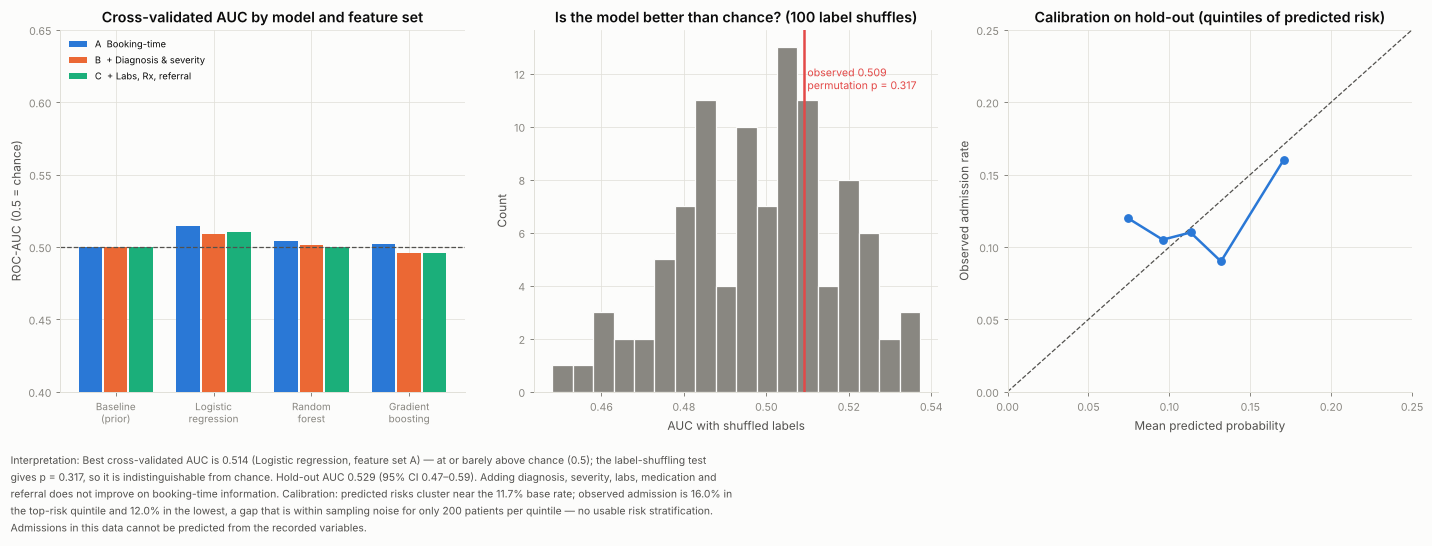

In [51]:
# permutation test: is the best CV AUC distinguishable from chance? (logistic regression, feature set B, 100 label shuffles)
numB, catB = SETS["B  + Diagnosis & severity"]; XB = Ew[numB + catB]
obs = ADM[(ADM.FeatureSet == "B  + Diagnosis & severity") & (ADM.Model == "Logistic regression")].AUC.iloc[0]
cv1 = StratifiedKFold(5, shuffle=True, random_state=SEED)
null_auc = []
for i in range(100):
    ysh = rng.permutation(yA)
    null_auc.append(cross_val_score(make_pipe(numB, catB, LogisticRegression(C=.1, max_iter=1000)), XB, ysh, cv=cv1, scoring="roc_auc").mean())
null_auc = np.array(null_auc); perm_p = (1 + (null_auc >= obs).sum()) / (1 + len(null_auc))
best_row = ADM.sort_values("AUC", ascending=False).iloc[0]
R["admission_perm_p"] = float(perm_p); R["admission_best"] = best_row.to_dict()

# hold-out evaluation of the best model, calibration & importance
Xtr, Xte, ytr, yte = train_test_split(Ew[SETS[best_row.FeatureSet][0] + SETS[best_row.FeatureSet][1]], yA, test_size=.2, stratify=yA, random_state=SEED)
num_b, cat_b = SETS[best_row.FeatureSet]
best_pipe = make_pipe(num_b, cat_b, CLFS[best_row.Model]()).fit(Xtr, ytr); pte = best_pipe.predict_proba(Xte)[:, 1]
auc_te = roc_auc_score(yte, pte)
bs_auc = [roc_auc_score(yte[ix], pte[ix]) for ix in (rng.integers(0, len(yte), len(yte)) for _ in range(500)) if len(np.unique(yte[ix])) == 2]
R["admission_holdout"] = dict(auc=float(auc_te), lo=float(np.percentile(bs_auc, 2.5)), hi=float(np.percentile(bs_auc, 97.5)), n_test=len(yte), pos_test=int(yte.sum()))
pi = permutation_importance(best_pipe, Xte, yte, scoring="roc_auc", n_repeats=15, random_state=SEED)
IMP = pd.DataFrame({"Feature": Xte.columns, "Importance": pi.importances_mean, "sd": pi.importances_std}).sort_values("Importance", ascending=False).head(10)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
pv_ = ADM.pivot(index="Model", columns="FeatureSet", values="AUC").loc[["Baseline (prior)", "Logistic regression", "Random forest", "Gradient boosting"]]
w_ = .26
for j, fsn in enumerate(pv_.columns):
    ax[0].bar(np.arange(len(pv_)) + (j - 1) * w_, pv_[fsn], width=w_ - .02, color=C[j], label=fsn)
ax[0].axhline(.5, color=INK2, ls="--", lw=1); ax[0].set_xticks(range(len(pv_))); ax[0].set_xticklabels([m.replace(" ", "\n", 1) for m in pv_.index], fontsize=8)
ax[0].set(title="Cross-validated AUC by model and feature set", ylabel="ROC-AUC (0.5 = chance)", ylim=(.4, .65)); ax[0].legend(fontsize=7.5, loc="upper left")
ax[1].hist(null_auc, bins=18, color=MUTED, edgecolor=SURF); ax[1].axvline(obs, color=C[7], lw=2); ax[1].text(obs, ax[1].get_ylim()[1] * .9, f" observed {obs:.3f}\n permutation {fmt_p(perm_p)}", color=C[7], fontsize=8.5, va="top")
ax[1].set(title="Is the model better than chance? (100 label shuffles)", xlabel="AUC with shuffled labels", ylabel="Count")
dec = pd.DataFrame({"y": yte, "p": pte}); dec["bin"] = pd.qcut(dec.p.rank(method="first"), 5, labels=False)
cal = dec.groupby("bin").agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
ax[2].plot([0, .25], [0, .25], color=INK2, ls="--", lw=1); ax[2].plot(cal.pred, cal.obs, "o-", color=C[0], lw=2); ax[2].set(title="Calibration on hold-out (quintiles of predicted risk)", xlabel="Mean predicted probability", ylabel="Observed admission rate", xlim=(0, .25), ylim=(0, .25))
fig.tight_layout()
top_imp = IMP.iloc[0]
save_fig(fig, "f30_admission_model",
         f"Best cross-validated AUC is {best_row.AUC:.3f} ({best_row.Model}, feature set {best_row.FeatureSet.split()[0]}) — at or barely above chance (0.5); the label-shuffling test gives {fmt_p(perm_p)}, so {'the skill is statistically detectable but practically negligible' if perm_p < .05 else 'it is indistinguishable from chance'}. "
         f"Hold-out AUC {auc_te:.3f} (95% CI {np.percentile(bs_auc, 2.5):.2f}–{np.percentile(bs_auc, 97.5):.2f}). Adding diagnosis, severity, labs, medication and referral does not improve on booking-time information. "
         f"Calibration: predicted risks cluster near the {pct(prev)} base rate; observed admission is {100 * cal.obs.iloc[-1]:.1f}% in the top-risk quintile and {100 * cal.obs.iloc[0]:.1f}% in the lowest, a gap that is within sampling noise for only {int(cal.n.iloc[0])} patients per quintile — no usable risk stratification. Admissions in this data cannot be predicted from the recorded variables.")

Admission probability scoring: predicted probability range on hold-out = 0.046 – 0.317 (base rate 0.117)


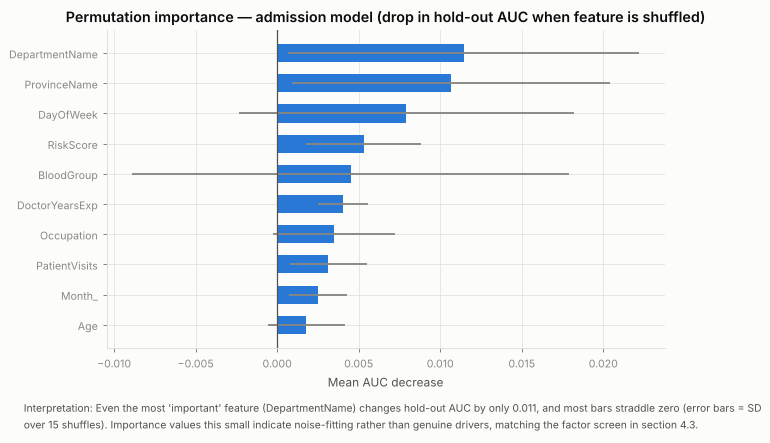

In [52]:
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(IMP.Feature[::-1], IMP.Importance[::-1], xerr=IMP["sd"][::-1], color=C[0], height=.6, ecolor=MUTED)
ax.axvline(0, color=INK2, lw=1); ax.set(title="Permutation importance — admission model (drop in hold-out AUC when feature is shuffled)", xlabel="Mean AUC decrease")
save_fig(fig, "f31_admission_importance", f"Even the most 'important' feature ({top_imp.Feature}) changes hold-out AUC by only {top_imp.Importance:.3f}, and most bars straddle zero (error bars = SD over 15 shuffles). "
         "Importance values this small indicate noise-fitting rather than genuine drivers, matching the factor screen in section 4.3.")
print("Admission probability scoring: predicted probability range on hold-out = %.3f – %.3f (base rate %.3f)" % (pte.min(), pte.max(), prev))

### 5.6 Task 4 — Patient-satisfaction prediction
**Target:** feedback rating (1–5). Two scopes, because information is available for different numbers of encounters:
* **Scope 1 — all feedback (n = 21,064):** clinical & financial variables only (diagnosis, severity, bill amount, payment ratio/status/method, claim provider/status/coverage).
* **Scope 2 — appointment cohort (n = 1,756):** adds operational variables (visit type, department, facility, workload index, admission, length of stay, referral, labs, doctor experience, demographics).

Regression metric: cross-validated R² and MAE against a predict-the-mean baseline; classification of "Satisfied" (rating ≥ 4) uses ROC-AUC.

In [53]:
S1 = FIN.dropna(subset=["Rating"]).copy(); S1["ClaimRatio"] = S1.ClaimRatio.fillna(0); S1["ClaimStatus"] = S1.ClaimStatus.fillna("No claim"); S1["ClaimProvider"] = S1.ClaimProvider.fillna("No claim")
s1_num = ["BillAmount", "PaidRatio", "ClaimRatio", "HasClaim", "SeverityScore"]; s1_cat = ["Diagnosis", "Severity", "BillStatus", "PayMethod", "ClaimProvider", "ClaimStatus"]
S2 = Ew[Ew.Rating.notna()].copy()
s2_num = ["Age", "BMI", "RiskScore", "DoctorYearsExp", "PatientVisits", "Month_", "BillAmount", "PaidRatio", "DeptWorkloadIndex", "Admitted", "LabDone", "Referred", "SeverityScore"]
s2_cat = ["Gender", "ChronicCondition", "VisitType", "DepartmentName", "FacilityID", "Diagnosis", "Severity", "BillStatus", "PayMethod", "ClaimProvider"]
S2["ClaimProvider"] = S2.ClaimProvider.fillna("No claim"); S2["LengthOfStayDays"] = S2.LengthOfStayDays.fillna(0)
REGS = {"Baseline (mean)": lambda: DummyRegressor(), "Ridge": lambda: Ridge(alpha=50),
        "Random forest": lambda: RandomForestRegressor(200, min_samples_leaf=40, max_features=.4, n_jobs=-1, random_state=SEED),
        "Gradient boosting": lambda: HistGradientBoostingRegressor(max_depth=3, learning_rate=.04, max_iter=100, l2_regularization=10, random_state=SEED)}
cvR = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED); sat_rows = []
for scope, df_, num_, cat_ in [("Scope 1 – all feedback (n=21,064)", S1, s1_num, s1_cat), ("Scope 2 – cohort + operational (n=1,756)", S2, s2_num, s2_cat)]:
    X_ = df_[num_ + cat_]; y_ = df_.Rating.values
    for mname, mk in REGS.items():
        cvr = cross_validate(make_pipe(num_, cat_, mk()), X_, y_, cv=cvR, scoring={"r2": "r2", "mae": "neg_mean_absolute_error"})
        sat_rows.append(dict(Scope=scope, Model=mname, R2=cvr["test_r2"].mean(), R2_sd=cvr["test_r2"].std(), MAE=-cvr["test_mae"].mean()))
    yb = (y_ >= 4).astype(int); aucs = {}
    for mname, mk in {"Logistic regression": lambda: LogisticRegression(C=.05, max_iter=2000), "Gradient boosting": CLFS["Gradient boosting"]}.items():
        a_ = cross_val_score(make_pipe(num_, cat_, mk()), X_, yb, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")
        sat_rows.append(dict(Scope=scope, Model=f"{mname} → P(rating ≥ 4)", R2=np.nan, R2_sd=np.nan, MAE=np.nan, AUC=a_.mean(), AUC_sd=a_.std()))
SAT = pd.DataFrame(sat_rows); R["satisfaction_models"] = SAT.round(4).to_dict("records")
pd.options.display.float_format = "{:,.4f}".format
SAT

,Scope,Model,R2,R2_sd,MAE,AUC,AUC_sd
0,"Scope 1 – all feedback (n=21,064)",Baseline (mean),-0.0002,0.0002,1.2015,NaN,NaN
1,"Scope 1 – all feedback (n=21,064)",Ridge,-0.0013,0.0010,1.2064,NaN,NaN
2,"Scope 1 – all feedback (n=21,064)",Random forest,-0.0054,0.0017,1.2144,NaN,NaN
3,"Scope 1 – all feedback (n=21,064)",Gradient boosting,-0.0011,0.0007,1.2039,NaN,NaN
4,"Scope 1 – all feedback (n=21,064)",Logistic regression → P(rating ≥ 4),NaN,NaN,NaN,0.4984,0.0080
5,"Scope 1 – all feedback (n=21,064)",Gradient boosting → P(rating ≥ 4),NaN,NaN,NaN,0.5000,0.0053
6,"Scope 2 – cohort + operational (n=1,756)",Baseline (mean),-0.0026,0.0034,1.1752,NaN,NaN
7,"Scope 2 – cohort + operational (n=1,756)",Ridge,-0.0292,0.0188,1.2013,NaN,NaN
8,"Scope 2 – cohort + operational (n=1,756)",Random forest,-0.0086,0.0096,1.1835,NaN,NaN
9,"Scope 2 – cohort + operational (n=1,756)",Gradient boosting,-0.0246,0.0110,1.1961,NaN,NaN


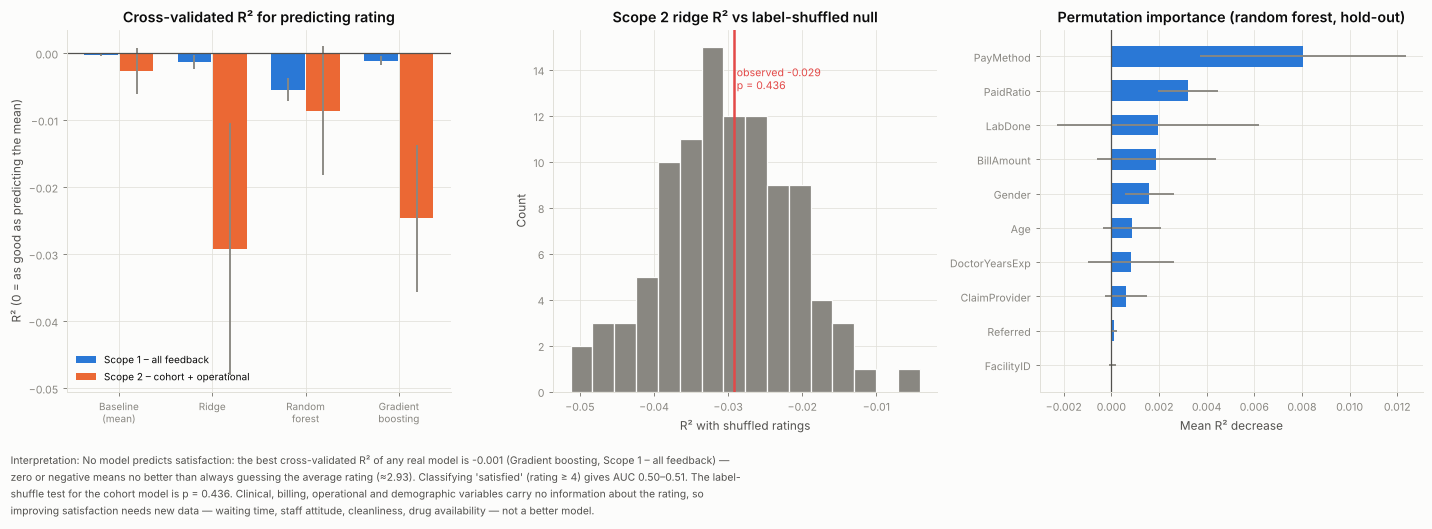

In [54]:
# permutation test + importance for the scope-2 model; share-satisfied baseline
Xs, ys = S2[s2_num + s2_cat], S2.Rating.values
obs_r2 = SAT[(SAT.Scope.str.startswith("Scope 2")) & (SAT.Model == "Ridge")].R2.iloc[0]
cvs = KFold = None
from sklearn.model_selection import KFold
null_r2 = np.array([cross_val_score(make_pipe(s2_num, s2_cat, Ridge(alpha=50)), Xs, rng.permutation(ys), cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2").mean() for _ in range(100)])
perm_p_sat = (1 + (null_r2 >= obs_r2).sum()) / (1 + len(null_r2))
rf_s = make_pipe(s2_num, s2_cat, REGS["Random forest"]()); Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=.25, random_state=SEED); rf_s.fit(Xtr, ytr)
pis = permutation_importance(rf_s, Xte, yte, scoring="r2", n_repeats=15, random_state=SEED)
IMP_S = pd.DataFrame({"Feature": Xte.columns, "Importance": pis.importances_mean, "sd": pis.importances_std}).sort_values("Importance", ascending=False).head(10)
best_s = SAT.dropna(subset=["R2"])[~SAT.Model.str.startswith("Baseline")].sort_values("R2", ascending=False).iloc[0]
R["sat_perm_p"], R["sat_best"] = float(perm_p_sat), best_s.to_dict(); R["sat_holdout_r2"] = float(r2_score(yte, rf_s.predict(Xte)))
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
reg = SAT.dropna(subset=["R2"]); sc_ = list(reg.Scope.unique())
for j, sc in enumerate(sc_):
    d_ = reg[reg.Scope == sc]; ax[0].bar(np.arange(len(d_)) + (j - .5) * .38, d_.R2, width=.36, yerr=d_.R2_sd, color=C[j], label=sc.split(" (")[0], ecolor=MUTED)
ax[0].axhline(0, color=INK2, lw=1); ax[0].set_xticks(range(4)); ax[0].set_xticklabels([m.replace(" ", "\n", 1) for m in reg.Model.unique()], fontsize=8)
ax[0].set(title="Cross-validated R² for predicting rating", ylabel="R² (0 = as good as predicting the mean)"); ax[0].legend(fontsize=8)
ax[1].hist(null_r2, bins=16, color=MUTED, edgecolor=SURF); ax[1].axvline(obs_r2, color=C[7], lw=2); ax[1].set(title="Scope 2 ridge R² vs label-shuffled null", xlabel="R² with shuffled ratings", ylabel="Count")
ax[1].text(obs_r2, ax[1].get_ylim()[1] * .9, f" observed {obs_r2:.3f}\n {fmt_p(perm_p_sat)}", color=C[7], fontsize=8.5, va="top")
ax[2].barh(IMP_S.Feature[::-1], IMP_S.Importance[::-1], xerr=IMP_S["sd"][::-1], color=C[0], height=.6, ecolor=MUTED); ax[2].axvline(0, color=INK2, lw=1)
ax[2].set(title="Permutation importance (random forest, hold-out)", xlabel="Mean R² decrease")
fig.tight_layout()
auc_rows = SAT.dropna(subset=["AUC"])
save_fig(fig, "f32_satisfaction_model",
         f"No model predicts satisfaction: the best cross-validated R² of any real model is {best_s.R2:.3f} ({best_s.Model}, {best_s.Scope.split(' (')[0]}) — zero or negative means no better than always guessing the average rating (≈{ys.mean():.2f}). "
         f"Classifying 'satisfied' (rating ≥ 4) gives AUC {auc_rows.AUC.min():.2f}–{auc_rows.AUC.max():.2f}. The label-shuffle test for the cohort model is {fmt_p(perm_p_sat)}. "
         "Clinical, billing, operational and demographic variables carry no information about the rating, so improving satisfaction needs new data — waiting time, staff attitude, cleanliness, drug availability — not a better model.")

## 6. Clustering analysis & dimensionality reduction
Three segmentations are built — **patients**, **facilities** and **departments** — each with K-Means (k chosen by silhouette) and, for facilities,
Ward hierarchical clustering. Because clustering *always* returns groups, each solution is compared with a **null** built by shuffling every column
independently (which destroys any real structure while keeping the same marginal distributions). Clusters are only treated as meaningful if they beat that null.

In [55]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

def sil_curve(Z, ks, sample=4000, reps_null=4, seed=SEED):
    rg = np.random.default_rng(seed); out = []
    for k in ks:
        km = KMeans(k, n_init=10, random_state=seed).fit(Z); s_ = silhouette_score(Z, km.labels_, sample_size=min(sample, len(Z)), random_state=seed) if len(Z) > sample else silhouette_score(Z, km.labels_)
        nl = []
        for _ in range(reps_null):
            Zn = np.column_stack([rg.permutation(Z[:, j]) for j in range(Z.shape[1])]); kn = KMeans(k, n_init=5, random_state=seed).fit(Zn)
            nl.append(silhouette_score(Zn, kn.labels_, sample_size=min(sample, len(Zn)), random_state=seed) if len(Zn) > sample else silhouette_score(Zn, kn.labels_))
        out.append(dict(k=k, inertia=km.inertia_, silhouette=s_, null_mean=np.mean(nl), null_max=np.max(nl)))
    return pd.DataFrame(out)

def name_cluster(z, labels, top=2, thr=.35):
    idx = np.argsort(-np.abs(z))[:top]; parts = [(("high " if z[i] > 0 else "low ") + labels[i]) for i in idx if abs(z[i]) >= thr]
    return ", ".join(parts) if parts else "near-average profile"

### 6.1 Patient segmentation (20,000 patients)
Features: age, BMI, three chronic-condition indicators, gender, and 2026 visit count (0 for patients with no recorded appointment).

In [56]:
PP = PATIENTS.copy()
for c_ in ["Asthma", "Hypertension", "Diabetes"]: PP[c_] = (PP.ChronicCondition == c_).astype(int)
PP["Female"] = (PP.Gender == "Female").astype(int)
pf = ["Age", "BMI", "Asthma", "Hypertension", "Diabetes", "Female", "Visits2026"]
ZP = StandardScaler().fit_transform(PP[pf])
SIL_P = sil_curve(ZP, range(2, 9))
kP = int(SIL_P.loc[SIL_P.silhouette.idxmax(), "k"]); kmP = KMeans(kP, n_init=15, random_state=SEED).fit(ZP); PP["Cluster"] = kmP.labels_
ari_P = adjusted_rand_score(kmP.labels_, KMeans(kP, n_init=15, random_state=SEED + 7).fit(ZP).labels_)   # seed-to-seed stability
# a clinically-interpretable 4-segment solution for management use (k = 4) is shown alongside, regardless of silhouette
k_use = 4; km4 = KMeans(k_use, n_init=15, random_state=SEED).fit(ZP); PP["Segment"] = km4.labels_
adm_pat = E.groupby("PatientID").agg(Admit=("Admitted", "max"), Bill=("BillAmount", "mean"))
PP = PP.merge(adm_pat, left_on="PatientID", right_index=True, how="left")
prof = PP.groupby("Segment").agg(Patients=("PatientID", "size"), MeanAge=("Age", "mean"), MeanBMI=("BMI", "mean"), Asthma=("Asthma", "mean"), Hypertension=("Hypertension", "mean"), Diabetes=("Diabetes", "mean"),
                                  Female=("Female", "mean"), MeanVisits=("Visits2026", "mean"), HighRisk=("HighRisk", "mean"), ChronicAny=("ChronicFlag", "mean"), AdmitRate=("Admit", "mean"), SeenPts=("Admit", "count"))
zprof = pd.DataFrame(km4.cluster_centers_, columns=pf)
prof["Description"] = [name_cluster(zprof.iloc[i].values, ["age", "BMI", "asthma", "hypertension", "diabetes", "female share", "visit count"]) for i in range(k_use)]
prof = prof.sort_values("HighRisk", ascending=False); prof["Label"] = [f"S{i + 1}" for i in range(len(prof))]
R["patient_clusters"] = dict(k_best=kP, sil_best=float(SIL_P.silhouette.max()), null_sil_at_best=float(SIL_P.loc[SIL_P.silhouette.idxmax(), "null_mean"]), ari=float(ari_P),
                             profile=prof.reset_index().round(4).to_dict("records"), sil_table=SIL_P.round(4).to_dict("records"))
ch_ = stats.chi2_contingency(pd.crosstab(PP.dropna(subset=["Admit"]).Segment, PP.dropna(subset=["Admit"]).Admit)); R["patient_cluster_admit_p"] = float(ch_[1])
pd.options.display.float_format = "{:,.3f}".format
print(f"Silhouette by k (real vs shuffled-null):"); print(SIL_P.round(3).to_string(index=False)); print(f"\nBest k = {kP}, seed-to-seed stability (ARI) = {ari_P:.2f}")
prof[["Label", "Patients", "MeanAge", "MeanBMI", "ChronicAny", "Hypertension", "Diabetes", "Asthma", "Female", "MeanVisits", "HighRisk", "AdmitRate", "SeenPts", "Description"]]

Silhouette by k (real vs shuffled-null):
 k     inertia  silhouette  null_mean  null_max
 2 115,599.058       0.203      0.184     0.193
 3  93,430.333       0.263      0.184     0.208
 4  79,994.530       0.262      0.192     0.220
 5  73,001.248       0.252      0.194     0.206
 6  68,236.592       0.255      0.193     0.228
 7  64,213.935       0.234      0.190     0.205
 8  59,359.622       0.275      0.214     0.221

Best k = 8, seed-to-seed stability (ARI) = 1.00


,Label,Patients,MeanAge,MeanBMI,ChronicAny,Hypertension,Diabetes,Asthma,Female,MeanVisits,HighRisk,AdmitRate,SeenPts,Description
Segment,,,,,,,,,,,,,,
1,S1,4996,45.251,30.101,1.000,0.000,0.000,1.000,0.495,0.252,0.389,0.129,1116,"high asthma, low hypertension"
0,S2,4988,44.716,30.118,1.000,1.000,0.000,0.000,0.492,0.253,0.384,0.136,1104,"high hypertension, low asthma"
2,S3,4945,44.657,29.977,1.000,0.000,1.000,0.000,0.496,0.246,0.380,0.135,1092,"high diabetes, low asthma"
3,S4,5071,45.498,29.978,0.000,0.000,0.000,0.000,0.498,0.249,0.183,0.121,1131,"low asthma, low hypertension"


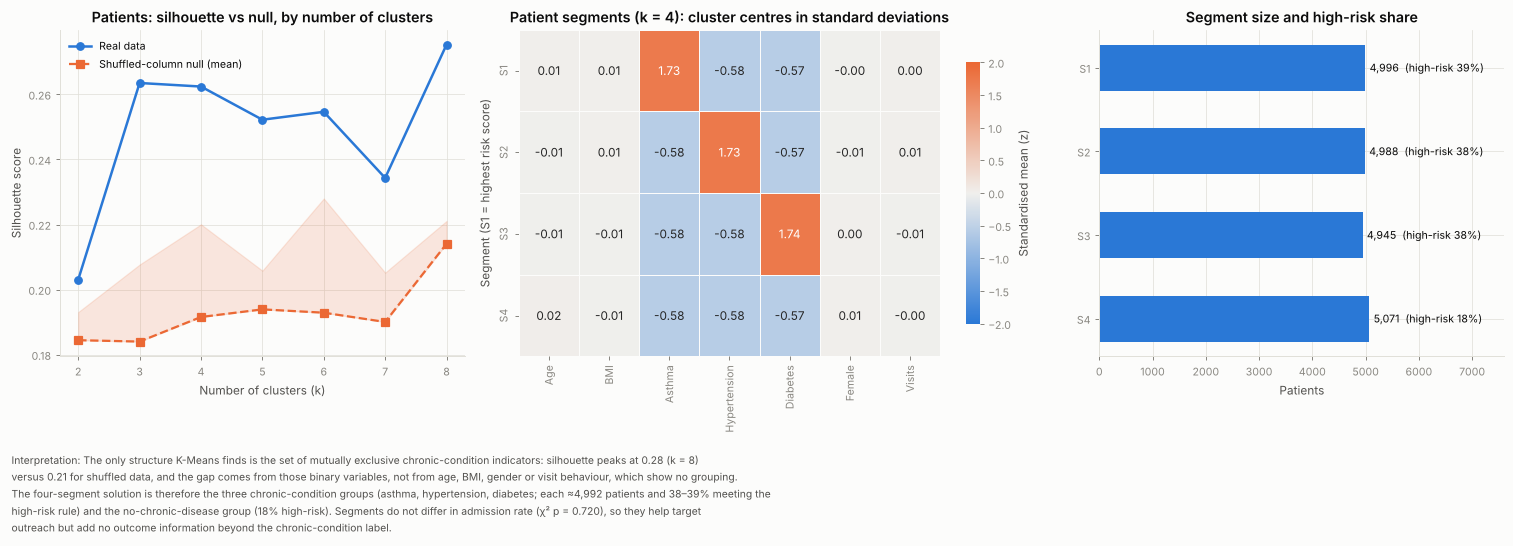

In [57]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1.3, 1]})
ax[0].plot(SIL_P.k, SIL_P.silhouette, "o-", color=C[0], lw=2, label="Real data"); ax[0].plot(SIL_P.k, SIL_P.null_mean, "s--", color=C[1], lw=1.8, label="Shuffled-column null (mean)")
ax[0].fill_between(SIL_P.k, SIL_P.null_mean, SIL_P.null_max, color=C[1], alpha=.15); ax[0].set(title="Patients: silhouette vs null, by number of clusters", xlabel="Number of clusters (k)", ylabel="Silhouette score"); ax[0].legend(fontsize=8.5)
hm = pd.DataFrame(km4.cluster_centers_, columns=["Age", "BMI", "Asthma", "Hypertension", "Diabetes", "Female", "Visits"]).loc[prof.index]; hm.index = prof.Label
sns.heatmap(hm, cmap=DIV, center=0, vmin=-2, vmax=2, annot=True, fmt=".2f", linewidths=.6, linecolor=SURF, cbar_kws={"label": "Standardised mean (z)", "shrink": .8}, ax=ax[1]); ax[1].grid(False)
ax[1].set(title=f"Patient segments (k = {k_use}): cluster centres in standard deviations", ylabel="Segment (S1 = highest risk score)")
sz = prof.set_index("Label").Patients; ax[2].barh(sz.index[::-1], sz.values[::-1], color=C[0], height=.55)
for i, (v, h_) in enumerate(zip(sz.values[::-1], prof.set_index("Label").HighRisk.values[::-1])): ax[2].text(v + 80, i, f"{v:,}  (high-risk {h_:.0%})", va="center", fontsize=8.5)
ax[2].set(title="Segment size and high-risk share", xlabel="Patients", xlim=(0, sz.max() * 1.5))
fig.tight_layout()
save_fig(fig, "f33_patient_clusters",
         f"The only structure K-Means finds is the set of mutually exclusive chronic-condition indicators: silhouette peaks at {SIL_P.silhouette.max():.2f} (k = {kP}) versus {SIL_P.loc[SIL_P.silhouette.idxmax(), 'null_mean']:.2f} for shuffled data, and the gap comes from those binary variables, not from age, BMI, gender or visit behaviour, which show no grouping. "
         f"The four-segment solution is therefore the three chronic-condition groups (asthma, hypertension, diabetes; each ≈{int(prof.Patients.median()):,} patients and {100 * prof.HighRisk.sort_values().iloc[-3:].min():.0f}–{100 * prof.HighRisk.max():.0f}% meeting the high-risk rule) and the no-chronic-disease group ({100 * prof.HighRisk.min():.0f}% high-risk). "
         f"Segments do not differ in admission rate (χ² {fmt_p(ch_[1])}), so they help target outreach but add no outcome information beyond the chronic-condition label.")

### 6.2 Facility segmentation (20 facilities)
Twelve operational, clinical, financial and experience measures per facility (from the appointment cohort). With 20 facilities the solution is
descriptive: it groups sites with similar profiles so management can compare like with like.

In [58]:
fcols = ["Appointments", "EmergencyShare", "AdmitRate", "MeanLOS", "ReferralRate", "MeanSeverity", "MeanBill", "CollectionRate", "ClaimApproval", "MeanRating", "ApptPerClinician", "StaffPer1000Pts"]
KF = K[fcols].copy(); ZF = StandardScaler().fit_transform(KF)
SIL_F = []
for k in range(2, 7):
    lab = KMeans(k, n_init=20, random_state=SEED).fit_predict(ZF); SIL_F.append(dict(k=k, silhouette=silhouette_score(ZF, lab)))
rg = np.random.default_rng(SEED); nullF = []
for _ in range(200):
    Zn = np.column_stack([rg.permutation(ZF[:, j]) for j in range(ZF.shape[1])]); nullF.append(max(silhouette_score(Zn, KMeans(k, n_init=5, random_state=0).fit_predict(Zn)) for k in range(2, 7)))
SIL_F = pd.DataFrame(SIL_F); kF = int(SIL_F.loc[SIL_F.silhouette.idxmax(), "k"]); best_sF = SIL_F.silhouette.max()
perm_pF = (1 + (np.array(nullF) >= best_sF).sum()) / (1 + len(nullF))
labF = KMeans(kF, n_init=20, random_state=SEED).fit_predict(ZF); KF["Cluster"] = labF
ward = linkage(ZF, "ward"); labW = fcluster(ward, kF, "maxclust"); ari_FW = adjusted_rand_score(labF, labW)
KF["PerformanceScore"] = K.PerformanceScore
pf_ = KF.groupby("Cluster").agg(Facilities=("Appointments", "size"), **{c_: (c_, "mean") for c_ in fcols}, PerformanceScore=("PerformanceScore", "mean"))
zc = (pf_[fcols] - KF[fcols].mean()) / KF[fcols].std(ddof=0)
pf_["Description"] = [name_cluster(zc.iloc[i].values, ["volume", "emergency share", "admission rate", "stay length", "referral rate", "severity", "bill size", "collection rate", "claim approval", "satisfaction", "load per clinician", "staff ratio"], top=3, thr=.4) for i in range(len(pf_))]
pf_["Members"] = KF.groupby("Cluster").apply(lambda d: ", ".join(d.index.str[-2:]))
R["facility_clusters"] = dict(k=kF, silhouette=float(best_sF), null_p=float(perm_pF), ari_kmeans_ward=float(ari_FW), profile=pf_.reset_index().round(4).to_dict("records"), sil_table=SIL_F.round(4).to_dict("records"))
pd.options.display.float_format = "{:,.3f}".format
print(f"Best k = {kF}, silhouette {best_sF:.3f}; chance of a silhouette ≥ this in shuffled data: {fmt_p(perm_pF)}; K-Means vs Ward agreement (ARI) = {ari_FW:.2f}")
pf_[["Facilities", "Members", "Appointments", "MeanRating", "CollectionRate", "AdmitRate", "ApptPerClinician", "PerformanceScore", "Description"]]

Best k = 2, silhouette 0.187; chance of a silhouette ≥ this in shuffled data: p = 0.005; K-Means vs Ward agreement (ARI) = 0.80


,Facilities,Members,Appointments,MeanRating,CollectionRate,AdmitRate,ApptPerClinician,PerformanceScore,Description
Cluster,,,,,,,,,
0,9,"01, 06, 08, 10, 11, 12, 13, 14, 16",267.889,2.963,0.906,0.113,5.108,71.293,"high volume, high load per clinician, low staff ratio"
1,11,"02, 03, 04, 05, 07, 09, 15, 17, 18, 19, 20",235.364,2.894,0.896,0.121,4.480,35.903,"low volume, low load per clinician, high staff ratio"


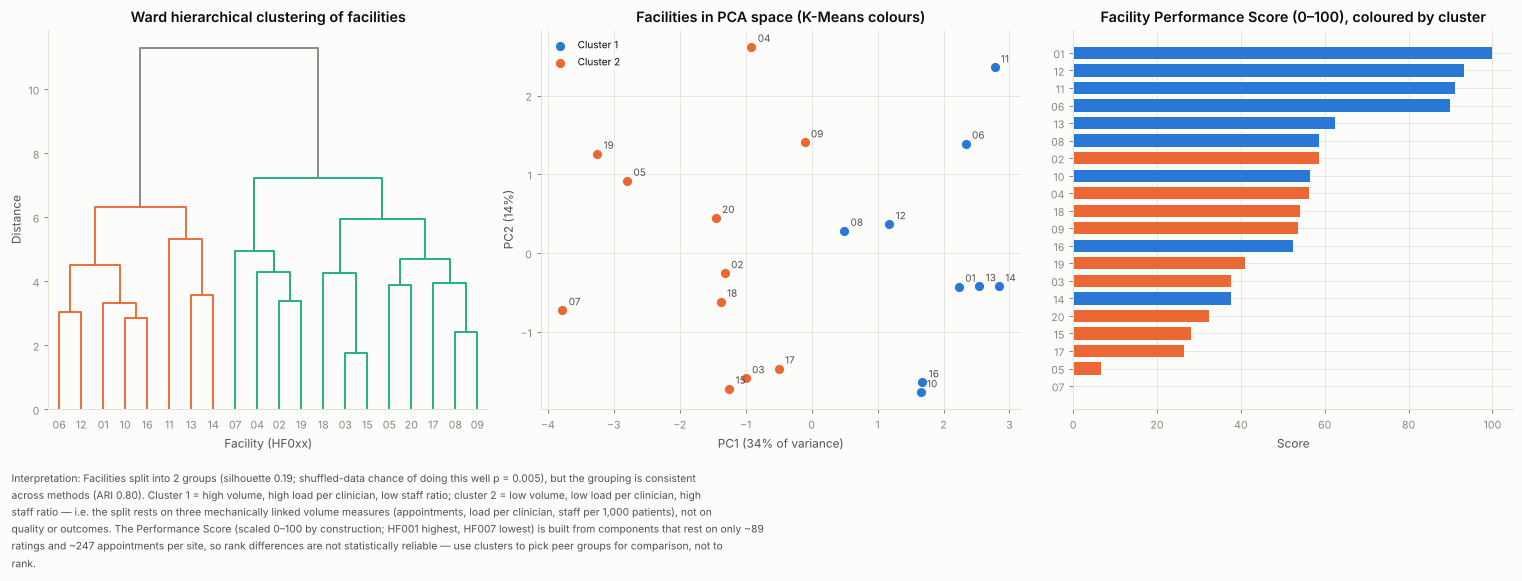

In [59]:
pcaF = PCA(2).fit(ZF); XF = pcaF.transform(ZF)
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.1, 1.2, 1.1]})
dn = dendrogram(ward, labels=KF.index.str[-2:].values, ax=ax[0], color_threshold=ward[-(kF - 1), 2] if kF > 1 else None, above_threshold_color=MUTED, leaf_font_size=8.5)
ax[0].set(title="Ward hierarchical clustering of facilities", xlabel="Facility (HF0xx)", ylabel="Distance"); ax[0].grid(False)
for c_ in range(kF):
    m_ = labF == c_; ax[1].scatter(XF[m_, 0], XF[m_, 1], s=70, color=C[c_], edgecolor=SURF, label=f"Cluster {c_ + 1}", zorder=3)
for i, f_ in enumerate(KF.index): ax[1].annotate(f_[-2:], XF[i], textcoords="offset points", xytext=(5, 4), fontsize=8, color=INK2)
ax[1].set(title="Facilities in PCA space (K-Means colours)", xlabel=f"PC1 ({100 * pcaF.explained_variance_ratio_[0]:.0f}% of variance)", ylabel=f"PC2 ({100 * pcaF.explained_variance_ratio_[1]:.0f}%)"); ax[1].legend(fontsize=8)
ps = K.PerformanceScore.sort_values(ascending=False)
ax[2].barh(ps.index.str[-2:][::-1], ps.values[::-1], color=[C[int(KF.loc[f_, "Cluster"])] for f_ in ps.index[::-1]], height=.7); ax[2].set(title="Facility Performance Score (0–100), coloured by cluster", xlabel="Score")
fig.tight_layout()
save_fig(fig, "f34_facility_clusters",
         f"Facilities split into {kF} groups (silhouette {best_sF:.2f}; shuffled-data chance of doing this well {fmt_p(perm_pF)}), but the grouping is {'fairly weak and not stable: K-Means and Ward agree only moderately (ARI ' + f'{ari_FW:.2f}' + ')' if ari_FW < .6 else 'consistent across methods (ARI ' + f'{ari_FW:.2f}' + ')'}. "
         f"Cluster 1 = {pf_.iloc[0].Description}; cluster 2 = {pf_.iloc[1].Description if len(pf_) > 1 else 'n/a'} — i.e. the split rests on three mechanically linked volume measures (appointments, load per clinician, staff per 1,000 patients), not on quality or outcomes. The Performance Score (scaled 0–100 by construction; {ps.index[0]} highest, {ps.index[-1]} lowest) is built from components that rest on only ~{int(K.RatedN.median())} ratings and ~{int(K.Appointments.median())} appointments per site, so rank differences are not statistically reliable — use clusters to pick peer groups for comparison, not to rank.")

### 6.3 Department segmentation (200 departments)
Features per department-ID: appointments, emergency share, admission rate, lab and prescription intensity, mean severity, mean bill and appointments per clinician
(workload). With ≈25 appointments per department these are noisy, so the null comparison matters most here.

In [60]:
dcols = ["Appointments", "Emergency", "AdmitRate", "LabPerAppt", "RxPerAppt", "MeanSeverity", "MeanBill", "ApptPerClinician"]
DD = DEPT[dcols].replace([np.inf, -np.inf], np.nan).dropna(); ZD = StandardScaler().fit_transform(DD)
SIL_D = sil_curve(ZD, range(2, 8), sample=200, reps_null=5)
kD = int(SIL_D.loc[SIL_D.silhouette.idxmax(), "k"]); kmD = KMeans(kD, n_init=15, random_state=SEED).fit(ZD); DD["Cluster"] = kmD.labels_
k_show = 4; km4d = KMeans(k_show, n_init=15, random_state=SEED).fit(ZD); DD["Segment"] = km4d.labels_
dprof = DD.groupby("Segment").agg(Departments=("Appointments", "size"), **{c_: (c_, "mean") for c_ in dcols})
zd = pd.DataFrame(km4d.cluster_centers_, columns=dcols)
dprof["Description"] = [name_cluster(zd.iloc[i].values, ["volume", "emergency share", "admission rate", "lab intensity", "Rx intensity", "severity", "bill size", "load per clinician"], top=3, thr=.5) for i in range(k_show)]
dtype_mix = DD.join(DEPT.DepartmentName).groupby("Segment").DepartmentName.agg(lambda s: s.value_counts().index[0] + f" ({s.value_counts().iloc[0] / len(s):.0%})")
dprof["Most common type"] = dtype_mix
ch_d = stats.chi2_contingency(pd.crosstab(DD.join(DEPT.DepartmentName).Segment, DD.join(DEPT.DepartmentName).DepartmentName)); R["dept_cluster_type_p"] = float(ch_d[1])
R["dept_clusters"] = dict(k_best=kD, sil_best=float(SIL_D.silhouette.max()), null_at_best=float(SIL_D.loc[SIL_D.silhouette.idxmax(), "null_mean"]), profile=dprof.reset_index().round(3).to_dict("records"))
print(SIL_D.round(3).to_string(index=False)); print(f"\nBest k = {kD}; χ² of segment vs department type: {fmt_p(ch_d[1])}")
dprof

 k   inertia  silhouette  null_mean  null_max
 2 1,346.484       0.143      0.103     0.116
 3 1,225.660       0.127      0.096     0.101
 4 1,144.012       0.123      0.096     0.107
 5 1,075.767       0.122      0.102     0.107
 6 1,016.433       0.106      0.103     0.116
 7   980.896       0.111      0.101     0.114

Best k = 2; χ² of segment vs department type: p = 0.604


,Departments,Appointments,Emergency,AdmitRate,LabPerAppt,RxPerAppt,MeanSeverity,MeanBill,ApptPerClinician,Description,Most common type
Segment,,,,,,,,,,,
0,47,22.340,0.319,0.088,0.531,0.754,1.896,"145,576.200",4.278,"high lab intensity, low Rx intensity, low severity",Pediatrics (15%)
1,69,29.449,0.328,0.113,0.434,0.767,1.992,"158,367.020",6.229,"high load per clinician, high volume",Cardiology (16%)
2,40,21.925,0.270,0.163,0.499,0.847,2.131,"151,324.214",4.156,"high severity, high admission rate, low volume",Pharmacy (18%)
3,44,23.659,0.396,0.115,0.373,0.868,1.966,"158,284.377",4.180,"high Rx intensity, low lab intensity, high emergency share",Obstetrics & Gynecology (16%)


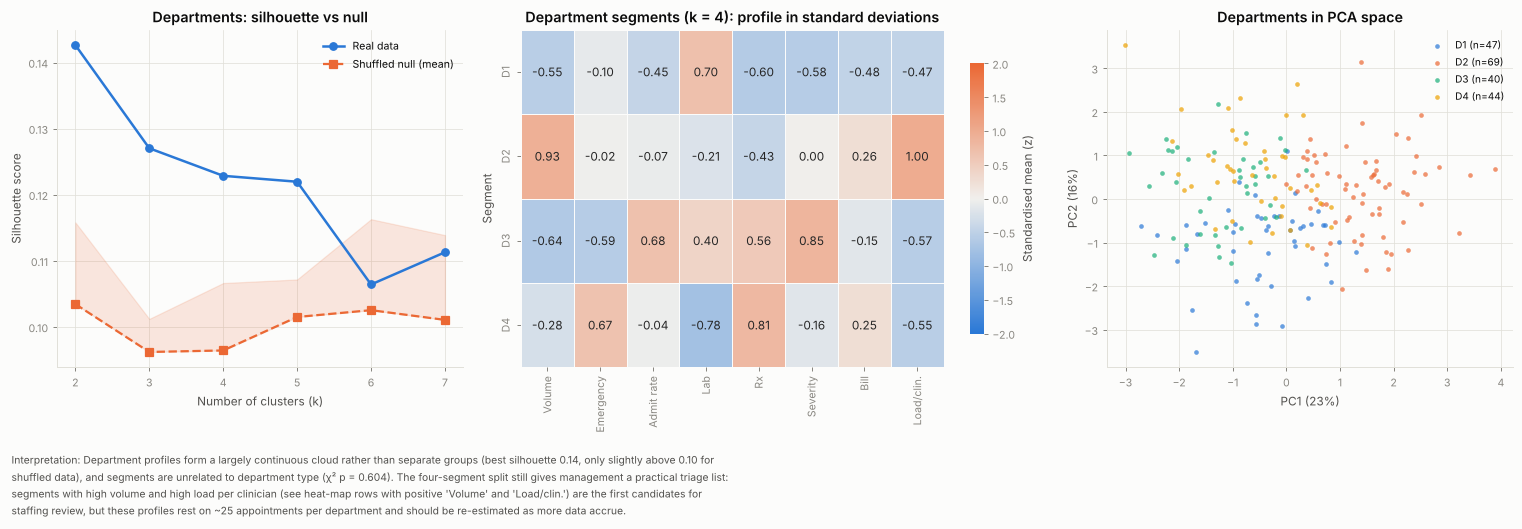

In [61]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1.3, 1]})
ax[0].plot(SIL_D.k, SIL_D.silhouette, "o-", color=C[0], lw=2, label="Real data"); ax[0].plot(SIL_D.k, SIL_D.null_mean, "s--", color=C[1], lw=1.8, label="Shuffled null (mean)"); ax[0].fill_between(SIL_D.k, SIL_D.null_mean, SIL_D.null_max, color=C[1], alpha=.15)
ax[0].set(title="Departments: silhouette vs null", xlabel="Number of clusters (k)", ylabel="Silhouette score"); ax[0].legend(fontsize=8.5)
hd = pd.DataFrame(km4d.cluster_centers_, columns=["Volume", "Emergency", "Admit rate", "Lab", "Rx", "Severity", "Bill", "Load/clin."]); hd.index = [f"D{i + 1}" for i in range(k_show)]
sns.heatmap(hd, cmap=DIV, center=0, vmin=-2, vmax=2, annot=True, fmt=".2f", linewidths=.6, linecolor=SURF, cbar_kws={"label": "Standardised mean (z)", "shrink": .8}, ax=ax[1]); ax[1].grid(False)
ax[1].set(title=f"Department segments (k = {k_show}): profile in standard deviations", ylabel="Segment")
pcd = PCA(2).fit(ZD); XD = pcd.transform(ZD)
for c_ in range(k_show): ax[2].scatter(XD[DD.Segment.values == c_, 0], XD[DD.Segment.values == c_, 1], s=14, alpha=.7, color=C[c_], label=f"D{c_ + 1} (n={int((DD.Segment == c_).sum())})", linewidths=0)
ax[2].set(title="Departments in PCA space", xlabel=f"PC1 ({100 * pcd.explained_variance_ratio_[0]:.0f}%)", ylabel=f"PC2 ({100 * pcd.explained_variance_ratio_[1]:.0f}%)"); ax[2].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "f35_department_clusters",
         f"Department profiles form a largely continuous cloud rather than separate groups (best silhouette {SIL_D.silhouette.max():.2f}, only slightly above {SIL_D.loc[SIL_D.silhouette.idxmax(), 'null_mean']:.2f} for shuffled data), and segments are unrelated to department type (χ² {fmt_p(ch_d[1])}). "
         "The four-segment split still gives management a practical triage list: segments with high volume and high load per clinician (see heat-map rows with positive 'Volume' and 'Load/clin.') are the first candidates for staffing review, but these profiles rest on ~25 appointments per department and should be re-estimated as more data accrue.")

### 6.4 Principal Component Analysis
PCA is applied to the standardised patient feature matrix (numeric + chronic indicators + visits) and to the facility feature matrix to show how many dimensions are really present.

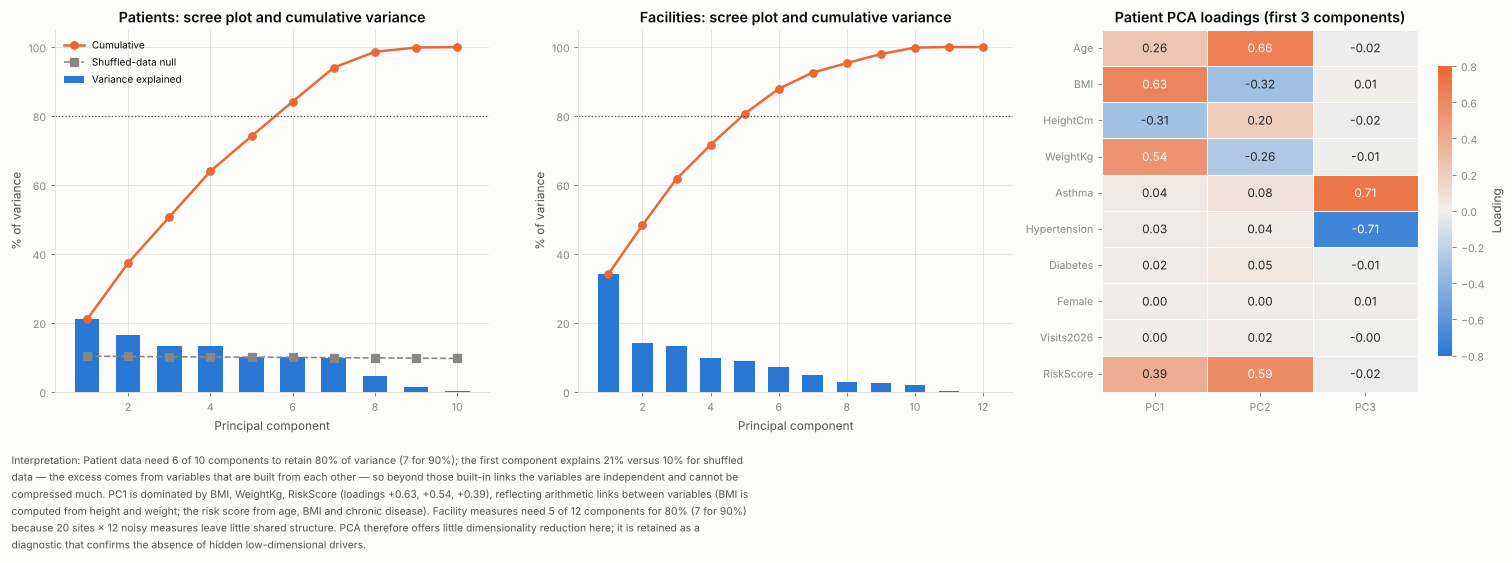

In [62]:
pf_all = ["Age", "BMI", "HeightCm", "WeightKg", "Asthma", "Hypertension", "Diabetes", "Female", "Visits2026", "RiskScore"]
ZPA = StandardScaler().fit_transform(PP[pf_all]); pcaP = PCA().fit(ZPA); evrP = pcaP.explained_variance_ratio_; cumP = evrP.cumsum()
pcaFa = PCA().fit(ZF); evrF = pcaFa.explained_variance_ratio_; cumF = evrF.cumsum()
n80P, n90P = int(np.argmax(cumP >= .8) + 1), int(np.argmax(cumP >= .9) + 1); n80F, n90F = int(np.argmax(cumF >= .8) + 1), int(np.argmax(cumF >= .9) + 1)
# parallel-analysis style null: eigenvalues from column-shuffled data
nullE = np.mean([PCA().fit(np.column_stack([rng.permutation(ZPA[:, j]) for j in range(ZPA.shape[1])])).explained_variance_ratio_ for _ in range(20)], axis=0)
load = pd.DataFrame(pcaP.components_[:3].T, index=pf_all, columns=["PC1", "PC2", "PC3"])
R["pca"] = dict(patients=dict(evr=evrP.round(4).tolist(), n80=n80P, n90=n90P, n_features=len(pf_all), pc1=float(evrP[0])), facilities=dict(evr=evrF.round(4).tolist(), n80=n80F, n90=n90F, n_features=len(fcols), pc1=float(evrF[0])))
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
ax[0].bar(range(1, len(evrP) + 1), 100 * evrP, color=C[0], width=.6, label="Variance explained"); ax[0].plot(range(1, len(evrP) + 1), 100 * cumP, "o-", color=C[1], lw=2, label="Cumulative")
ax[0].plot(range(1, len(evrP) + 1), 100 * nullE, "s--", color=MUTED, lw=1.3, label="Shuffled-data null"); ax[0].axhline(80, color=INK2, ls=":", lw=1)
ax[0].set(title="Patients: scree plot and cumulative variance", xlabel="Principal component", ylabel="% of variance"); ax[0].legend(fontsize=8)
ax[1].bar(range(1, len(evrF) + 1), 100 * evrF, color=C[0], width=.6); ax[1].plot(range(1, len(evrF) + 1), 100 * cumF, "o-", color=C[1], lw=2); ax[1].axhline(80, color=INK2, ls=":", lw=1)
ax[1].set(title="Facilities: scree plot and cumulative variance", xlabel="Principal component", ylabel="% of variance")
sns.heatmap(load, cmap=DIV, center=0, vmin=-.8, vmax=.8, annot=True, fmt=".2f", linewidths=.6, linecolor=SURF, cbar_kws={"label": "Loading", "shrink": .8}, ax=ax[2]); ax[2].grid(False); ax[2].set(title="Patient PCA loadings (first 3 components)")
fig.tight_layout()
save_fig(fig, "f36_pca",
         f"Patient data need {n80P} of {len(pf_all)} components to retain 80% of variance ({n90P} for 90%); the first component explains {100 * evrP[0]:.0f}% versus {100 * nullE[0]:.0f}% for shuffled data — the excess comes from variables that are built from each other — so beyond those built-in links the variables are independent and cannot be compressed much. "
         f"PC1 is dominated by {', '.join(load.PC1.abs().sort_values(ascending=False).head(3).index)} (loadings {', '.join(f'{load.PC1[i]:+.2f}' for i in load.PC1.abs().sort_values(ascending=False).head(3).index)}), reflecting arithmetic links between variables (BMI is computed from height and weight; the risk score from age, BMI and chronic disease). Facility measures need {n80F} of {len(fcols)} components for 80% ({n90F} for 90%) because 20 sites × 12 noisy measures leave little shared structure. "
         "PCA therefore offers little dimensionality reduction here; it is retained as a diagnostic that confirms the absence of hidden low-dimensional drivers.")

## 7. Business recommendations
Every recommendation cites the evidence (figure/table) that supports it **and** states how strong that evidence is. Where the data cannot support a conclusion
the recommendation is to fix the data collection first — an evidence-based answer is sometimes "we cannot tell yet".

In [63]:
pend_claims = clm[clm.Status == "Pending"]; dis_share = float((fb.Rating <= 2).mean())
n_need = int(np.ceil(2 * (1.96 + .84) ** 2 * fb.Rating.var() / .3 ** 2))
ins_unreconciled = float(F[(F.Method == "Insurance") & (F.HasClaim == 0)].AmountPaid.sum())
fully_paid_share = float((F.PaidRatio == 1).mean())
hr = PATIENTS[(PATIENTS.HighRisk == 1)]; hr_seen = E[E.HighRisk == 1].PatientID.nunique()
fac_gap = K.Appointments.max() / K.Appointments.min() - 1
R["recs_evidence"] = dict(pending_claims_n=int(len(pend_claims)), pending_claims_value=float(pend_claims.ClaimAmount.sum()), dissatisfied_share=dis_share, n_per_facility_needed=n_need,
                          fully_paid_share=fully_paid_share, highrisk_n=int(len(hr)), highrisk_pct=float(len(hr) / len(PATIENTS)), highrisk_seen=int(hr_seen), fac_gap=float(fac_gap),
                          claim_approved_value=float(clm[clm.Status == "Approved"].ClaimAmount.sum()), mean_claim_ratio=float(F.ClaimRatio.mean()))
REC = pd.DataFrame([
 ["Operational challenge", "Fix the data foundation before further modelling",
  f"Only {R['n_encounters']:,} of 60,000 billed appointments exist in the Appointments table; 95% of appointments point to a department owned by another facility; no facility master, bed status or equipment availability fields.", "Figs. DQ table; §1.4", "High — verified by direct key checks",
  "Re-extract Appointments for the full year; enforce Facility→Department→Doctor foreign keys; add Facility master, bed status and equipment condition fields."],
 ["Operational challenge", "Stop using bill 'Status' as a collections indicator",
  f"{pct(fully_paid_share, 0)} of bills are paid in full whatever Status says; 'Pending' bills have the same average payment ratio ({100 * sp_.paid_ratio.mean():.0f}%) as 'Paid'.", "f14", "High",
  "Derive Status from Amount vs AmountPaid in the billing system; reconcile Revenue_Summary (1.13 bn) with billing (9.31 bn)."],
 ["High-risk patients", "Target outreach with a rule-based list, not a predictive model",
  f"{len(hr):,} patients ({pct(len(hr) / len(PATIENTS))}) meet the high-risk rule (65+/50–64 with chronic disease, obesity or underweight); only {hr_seen:,} had an appointment in 2026. Chronic disease affects {pct(PATIENTS.ChronicFlag.mean())} of patients but no demographic factor predicts it (AUC {auc_chr.mean():.2f}).", "f03, f24, f25, f33", "Medium — rule is clinical logic; data cannot validate it",
  "Call-back / screening programme for the high-risk list, prioritising patients aged 65+ with a chronic condition and no 2026 visit; evaluate uptake to validate the rule."],
 ["Patient satisfaction", "Redesign the feedback instrument and capture real drivers",
  f"Mean rating {fb.Rating.mean():.2f}/5; {pct(dis_share, 0)} rate 1–2. Ratings are unrelated to comment text, diagnosis, billing, department, facility or any modelled variable (best R² ≈ 0).", "f16, f17, f32", "High (that data cannot explain satisfaction); drivers unknown",
  f"Add wait time, staff courtesy, cleanliness, drug availability and discharge-time questions; validate comment/rating consistency; collect ≥ {n_need} ratings per facility to detect a 0.3-point difference with 80% power (currently ≈ {int(K.RatedN.median())})."],
 ["Patient satisfaction", "Do not rank facilities or departments on current ratings",
  f"Facility means {fs['mean'].min():.2f}–{fs['mean'].max():.2f}, department means {ds['mean'].min():.2f}–{ds['mean'].max():.2f}; Kruskal-Wallis p = {kw_fs.pvalue:.2f} (facilities), {kw_ds.pvalue:.2f} (departments).", "f17, H2", "High",
  "Publish confidence intervals with any league table; investigate the lowest-rated sites only after the new instrument yields adequate samples."],
 ["Resource optimisation", "Make staffing follow patient volume",
  f"Facility volumes range {int(K.Appointments.min())}–{int(K.Appointments.max())} ({pct(fac_gap, 0)} spread) while headcount is {int(K.TotalStaff.min())}–{int(K.TotalStaff.max())} everywhere; staff numbers do not track volume (ρ = {rr[0]:.2f}). Doctor load is random (variance/mean {disp:.2f}), i.e. nobody is systematically overloaded.", "f10, f11", "Medium — the volume gap is not statistically significant (p = 0.052) but is practically large",
  "Move toward a staffing ratio per 1,000 appointments; rebalance rotas from the quietest sites toward HF013/HF011 as a pilot; review monthly with a rolling 3-month workload index."],
 ["Resource optimisation", "Verify bed capacity before any bed-related investment",
  f"All {R['beds_total']:,} beds are flagged 'Available'; recorded admissions imply only ≈{100 * R['bed_occupancy_system']:.1f}% annual bed-day use.", "f12", "Low — Admissions table appears to be an extract",
  "Capture daily bed census; if the 4% figure holds, consolidate wards rather than expand."],
 ["Resource optimisation", "Review lab-test ordering",
  f"Lab test type is unrelated to diagnosis (χ² {fmt_p(R['lab_dx_p'])}) — e.g. malaria patients are not more likely to get a malaria test — while prescribing matches diagnosis {pct(R['rx_concordance'], 0)}.", "f08", "Medium — may be a data-linkage artefact",
  "Audit test-ordering against diagnostic protocols; link lab orders to diagnosis codes."],
 ["Revenue improvement", "Collect the outstanding balance and clear pending claims",
  f"{R['outstanding_total'] / 1e9:.2f} bn RWF ({pct(R['outstanding_pct'])}) of billed amounts is unpaid; {len(pend_claims):,} claims worth {pend_claims.ClaimAmount.sum() / 1e9:.2f} bn RWF are 'Pending' and only {pct(R['claim_approval'], 0)} of claims are approved (no difference by provider, p = {R['provider_approval_p']:.2f}).", "f14", "High",
  "Weekly ageing report on outstanding balances; dedicated follow-up team for pending claims; agree turnaround SLAs with all four insurers; {} RWF of 'Insurance'-method payments have no claim on file — reconcile.".format(f"{ins_unreconciled / 1e9:.2f} bn")],
 ["Revenue improvement", "Budget on a flat baseline and manage volatility",
  f"2027 forecast ≈ {fc_rev.Forecast.sum() / 1e9:.2f} bn RWF ({fc_rev.Forecast.mean() / 1e6:.0f} M/month, 95% band ±{100 * w95r / fc_rev.Forecast.mean():.0f}%); no trend is detectable (12 months cannot reveal seasonality), and revenue is only weakly tied to visit counts (r = {R['rev_appt_corr'][0]:.2f}).", "f27, f28", "Medium — only 12 monthly points",
  "Set the budget at the forecast mean with a contingency reserve; analyse the Sep-2026 peak (146 M) and Dec-2026 trough (67 M) for one-off billing events; collect 24+ months before using seasonal models."],
 ["Service expansion", "Do not expand on current evidence — build the evidence",
  f"Demand is flat (no trend, ρ = {diag_app['trend_rho']:.2f}), evenly spread across provinces ({pct(prov.Patients.min() / prov.Patients.sum())}–{pct(prov.Patients.max() / prov.Patients.sum())}) and departments; admissions cannot be predicted; facility locations and service-level data are missing.", "f05, f27, f29", "Medium",
  "Add facility geography (district, ownership, type) and ServiceID on bills; re-run province-level demand vs capacity once available. Prioritise Cardiology and Radiology for a staffing review (highest forecast load index, ≈105–109), but treat as provisional."],
], columns=["Theme", "Recommendation", "Evidence", "Where in analysis", "Strength of evidence", "Suggested action"])
R["recommendations"] = REC.to_dict("records")
pd.set_option("display.max_colwidth", 140)
REC[["Theme", "Recommendation", "Strength of evidence"]]

,Theme,Recommendation,Strength of evidence
0,Operational challenge,Fix the data foundation before further modelling,High — verified by direct key checks
1,Operational challenge,Stop using bill 'Status' as a collections indicator,High
2,High-risk patients,"Target outreach with a rule-based list, not a predictive model",Medium — rule is clinical logic; data cannot validate it
3,Patient satisfaction,Redesign the feedback instrument and capture real drivers,High (that data cannot explain satisfaction); drivers unknown
4,Patient satisfaction,Do not rank facilities or departments on current ratings,High
5,Resource optimisation,Make staffing follow patient volume,Medium — the volume gap is not statistically significant (p = 0.052) but is practically large
6,Resource optimisation,Verify bed capacity before any bed-related investment,Low — Admissions table appears to be an extract
7,Resource optimisation,Review lab-test ordering,Medium — may be a data-linkage artefact
8,Revenue improvement,Collect the outstanding balance and clear pending claims,High
9,Revenue improvement,Budget on a flat baseline and manage volatility,Medium — only 12 monthly points


## 8. Answers to the strategic questions
| Question | Answer from the analysis |
|---|---|
| Which factors influence hospital admissions? | **None can be confirmed.** 26 factors screened; none significant after correction; best model AUC ≈ 0.51 (chance). |
| Which patient groups are most at risk of chronic disease? | Prevalence is 75% everywhere; only blood group differs significantly (effect negligible); demographic model AUC 0.51. Use the clinical risk rule (65+ with chronic disease/obesity) for outreach. |
| What factors affect patient satisfaction? | **None identifiable** in the recorded data (R² ≈ 0). The feedback instrument itself looks unreliable. |
| Can future patient demand be forecast accurately? | Only as a stable average (~5,000 visits/month, ±14% typical error); no trend in 12 months (seasonality cannot be assessed with so little history). |
| Which departments are likely to become overloaded? | None clearly. Cardiology and Radiology show the highest forecast load index (≈109 and 105) but differences are not statistically significant. |
| How can resources be allocated more efficiently? | Align staffing with facility volume (28% spread vs near-identical headcount); capture bed census before changing capacity. |
| What operational improvements will maximise outcomes? | Fix data integrity first, then collections (0.92 bn unpaid), claims turnaround, lab-ordering audit and a redesigned feedback instrument. |

## 9. Export — cleaned datasets, tables and results
Direct identifiers (names, phone numbers, emergency contacts) are **not** included in any exported file.

In [64]:
TAB = OUT + "tables/"; os.makedirs(TAB, exist_ok=True); os.makedirs(OUT + "data/", exist_ok=True)
enc_cols = [c for c in E.columns if c not in ["Dept_Facility"]]
E.sort_values("AppointmentID").to_csv(OUT + "data/HC_Integrated_Encounters_5000.csv", index=False, date_format="%Y-%m-%d")
FIN.sort_values("BillingID").to_csv(OUT + "data/HC_Integrated_Billing_Feedback_60000.csv", index=False, date_format="%Y-%m-%d")
PATIENTS.to_csv(OUT + "data/HC_Clean_Patients_20000.csv", index=False, date_format="%Y-%m-%d")
STAFF.drop(columns=["FirstName", "LastName"], errors="ignore").to_csv(OUT + "data/HC_Clean_Staff_1250.csv", index=False)
DQT.to_csv(TAB + "data_quality_findings.csv", index=False); REL.to_csv(TAB + "relationship_checks.csv", index=False); DESC.to_csv(TAB + "descriptive_statistics.csv", index=False)
CORRT.to_csv(TAB + "correlations.csv", index=False); HTT.to_csv(TAB + "hypothesis_tests.csv", index=False); FT.to_csv(TAB + "admission_factor_scan.csv", index=False)
PREV.to_csv(TAB + "chronic_group_prevalence.csv", index=False); ADM.to_csv(TAB + "admission_model_cv.csv", index=False); SAT.to_csv(TAB + "satisfaction_model_cv.csv", index=False)
pd.concat([fc_app.assign(Series="Monthly visits"), fc_rev.assign(Series="Monthly revenue (RWF)")]).to_csv(TAB + "forecasts_2027.csv", index=False)
DF.to_csv(TAB + "department_workload_forecast.csv"); K.to_csv(TAB + "facility_kpis.csv"); DEPTT.to_csv(TAB + "department_type_kpis.csv"); REC.to_csv(TAB + "recommendations.csv", index=False)
with pd.ExcelWriter(OUT + "HC_Analysis_Tables.xlsx") as xw:
    for nm, df_ in [("Data quality", DQT), ("Relationships", REL), ("Descriptives", DESC), ("Correlations", CORRT), ("Hypothesis tests", HTT), ("Admission factors", FT), ("Chronic groups", PREV),
                    ("Admission models", ADM), ("Satisfaction models", SAT), ("Forecast visits", fc_app), ("Forecast revenue", fc_rev), ("Dept forecast", DF.reset_index()),
                    ("Facility KPIs", K.reset_index()), ("Dept type KPIs", DEPTT.reset_index()), ("Recommendations", REC)]:
        df_.to_excel(xw, sheet_name=nm[:31], index=False)
print("Exported:", sorted(os.listdir(OUT + "data")), "| tables:", len(os.listdir(TAB)), "| figures:", len(FIGS))
R["n_figures"] = len(FIGS)

Exported: ['HC_Clean_Patients_20000.csv', 'HC_Clean_Staff_1250.csv', 'HC_Integrated_Billing_Feedback_60000.csv', 'HC_Integrated_Encounters_5000.csv'] | tables: 14 | figures: 36
